# Offshore oil and gas processing: from simulation to a professional report

**A complete main-process teaching example with NeqSim's reporting and diagram skills.**

Version **1.0.0 · 1 November 2026**. Prepared for Even Solbraa and process-engineering students.

[Open in Google Colab](https://colab.research.google.com/github/EvenSol/NeqSim-Colab/blob/study/offshore-professional-report-20261101/notebooks/process/offshore_process_professional_report.ipynb)

Run **Runtime → Run all** in a fresh CPU runtime. Saved outputs are already included for reading.
The first run builds the pinned NeqSim Java source and can take several minutes.

You will build a connected offshore production facility, compare operating cases, check its
conservation balances, and use the actual **`process-study-report`** and
**`professional-process-overview`** generators to produce a report and coordinated flow diagrams.
All numerical tables and drawings come from the same solved `ProcessModel` objects.

This is a **synthetic screening study**, not a model of a named platform or an approved design.

## 1. Scope and deliverables

The boundary starts at the topside wellstream and ends at sales gas, export oil, water injection,
fuel gas, and explicitly reported interfaces to flare, slops and the drying package.

| Area | Equipment and purpose |
|---|---|
| A100 Inlet | HP three-phase separator at the topside inlet boundary |
| A200 Stabilisation | MP and LP letdown, temperature conditioning, separation and condensate return |
| A300 Gas recovery | LP, MP and export compression; aftercoolers, scrubbers and condensate recycle |
| A400 Dehydration | Component-wise water-removal package and sales/fuel split |
| A500 Oil export | Oil pumping and cooling |
| A600 Produced water | Pressure letdown, collection, degassing, pumping and cooling |
| A700 Fuel gas | Pressure control, heating and final scrubbing |

The gas and oil processing train is represented end to end. Dehydration uses a declared
**99.9% water-capture performance assumption**, not a detailed TEG absorber or bed model.
The captured water is a separate boundary stream. Detailed TEG regeneration, hydrocyclones, flotation,
filtration, acid-gas removal, utility generation, flare hydraulics, controls, mechanical sizing,
wells and subsea hydraulics are excluded. A water pump does not demonstrate injection-water quality.

The notebook creates a Word process-study report, a complete stream/component workbook and CSV
files, a BFD, detailed A3 PFD sheets, a colour/monochrome A3 overview and a 16:9 presentation
overview. It displays the results and diagrams inline and packages the deliverables for download.

## 2. Reproducible installation and source provenance

The Java runtime and the Python report/diagram toolkit use the same pinned revision of
[`equinor/neqsim`](https://github.com/equinor/neqsim). The released Python package provides the
bridge and dependency metadata; its bundled JAR is **not** the calculation runtime.

The optional audited-snapshot path supports clean execution in a restricted validation host.
It verifies every runtime source/resource Git blob, the toolkit module blobs and the JAR hash.
Ordinary Colab users take the Git checkout and Maven build path automatically.

In [1]:
import hashlib
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import subprocess
import sys
from urllib.parse import unquote, urlparse

NEQSIM_SOURCE_REF = "0ed75c2f10d9030ec8d9270c51e4ade28f5603f8"
os.environ["NEQSIM_JVM_AUTOSTART"] = "0"
package_specs = {
    "neqsim": "neqsim==3.27.0",
    "jpype": "JPype1==1.7.1",
    "numpy": "numpy==2.5.4",
    "pandas": "pandas==3.1.0",
    "matplotlib": "matplotlib==3.11.2",
    "docx": "python-docx==1.2.0",
    "fitz": "pymupdf==2.0",
    "openpyxl": "openpyxl==3.1.5",
    "yaml": "PyYAML==6.0.3",
    "fontTools": "fonttools==4.68.0",
    "cairosvg": "cairosvg==2.9.1",
}
missing = [
    specification
    for module, specification in package_specs.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing],
        check=True,
    )

manifest_path = os.environ.get("NEQSIM_AUDITED_SOURCE_MANIFEST")
if manifest_path:
    manifest_file = Path(manifest_path).resolve()
    provenance = json.loads(manifest_file.read_text())
    source_root = manifest_file.parent
    source_sha = provenance["source_commit"]
    assert source_sha == NEQSIM_SOURCE_REF
    assert provenance["all_git_blobs_verified"]
    for item in provenance["files"] + provenance["toolkit_files"]:
        payload = (source_root / item["path"]).read_bytes()
        header = f"blob {len(payload)}\0".encode("ascii")
        assert hashlib.sha1(header + payload).hexdigest() == item["sha"], item["path"]
    source_jar = Path(provenance["jar_path"]).resolve()
    build_method = provenance["method"]
else:
    source_root = Path("neqsim-offshore-source").resolve()
    if not source_root.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/equinor/neqsim.git",
                str(source_root),
            ],
            check=True,
            capture_output=True,
            text=True,
        )
    for arguments in [
        ["git", "fetch", "--depth", "1", "origin", NEQSIM_SOURCE_REF],
        ["git", "checkout", "--detach", NEQSIM_SOURCE_REF],
    ]:
        subprocess.run(arguments, cwd=source_root, check=True, capture_output=True, text=True)
    source_sha = subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd=source_root,
        text=True,
    ).strip()
    assert source_sha == NEQSIM_SOURCE_REF
    subprocess.run(
        [
            "bash",
            "mvnw",
            "-q",
            "-DskipTests",
            "-Dmaven.test.skip=true",
            "-Dspotless.skip=true",
            "-Dcheckstyle.skip",
            "-Dmaven.javadoc.skip=true",
            "package",
        ],
        cwd=source_root,
        check=True,
        capture_output=True,
        text=True,
    )
    candidates = [
        path
        for path in (source_root / "target").glob("neqsim-*.jar")
        if not any(label in path.name for label in ["sources", "javadoc", "original"])
    ]
    source_jar = max(candidates, key=lambda path: path.stat().st_size)
    build_method = "Pinned Git checkout and Maven source build"

jar_sha256 = hashlib.sha256(source_jar.read_bytes()).hexdigest()
if manifest_path:
    assert jar_sha256 == provenance["jar_sha256"]

import jpype

assert not jpype.isJVMStarted(), "Restart the runtime before selecting a different Java runtime"
jpype.addClassPath(str(source_jar))
jpype.startJVM("-Xrs", "-Xmx3g", "-XX:ActiveProcessorCount=2", convertStrings=True)
source_only_class = jpype.JClass("neqsim.pvtsimulation.util.PvtSeparatorPath")
class_origin = str(source_only_class.class_.getProtectionDomain().getCodeSource().getLocation())
assert Path(unquote(urlparse(class_origin).path)).resolve() == source_jar
sys.path.insert(0, str(source_root / "devtools"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import FileLink, HTML, Image, Markdown, display
import psr_extract
import psr_balances
import psr_basis
import process_study_report
import process_overview

OUTPUT = Path("offshore_study_deliverables").resolve()
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "font.size": 10})
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", None)
print("NeqSim source commit:", source_sha)
print("Source-built JAR SHA-256:", jar_sha256)
print("Build method:", build_method)
print("Class origin:", class_origin)
print("Python:", sys.version.split()[0])
print("Java:", jpype.java.lang.System.getProperty("java.version"))
print(
    "Packages:",
    {
        name: importlib.metadata.version(name)
        for name in ["neqsim", "JPype1", "numpy", "pandas", "matplotlib", "python-docx", "pymupdf"]
    },
)
print("Report and diagram toolkit:", source_root / "devtools")
print("Deliverables:", OUTPUT)


NeqSim source commit: 0ed75c2f10d9030ec8d9270c51e4ade28f5603f8
Source-built JAR SHA-256: cf841ef2adac9e7ad2ef369b345f472f5a3019afb42700ed1a6ced40e407932d
Build method: All current Java source compiled with Eclipse ECJ 3.40.0, Java 8 target; current resources overlaid; released shaded JAR supplies third-party dependencies
Class origin: file:/workspace/scratch/173328b47b0e/source/target/neqsim-master-0ed75c2.jar
Python: 3.12.14
Java: 17.0.20
Packages: {'neqsim': '3.27.0', 'JPype1': '1.7.1', 'numpy': '2.5.4', 'pandas': '3.1.0', 'matplotlib': '3.11.2', 'python-docx': '1.2.0', 'pymupdf': '2.0'}
Report and diagram toolkit: /workspace/scratch/173328b47b0e/source/devtools
Deliverables: /workspace/scratch/173328b47b0e/offshore_study_deliverables


## 3. Fluid, operating cases and reporting conventions

The fluid is a declared mixture of named hydrocarbons, CO₂, nitrogen and water. The heavy end
uses individual normal alkanes rather than an asset-specific TBP characterization.
The compact component slate keeps the teaching example reproducible; it is not a crude assay.

**Model:** SRK (`SystemSrkEos`), the `classic` mixing rule, database interaction parameters,
and a three-phase stability check for the wet wellstream. The dryer applies a stated component
split; its removal is not predicted from SRK. Quantitative water/glycol design needs an
independently qualified association model. This untuned fluid has no experimental accuracy qualification.

Pressure is **absolute (bara)**, temperature is °C, mass flow is kg/h, and power/duty is kW.
Standard volumes use **15°C and 1.01325 bara** and are labelled separately from actual volume.
Heat and shaft work added to the fluid are positive; coolers normally have negative duty.

In [2]:
"""Synthetic offshore production train; build() returns composable live NeqSim objects."""

import jpype
import math


def java(short_name):
    return jpype.JClass("neqsim." + short_name)


System = java("thermo.system.SystemSrkEos")
Stream = java("process.equipment.stream.Stream")
Valve = java("process.equipment.valve.ThrottlingValve")
Heater = java("process.equipment.heatexchanger.Heater")
Cooler = java("process.equipment.heatexchanger.Cooler")
Separator = java("process.equipment.separator.Separator")
ThreePhaseSeparator = java("process.equipment.separator.ThreePhaseSeparator")
Mixer = java("process.equipment.mixer.Mixer")
Compressor = java("process.equipment.compressor.Compressor")
Pump = java("process.equipment.pump.Pump")
Recycle = java("process.equipment.util.Recycle")
ComponentSplitter = java("process.equipment.splitter.ComponentSplitter")
Splitter = java("process.equipment.splitter.Splitter")
ProcessSystem = java("process.processmodel.ProcessSystem")
ProcessModel = java("process.processmodel.ProcessModel")

COMPOSITION = {
    "nitrogen": 0.005,
    "CO2": 0.015,
    "methane": 0.650,
    "ethane": 0.060,
    "propane": 0.040,
    "n-decane": 0.140,
    "n-hexadecane": 0.040,
    "water": 0.050,
}
COMPOSITION = {name: value / sum(COMPOSITION.values()) for name, value in COMPOSITION.items()}


In [3]:
CASES = [
    {
        "id": "A",
        "label": "Base case",
        "role": "design",
        "description": "Nominal throughput and cooling temperature",
        "data_source": "Declared synthetic teaching inputs",
        "parameters": {
            "feed_kg_h": 120000.0,
            "feed_t_c": 80.0,
            "cooler_t_c": 35.0,
            "export_p_bara": 150.0,
        },
    },
    {
        "id": "B",
        "label": "High rate",
        "role": "scenario",
        "description": "Higher throughput at the same composition and setpoints",
        "data_source": "Declared synthetic teaching inputs",
        "parameters": {
            "feed_kg_h": 144000.0,
            "feed_t_c": 80.0,
            "cooler_t_c": 35.0,
            "export_p_bara": 150.0,
        },
    },
]
assert abs(sum(COMPOSITION.values()) - 1.0) < 1e-12
display(
    pd.DataFrame(
        {"Feed component": list(COMPOSITION), "Mole fraction": list(COMPOSITION.values())}
    ).round(6)
)
display(
    pd.DataFrame(
        [{"Case": case["id"], "Description": case["label"], **case["parameters"]} for case in CASES]
    )
)


,Feed component,Mole fraction
0,nitrogen,0.005
1,CO2,0.015
2,methane,0.650
3,ethane,0.060
4,propane,0.040
5,n-decane,0.140
6,n-hexadecane,0.040
7,water,0.050


,Case,Description,feed_kg_h,feed_t_c,cooler_t_c,export_p_bara
0,A,Base case,120000.0,80.0,35.0,150.0
1,B,High rate,144000.0,80.0,35.0,150.0


## 4. Build the main process in composable areas

Each area owns a `ProcessSystem`; the facility owns one `ProcessModel`. Connections are live
NeqSim streams. A small builder assigns ownership and retains named objects for further study.
The helper functions below build equipment without running separate, disconnected calculations.
Upstream units are initialized before constructing composition-sensitive downstream units.

In [4]:
class FacilityBuilder:
    """Keep area ownership, named equipment and model inputs together."""

    def __init__(self, parameters):
        self.parameters = parameters
        self.feed_rate = float(parameters.get("feed_kg_h", 120000.0))
        self.feed_temperature = float(parameters.get("feed_t_c", 80.0))
        self.cooling_temperature = float(parameters.get("cooler_t_c", 35.0))
        self.export_pressure = float(parameters.get("export_p_bara", 150.0))
        self.objects = {}
        self.areas = {}
        self.tears = {}
        self.recycles = []
        self.initial_recycles = {}

    def add(self, area, unit):
        if area not in self.areas:
            self.areas[area] = ProcessSystem()
        self.areas[area].add(unit)
        self.objects[str(unit.getName())] = unit
        if not isinstance(unit, Stream):
            unit.run()
        return unit

    def valve(self, area, name, inlet, pressure):
        unit = Valve(name, inlet)
        unit.setOutletPressure(pressure)
        return self.add(area, unit)

    def temperature_unit(self, area, kind, name, inlet, temperature):
        unit = kind(name, inlet)
        unit.setOutTemperature(273.15 + temperature)
        return self.add(area, unit)

    def compressor(self, area, name, inlet, pressure):
        unit = Compressor(name, inlet)
        unit.setOutletPressure(pressure)
        unit.setIsentropicEfficiency(0.76)
        return self.add(area, unit)

    def mixer(self, area, name, streams):
        unit = Mixer(name)
        for stream in streams:
            unit.addStream(stream)
        return self.add(area, unit)

    def tear(self, area, name, number, pressure, prototype):
        guess = self.initial_recycles.get(number)
        fluid = prototype.clone() if guess is None else guess.clone()
        stream = self.add(area, Stream(name, fluid))
        if guess is None:
            stream.setFlowRate(0.001, "kg/hr")
            stream.setTemperature(35.0, "C")
        stream.setPressure(pressure, "bara")
        self.tears[number] = stream
        return stream


### 4.1 Inlet separation

The wellstream enters the topside model at 55 bara and 80°C. The HP separator supplies gas, oil and produced-water branches. Upstream chokes and subsea transport lie outside the boundary.

In [5]:
def build_inlet(builder):
    fluid = System(273.15 + builder.feed_temperature, 55.0)
    for name, fraction in COMPOSITION.items():
        fluid.addComponent(name, fraction)
    fluid.createDatabase(True)
    fluid.setMixingRule("classic")
    fluid.setMultiPhaseCheck(True)

    inlet_area = "A100 Inlet"
    feed = builder.add(inlet_area, Stream("F-100 Wellstream", fluid))
    feed.setFlowRate(builder.feed_rate, "kg/hr")
    feed.run()
    hp_tear = builder.tear(inlet_area, "R-100 HP condensate tear", 301, 55.0, fluid)
    hp_mix = builder.mixer(inlet_area, "M-100 HP feed mixer", [feed, hp_tear])
    hp = builder.add(
        inlet_area, ThreePhaseSeparator("V-100 HP separator", hp_mix.getOutletStream())
    )

    return fluid, feed, hp


### 4.2 Oil stabilisation

Oil flashes at 12 and 2.5 bara. MP cooling sets 65°C and LP heating sets 75°C. Scrubber condensate returns to the matching separator pressure levels through recycle tears. This is staged flash stabilisation, not a distillation column.

In [6]:
def build_stabilisation(builder, fluid, hp):
    oil_area = "A200 Stabilisation"
    mp_valve = builder.valve(oil_area, "LV-101 MP letdown", hp.getOilOutStream(), 12.0)
    mp_tear = builder.tear(oil_area, "R-101 MP condensate tear", 202, 12.0, fluid)
    mp_mix = builder.mixer(
        oil_area,
        "M-101 MP feed mixer",
        [mp_valve.getOutletStream(), mp_tear],
    )
    mp_heat = builder.temperature_unit(
        oil_area,
        Cooler,
        "E-101 MP cooler",
        mp_mix.getOutletStream(),
        65.0,
    )
    mp = builder.add(oil_area, ThreePhaseSeparator("V-101 MP separator", mp_heat.getOutletStream()))
    lp_valve = builder.valve(oil_area, "LV-102 LP letdown", mp.getOilOutStream(), 2.5)
    tear = builder.tear(oil_area, "R-200 Condensate tear", 201, 2.5, fluid)
    lp_mix = builder.mixer(oil_area, "M-102 LP feed mixer", [lp_valve.getOutletStream(), tear])
    lp_heat = builder.temperature_unit(
        oil_area,
        Heater,
        "E-102 LP heater",
        lp_mix.getOutletStream(),
        75.0,
    )
    lp = builder.add(oil_area, ThreePhaseSeparator("V-102 LP separator", lp_heat.getOutletStream()))

    return mp, lp, tear


### 4.3 Gas recompression and condensate recycle

LP gas is compressed to the MP header; the mixed MP gas reaches the HP header; the combined gas then reaches export pressure. Each cooler has a downstream scrubber. Scrubber liquids return to the LP, MP and HP pressure levels respectively. Isentropic efficiency is 0.76; compressor maps, surge protection and driver losses are outside this model.

In [7]:
def build_gas_recovery(builder, hp, mp, lp, tear):
    gas_area = "A300 Gas recovery"
    lp_comp = builder.compressor(gas_area, "K-201 LP compressor", lp.getGasOutStream(), 12.0)
    lp_cooler = builder.temperature_unit(
        gas_area,
        Cooler,
        "E-201 LP aftercooler",
        lp_comp.getOutletStream(),
        builder.cooling_temperature,
    )
    lp_scrub = builder.add(gas_area, Separator("V-201 LP scrubber", lp_cooler.getOutletStream()))
    mp_mix = builder.mixer(
        gas_area,
        "M-202 MP gas mixer",
        [mp.getGasOutStream(), lp_scrub.getGasOutStream()],
    )
    mp_comp = builder.compressor(gas_area, "K-202 MP compressor", mp_mix.getOutletStream(), 55.0)
    mp_cooler = builder.temperature_unit(
        gas_area,
        Cooler,
        "E-202 MP aftercooler",
        mp_comp.getOutletStream(),
        builder.cooling_temperature,
    )
    mp_scrub = builder.add(gas_area, Separator("V-202 MP scrubber", mp_cooler.getOutletStream()))
    hp_mix = builder.mixer(
        gas_area,
        "M-301 HP gas mixer",
        [hp.getGasOutStream(), mp_scrub.getGasOutStream()],
    )
    export_comp = builder.compressor(
        gas_area,
        "K-301 Export compressor",
        hp_mix.getOutletStream(),
        builder.export_pressure,
    )
    export_cooler = builder.temperature_unit(
        gas_area,
        Cooler,
        "E-301 Export aftercooler",
        export_comp.getOutletStream(),
        builder.cooling_temperature,
    )
    export_scrub = builder.add(
        gas_area,
        Separator("V-301 Export scrubber", export_cooler.getOutletStream()),
    )
    for number, scrubber in [(201, lp_scrub), (202, mp_scrub), (301, export_scrub)]:
        destination_pressure = {201: 2.5, 202: 12.0, 301: 55.0}[number]
        liquid_valve = builder.valve(
            gas_area,
            f"LV-{number} Condensate letdown",
            scrubber.getLiquidOutStream(),
            destination_pressure,
        )
        recycle = Recycle(f"RC-{number} Condensate recycle")
        recycle.addStream(liquid_valve.getOutletStream())
        recycle.setOutletStream(builder.tears[number])
        builder.add(gas_area, recycle)
        builder.recycles.append(recycle)

    return export_scrub, recycle


### 4.4 Dehydration package performance model

A ComponentSplitter captures 99.9% of the water and retains the other components in the gas. This is an explicit package-performance assumption. The removed water is reported separately. Its isothermal separation heat is calculated and reconciled below; regeneration energy and detailed solvent or bed behaviour are not represented.

In [8]:
def build_dehydration(builder, fluid, export_scrub):
    """Represent a supplied drying-package performance assumption with conserved components."""
    area = "A400 Dehydration"
    inlet = export_scrub.getGasOutStream()
    package = ComponentSplitter("CS-400 Dryer", inlet)
    fractions = []
    for index in range(int(inlet.getFluid().getNumberOfComponents())):
        name = str(inlet.getFluid().getPhase(0).getComponent(index).getName())
        fractions.append(0.001 if name == "water" else 1.0)
    package.setSplitFactors(fractions)
    package.getSplitStream(0).setName("Dry gas")
    package.getSplitStream(1).setName("Water to dryer package")
    builder.add(area, package)
    gas_split = Splitter("SPL-400 Sales and fuel split", package.getSplitStream(0), 2)
    gas_split.setSplitFactors([0.98, 0.02])
    gas_split.getSplitStream(0).setName("Sales gas")
    gas_split.getSplitStream(1).setName("Fuel gas feed")
    builder.add(area, gas_split)
    return None, package, gas_split, None


### 4.5 Oil export

The separated oil is pumped to 20 bara and cooled to 40°C. A full oil-export specification also requires measured PVT, vapour-pressure, water and salt acceptance tests.

In [9]:
def build_oil_export(builder, lp):
    oil_export_area = "A500 Oil export"
    oil_pump = Pump("P-500 Oil export pump", lp.getOilOutStream())
    oil_pump.setOutletPressure(20.0)
    oil_pump.setIsentropicEfficiency(0.75)
    oil_pump.calculateAsCompressor(False)
    builder.add(oil_export_area, oil_pump)
    oil_cooler = builder.temperature_unit(
        oil_export_area,
        Cooler,
        "E-500 Oil export cooler",
        oil_pump.getOutletStream(),
        40.0,
    )

    oil_cooler.getOutletStream().setName("Export oil")
    return oil_cooler


### 4.6 Produced-water handling

Water from all separator stages is let down to 1.5 bara and degassed. Gas and slops are explicit boundary products. Water is pumped to 100 bara and cooled to 35°C. No removal efficiency for dispersed oil, solids or bacteria is assumed.

In [10]:
def build_water_handling(builder, hp, mp, lp):
    water_area = "A600 Produced water"
    water_streams = []
    for number, separator in [(100, hp), (101, mp), (102, lp)]:
        letdown = builder.valve(
            water_area,
            f"LV-{number}W Water letdown",
            separator.getWaterOutStream(),
            1.5,
        )
        water_streams.append(letdown.getOutletStream())
    water_mix = builder.mixer(water_area, "M-600 Produced water collection", water_streams)
    degasser = builder.add(
        water_area,
        ThreePhaseSeparator("V-600 Water degasser", water_mix.getOutletStream()),
    )
    water_pump = Pump("P-600 Water injection pump", degasser.getWaterOutStream())
    water_pump.setOutletPressure(100.0)
    water_pump.setIsentropicEfficiency(0.75)
    water_pump.calculateAsCompressor(False)
    builder.add(water_area, water_pump)
    water_cooler = builder.temperature_unit(
        water_area,
        Cooler,
        "E-600 Water cooler",
        water_pump.getOutletStream(),
        35.0,
    )

    degasser.getGasOutStream().setName("Degasser gas to flare")
    degasser.getOilOutStream().setName("Degasser slops")
    water_cooler.getOutletStream().setName("Injection water")
    return degasser, water_cooler


### 4.7 Fuel gas

The fuel branch is let down to 8 bara, heated to 30°C and scrubbed. Fuel condensate is retained as a separate boundary stream; combustion and electrical generation are excluded.

In [11]:
def build_fuel_gas(builder, gas_split):
    fuel_area = "A700 Fuel gas"
    fuel_valve = builder.valve(fuel_area, "PCV-700 Fuel letdown", gas_split.getSplitStream(1), 8.0)
    fuel_heater = builder.temperature_unit(
        fuel_area,
        Heater,
        "E-700 Fuel heater",
        fuel_valve.getOutletStream(),
        30.0,
    )
    fuel_scrub = builder.add(
        fuel_area, Separator("V-700 Fuel scrubber", fuel_heater.getOutletStream())
    )

    fuel_scrub.getGasOutStream().setName("Fuel gas")
    fuel_scrub.getLiquidOutStream().setName("Fuel condensate")
    return fuel_scrub


### 4.8 Assemble and solve the facility

A shared ProcessSystem sweeps the same equipment objects in physical insertion order, while the ProcessModel retains the reporting areas. Fresh models are built for every case. Acceptance requires both stable boundary states and independent mass closure.

In [12]:
def build(case=None, initial_recycles=None):
    """Return a newly solved model and the streams needed for independent balances."""
    builder = FacilityBuilder((case or {}).get("parameters", {}))
    builder.initial_recycles = initial_recycles or {}
    fluid, feed, hp = build_inlet(builder)
    mp, lp, tear = build_stabilisation(builder, fluid, hp)
    export_scrub, recycle = build_gas_recovery(builder, hp, mp, lp, tear)
    lean, absorber, gas_split, rich_flash = build_dehydration(builder, fluid, export_scrub)
    oil_cooler = build_oil_export(builder, lp)
    degasser, water_cooler = build_water_handling(builder, hp, mp, lp)
    fuel_scrub = build_fuel_gas(builder, gas_split)
    plant = ProcessModel()
    plant.setUseOptimizedExecution(False)
    plant.setUseIncrementalAreaExecution(False)
    for area_name, process in builder.areas.items():
        plant.add(area_name, process)
    solver = ProcessSystem()
    solver.setUseOptimizedExecution(False)
    for process in builder.areas.values():
        for unit in process.getUnitOperations():
            solver.add(unit)
    result = {
        "plant": plant,
        "solver": solver,
        "objects": builder.objects,
        "areas": builder.areas,
        "feeds": {"Wellstream": feed},
        "products": {
            "Sales gas": gas_split.getSplitStream(0),
            "Export oil": oil_cooler.getOutletStream(),
            "Injection water": water_cooler.getOutletStream(),
            "Fuel gas": fuel_scrub.getGasOutStream(),
            "Fuel condensate": fuel_scrub.getLiquidOutStream(),
            "Water degasser gas to flare": degasser.getGasOutStream(),
            "Water degasser slops": degasser.getOilOutStream(),
            "Water removed by dehydration package": absorber.getSplitStream(1),
        },
        "recycle": recycle,
        "recycles": builder.recycles,
        "dryer": absorber,
    }
    solve_facility(result)
    return result


### 4.9 Accept the coupled steady state

The native run_step API advances every unit once. NeqSim’s BroydenAccelerator accelerates conserved component flows and temperatures of the condensate tears. Inadmissible updates are rejected. A small residual alone is insufficient: boundary mass must also close. The later component and energy checks provide separate acceptance gates.

In [13]:
def solve_facility(result, max_passes=60, progress=None):
    """Use NeqSim Broyden acceleration on conserved component flows and tear temperatures."""
    feed_fluid = result["feeds"]["Wellstream"].getFluid()
    component_names = [
        str(feed_fluid.getPhase(0).getComponent(index).getName())
        for index in range(int(feed_fluid.getNumberOfComponents()))
    ]
    feed_moles = float(feed_fluid.getFlowRate("mole/sec"))
    component_scales = [
        max(feed_moles * float(feed_fluid.getPhase(0).getComponent(name).getz()), 0.01)
        for name in component_names
    ]
    tears = [recycle.getOutletStream() for recycle in result["recycles"]]
    dimension = len(tears) * (len(component_names) + 1)
    accelerator = java("process.equipment.util.BroydenAccelerator")(dimension)
    accelerator.setMaxStepSize(1.0)
    accelerator.setRelaxationFactor(0.5)

    def read_tears():
        values = []
        for stream in tears:
            fluid = stream.getFluid()
            values.append(float(fluid.getTemperature()) / 350.0)
            for name, scale in zip(component_names, component_scales):
                values.append(
                    float(fluid.getPhase(0).getComponent(name).getNumberOfmoles()) / scale
                )
        return values

    def apply_tears(values):
        offset = 0
        for stream in tears:
            fluid = stream.getFluid().clone()
            temperature = values[offset] * 350.0
            offset += 1
            amounts = [
                values[offset + index] * scale for index, scale in enumerate(component_scales)
            ]
            offset += len(amounts)
            total_moles = sum(amounts)
            fluid.setMolarComposition([amount / total_moles for amount in amounts])
            fluid.setTotalFlowRate(total_moles, "mole/sec")
            fluid.setTemperature(temperature)
            stream.setThermoSystem(fluid)

    history = []
    for iteration in range(1, max_passes + 1):
        current = read_tears()
        result["solver"].run_step(jpype.java.util.UUID.randomUUID())
        returned = read_tears()
        feed_mass = sum(float(stream.getFlowRate("kg/hr")) for stream in result["feeds"].values())
        product_mass = sum(
            float(stream.getFlowRate("kg/hr")) for stream in result["products"].values()
        )
        mass_error = abs(product_mass - feed_mass) / feed_mass
        change = max(abs(value - old) for value, old in zip(returned, current))
        history.append(
            {
                "pass": iteration,
                "mass_relative_error": mass_error,
                "maximum_relative_state_change": change,
            }
        )
        if progress is not None:
            progress(history[-1])
        if iteration > 2 and mass_error < 1e-6 and change < 1e-6:
            result["converged"] = True
            result["iterations"] = iteration
            result["convergence_history"] = history
            return
        candidate = list(accelerator.accelerate(current, returned))
        admissible = all(math.isfinite(value) for value in candidate)
        stride = len(component_names) + 1
        for offset in range(0, dimension, stride):
            admissible = admissible and 250.0 < candidate[offset] * 350.0 < 500.0
            for index in range(offset + 1, offset + stride):
                candidate[index] = max(0.0, candidate[index])
            admissible = admissible and sum(candidate[offset + 1 : offset + stride]) > 0.0
        if admissible:
            apply_tears(candidate)
        else:
            accelerator.reset()
    raise RuntimeError(
        "Facility did not reach the boundary acceptance criteria: " + str(history[-1])
    )


## 5. Execute the cases and extract the solved model

`psr_extract.extract_process` reads the live model, numbers its streams and collects every
stream, component, phase and unit result. `merge_cases` checks that all cases share the same
topology. This extracted dataset is the common source for the report and both drawing workflows.
The higher-rate case starts from independent clones of the previous case's recycle fluids,
scaled only as an initial guess. Every unit is recalculated and every case passes the same checks.

In [14]:
solved_models = {}
extracted_cases = []
convergence_rows = []
initial_recycles = None
previous_feed_rate = None
for case in CASES:
    if initial_recycles is not None:
        scale = case["parameters"]["feed_kg_h"] / previous_feed_rate
        for fluid in initial_recycles.values():
            fluid.setTotalFlowRate(float(fluid.getFlowRate("kg/hr")) * scale, "kg/hr")
    result = build(case, initial_recycles=initial_recycles)
    solved_models[case["id"]] = result
    extracted = psr_extract.extract_process(
        result["plant"],
        case["id"],
        case["label"],
        model_name="Synthetic offshore oil and gas production facility",
    )
    extracted_cases.append(extracted)
    recycle = result["recycle"]
    convergence_rows.append(
        {
            "Case": case["id"],
            "Plant converged": result["converged"],
            "Accepted sweeps": result["iterations"],
            "Recycle solved": bool(recycle.solved()),
            "Recycle flow error": float(recycle.getErrorFlow()),
            "Recycle composition error": float(recycle.getErrorComposition()),
        }
    )
    initial_recycles = {
        number: recycle.getOutletStream().getFluid().clone()
        for number, recycle in zip([201, 202, 301], result["recycles"])
    }
    previous_feed_rate = case["parameters"]["feed_kg_h"]
data = psr_extract.merge_cases(extracted_cases)
data["meta"]["neqsim_source_commit"] = source_sha
data["meta"]["source_jar_sha256"] = jar_sha256
display(pd.DataFrame(convergence_rows))
print("Areas:", len(data["areas"]))
print("Equipment:", len(data["equipment"]))
print("Streams:", len(data["streams"]))
print("Components:", len(data["components"]))


Areas: 7
Equipment: 41
Streams: 56
Components: 8


,Case,Plant converged,Accepted sweeps,Recycle solved,Recycle flow error,Recycle composition error
0,A,True,11,True,0.0,0.0
1,B,True,6,True,0.0,0.0


## 6. Products, utilities and engineering interpretation

Internal recycle flow is not a product and is never added to net production. Captured dryer
water, fuel condensate, degasser gas and slops remain explicit boundary outputs. The wellstream
is the only material feed to this model.

In [15]:
product_rows = []
for case_id, result in solved_models.items():
    for product_name, stream in result["products"].items():
        product_rows.append(
            {
                "Case": case_id,
                "Product or boundary service": product_name,
                "Flow (kg/h)": float(stream.getFlowRate("kg/hr")),
                "Temperature (C)": float(stream.getTemperature("C")),
                "Pressure (bara)": float(stream.getPressure("bara")),
            }
        )
products_table = pd.DataFrame(product_rows)
display(products_table.round(3))

utility_rows = []
machine_rows = []
for case in CASES:
    case_id = case["id"]
    breakdown, totals = psr_balances.utility_summary(data, case_id)
    utility_rows.append({"Case": case_id, **totals})
    for tag, category, power in breakdown["power"]:
        machine_rows.append(
            {"Case": case_id, "Tag": tag, "Type": category, "Shaft power (kW)": power}
        )
utility_table = pd.DataFrame(utility_rows).set_index("Case")
machine_table = pd.DataFrame(machine_rows)
display(utility_table.round(2))
display(machine_table.round(2))


,Case,Product or boundary service,Flow (kg/h),Temperature (C),Pressure (bara)
0,A,Sales gas,38624.421,35.000,150.0
1,A,Export oil,78593.980,40.000,20.0
2,A,Injection water,1970.986,35.000,100.0
3,A,Fuel gas,780.382,30.000,8.0
4,A,Fuel condensate,7.871,30.000,8.0
5,A,Water degasser gas to flare,0.041,79.233,1.5
6,A,Water degasser slops,0.000,79.233,1.5
7,A,Water removed by dehydration package,22.266,35.000,150.0
8,B,Sales gas,46349.354,35.000,150.0
9,B,Export oil,94312.830,40.000,20.0


,power_in_kw,power_out_kw,heating_kw,cooling_kw
Case,,,,
A,2799.30,0,692.48,-8084.96
B,3359.17,0,830.99,-9701.99


,Case,Tag,Type,Shaft power (kW)
0,A,K-201 LP compressor,compressor,89.58
1,A,K-202 MP compressor,compressor,303.17
2,A,K-301 Export compressor,compressor,2328.78
3,A,P-500 Oil export pump,pump,70.18
4,A,P-600 Water injection pump,pump,7.59
5,B,K-201 LP compressor,compressor,107.50
6,B,K-202 MP compressor,compressor,363.81
7,B,K-301 Export compressor,compressor,2794.54
8,B,P-500 Oil export pump,pump,84.21
9,B,P-600 Water injection pump,pump,9.11


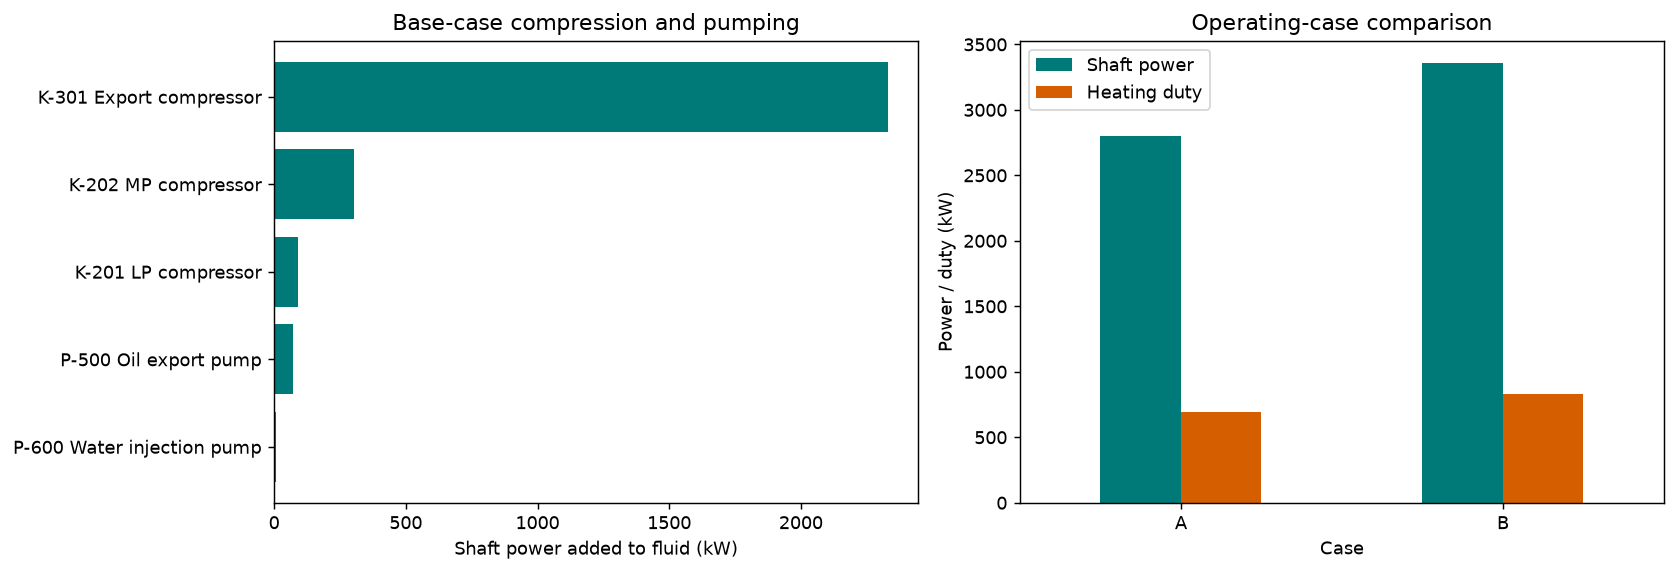

In [16]:
figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
base_machines = machine_table[machine_table["Case"] == "A"].sort_values("Shaft power (kW)")
axes[0].barh(base_machines["Tag"], base_machines["Shaft power (kW)"], color="#007A78")
axes[0].set_xlabel("Shaft power added to fluid (kW)")
axes[0].set_title("Base-case compression and pumping")
utility_table[["power_in_kw", "heating_kw"]].plot.bar(ax=axes[1], color=["#007A78", "#D55E00"])
axes[1].set_ylabel("Power / duty (kW)")
axes[1].set_title("Operating-case comparison")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(["Shaft power", "Heating duty"])
figure.tight_layout()
figure.savefig(OUTPUT / "power_and_case_comparison.png", dpi=180, bbox_inches="tight")
plt.show()


## 7. Conservation checks and independent engineering checks

For a steady boundary, with no accumulation:

$$\epsilon_m=\frac{|\sum\dot m_{out}-\sum\dot m_{in}|}{\sum\dot m_{in}}$$

Here $\dot m$ is mass flow in kg/h and $\epsilon_m$ is dimensionless. The same inventory test is
applied to each component. The energy residual, in kW, is:

$$R_E=\sum\dot H_{out}-\sum\dot H_{in}-\dot Q-\dot W$$

$\dot H$ is enthalpy flow, $\dot Q$ is external heat added and $\dot W$ is shaft work added.
The NeqSim reference enthalpy is arbitrary; only differences on a consistent basis are meaningful.

The report toolkit also checks every unit and area. Its **NOTE** category identifies documented
separator re-flash and recycle bookkeeping residuals; NOTE is displayed separately from PASS.
No failing check is silently relabelled.

In [17]:
balances = psr_balances.compute_balances(data)
balance_rows = []
for case in CASES:
    case_id = case["id"]
    overall = balances["cases"][case_id]["overall"]
    balance_rows.append({"Case": case_id, **overall})
balance_table = pd.DataFrame(balance_rows)
display(
    balance_table[
        [
            "Case",
            "mass_in_kg_h",
            "mass_out_kg_h",
            "mass_res_kg_h",
            "mass_rel",
            "energy_res_kw",
            "energy_rel",
            "mass_status",
            "energy_status",
        ]
    ]
)
print("Unit / area / overall balance check counts:", balances["summary"])
if balances["note_items"]:
    display(pd.DataFrame(balances["note_items"]))
if balances["fail_items"]:
    display(pd.DataFrame(balances["fail_items"]))
assert not balances["fail_items"], "Resolve failing conservation checks before reporting"


Unit / area / overall balance check counts: {'PASS': 272, 'FAIL': 0, 'NOTE': 6, 'N/A': 0}


,Case,mass_in_kg_h,mass_out_kg_h,mass_res_kg_h,mass_rel,energy_res_kw,energy_rel,mass_status,energy_status
0,A,120000.0,119999.947481,-0.052519,4.376568e-07,-13.957648,0.001370,PASS,NOTE
1,B,144000.0,144000.038996,0.038996,2.708082e-07,-16.762518,0.001371,PASS,NOTE


,case,level,id,check,residual,note
0,A,unit,CS-400 Dryer,energy_status,-13.966024,"component splitter: every outlet is re-flashed at the inlet temperature and pressure, so the energy residual is the implicit heat of the separation, not a closure error; equals 0.38 K of inlet heat-capacity flow"
1,A,area,A400 Dehydration,energy_status,-13.966024,explained by the bookkeeping residual of: CS-400 Dryer
2,A,overall,overall,energy_status,-13.957648,explained by the bookkeeping residual of: CS-400 Dryer
3,B,unit,CS-400 Dryer,energy_status,-16.759239,"component splitter: every outlet is re-flashed at the inlet temperature and pressure, so the energy residual is the implicit heat of the separation, not a closure error; equals 0.38 K of inlet heat-capacity flow"
4,B,area,A400 Dehydration,energy_status,-16.759239,explained by the bookkeeping residual of: CS-400 Dryer
5,B,overall,overall,energy_status,-16.762518,explained by the bookkeeping residual of: CS-400 Dryer


### Explicit heat reconciliation for the dryer package

The component splitter re-flashes its two outlet compositions at the specified pressure and
temperature. Water capture therefore has an **implicit separation heat**. The native reporting
skill retains that quantity as an energy **NOTE**, including its size. It is not an adiabatic
closure claim. We calculate the package heat from outlet minus inlet enthalpy flow and include
it as an additional heat term in a separate whole-facility reconciliation. Regeneration duty
and solvent circulation remain outside the model.

In [18]:
package_heat_rows = []
for case in CASES:
    case_id = case["id"]
    records = balances["cases"][case_id]
    dryer = next(unit for unit in records["units"] if unit["tag"] == "CS-400 Dryer")
    implied_heat = dryer["implied_energy_kw"]
    corrected_residual = records["overall"]["energy_res_kw"] - implied_heat
    assert abs(corrected_residual) < 1.0
    package_heat_rows.append(
        {
            "Case": case_id,
            "Implied isothermal package heat (kW)": implied_heat,
            "Energy residual after package heat (kW)": corrected_residual,
        }
    )
package_heat_table = pd.DataFrame(package_heat_rows)
display(package_heat_table.round(6))


,Case,Implied isothermal package heat (kW),Energy residual after package heat (kW)
0,A,-13.966024,0.008376
1,B,-16.759239,-0.003279


In [19]:
def component_mass_flow(stream, component_name):
    fluid = stream.getFluid()
    component = fluid.getPhase(0).getComponent(component_name)
    molar_flow = float(fluid.getFlowRate("mol/sec"))
    return molar_flow * float(component.getz()) * float(component.getMolarMass()) * 3600.0


independent_rows = []
for case in CASES:
    case_id = case["id"]
    result = solved_models[case_id]
    feeds = list(result["feeds"].values())
    products = list(result["products"].values())
    feed_mass = sum(float(stream.getFlowRate("kg/hr")) for stream in feeds)
    product_mass = sum(float(stream.getFlowRate("kg/hr")) for stream in products)
    component_errors = []
    for name in COMPOSITION:
        incoming = sum(component_mass_flow(stream, name) for stream in feeds)
        outgoing = sum(component_mass_flow(stream, name) for stream in products)
        component_errors.append(abs(outgoing - incoming) / feed_mass)
    relative_mass_error = abs(product_mass - feed_mass) / feed_mass
    max_component_error = max(component_errors)
    assert relative_mass_error < 1e-4
    assert max_component_error < 1e-4

    water_in_gas = component_mass_flow(
        result["objects"]["V-301 Export scrubber"].getGasOutStream(),
        "water",
    )
    water_out_gas = component_mass_flow(result["dryer"].getSplitStream(0), "water")
    assert 0.0 <= water_out_gas < water_in_gas
    for tag in ["K-201 LP compressor", "K-202 MP compressor", "K-301 Export compressor"]:
        unit = result["objects"][tag]
        assert float(unit.getPower("kW")) > 0.0
        assert float(unit.getOutletStream().getPressure()) > float(
            unit.getInletStream().getPressure()
        )

    independent_rows.append(
        {
            "Case": case_id,
            "Independent mass relative error": relative_mass_error,
            "Max component error / feed mass": max_component_error,
            "Water removed from gas (kg/h)": water_in_gas - water_out_gas,
            "Specified package water removal (%)": 100.0 * (1.0 - water_out_gas / water_in_gas),
        }
    )
independent_table = pd.DataFrame(independent_rows)
display(independent_table)


,Case,Independent mass relative error,Max component error / feed mass,Water removed from gas (kg/h),Specified package water removal (%)
0,A,4.376568e-07,1.853479e-07,22.265652,99.9
1,B,2.708082e-07,1.193004e-07,26.718799,99.9


An independent incompressible estimate checks the water-pump power:

$$\dot W_{hyd}\approx\frac{\dot V\Delta p}{\eta}$$

$\dot V$ is inlet actual volume flow in m³/s, $\Delta p$ is pressure rise in Pa and $\eta$ is
the assumed efficiency. The result is W. This checks units and power scale, rather than the
full compressible-fluid pump model or a vendor performance curve.

In [20]:
pump_check_rows = []
for case_id, result in solved_models.items():
    pump = result["objects"]["P-600 Water injection pump"]
    inlet = pump.getInletStream()
    inlet.getFluid().initProperties()
    volume_rate = float(inlet.getFlowRate("m3/sec"))
    pressure_rise = (float(pump.getOutletStream().getPressure()) - float(inlet.getPressure())) * 1e5
    estimate_kw = volume_rate * pressure_rise / 0.75 / 1000.0
    neqsim_kw = float(pump.getPower("kW"))
    relative_difference = abs(neqsim_kw - estimate_kw) / estimate_kw
    assert relative_difference < 0.10
    pump_check_rows.append(
        {
            "Case": case_id,
            "Hydraulic estimate (kW)": estimate_kw,
            "NeqSim (kW)": neqsim_kw,
            "Relative difference": relative_difference,
        }
    )
display(pd.DataFrame(pump_check_rows))


,Case,Hydraulic estimate (kW),NeqSim (kW),Relative difference
0,A,7.592055,7.592055,2.321507e-12
1,B,9.110462,9.110462,2.317531e-12


## 8. Prepare the professional reporting basis

The reporting skill requires a declared objective, audience, scope, assumptions, cases, acceptance
criteria and data gaps. A synthetic teaching basis can be fully specified while still being
labelled **SCREENING**. Equipment design approval and independent human review are not implied.

The following basis and standards register are written before report generation. The standards
register distinguishes diagram conventions from verified conformance; licensed standard texts
were not used for a clause-by-clause design review. NORSOK P-002 is recorded for applicability.

In [21]:
document = {
    "title": "Offshore oil and gas processing study",
    "subtitle": "Synthetic teaching facility - simulation, reports and flow diagrams",
    "document_number": "NS-OFF-REP-001",
    "revision": "A",
    "issue_status": "Educational screening example",
    "readiness": "SCREENING",
    "readiness_note": "Synthetic inputs; no design or construction approval",
    "readiness_explanation": "The workflow is demonstrated with declared, uncalibrated inputs.",
    "date": "2026-11-01",
    "company": "Educational example",
    "project": "NeqSim offshore reporting tutorial",
    "prepared_by": "NeqSim tutorial workflow",
    "checked_by": "not assigned",
    "approved_by": "not assigned",
    "revision_history": [
        {
            "rev": "A",
            "date": "2026-11-01",
            "description": "First executed teaching example",
            "by": "Tutorial workflow",
        }
    ],
}
basis = {
    "document": document,
    "basis_status": "draft",
    ("objective"): (
        "Demonstrate a traceable offshore process simulation and professional " "report workflow."
    ),
    "audience": "Process engineers, researchers and engineering students",
    "maturity": "Screening with synthetic inputs; no mechanical design qualification",
    "boundaries": {
        "included": [
            "HP-header inlet separation",
            "Oil stabilisation",
            "Gas recompression and export",
            "Specified dehydration-package water capture",
            "Oil export",
            "Water handling",
            "Fuel conditioning",
        ],
        "excluded": [
            "Reservoir, wells and subsea transport",
            "Detailed equipment and control design",
        ],
        "unmodelled_systems": [
            "Dryer regeneration",
            "Utility generation",
            "Flare hydraulics",
            "Water polishing",
            "Safety and control systems",
        ],
    },
    "operating_cases": [
        {key: case[key] for key in ["id", "label", "role", "description", "data_source"]}
        for case in CASES
    ],
    "acceptance_criteria": [
        {
            "id": "AC1",
            "text": "Overall mass closure better than one part in ten thousand",
            "source": "Teaching study basis",
            "requirement_class": "recommended",
            "check": {"metric": "overall_mass_rel", "max": 1e-4},
        },
        {
            "id": "AC2",
            "text": "Every component inventory closes against the boundary streams",
            "source": "Independent notebook component ledger",
            "requirement_class": "recommended",
        },
        {
            "id": "AC3",
            "text": "No failing report, topology or balance checks",
            "source": "NeqSim report validator",
            "requirement_class": "recommended",
        },
    ],
    "inspected_sources": [
        {
            "id": "M1",
            "kind": "model",
            "title": "Current NeqSim source and reporting toolkit",
            "version": source_sha,
            "status": "used",
            "used_for": "Simulation and report generation",
        },
        {
            "id": "D1",
            "kind": "operating_data",
            "title": "Declared synthetic fluid and cases",
            "version": "Notebook version 1.0.0",
            "status": "used",
            "used_for": "Teaching basis",
        },
    ],
    "model": {
        "name": "Synthetic offshore production facility",
        "version": source_sha,
        "simulator": "NeqSim source-built runtime with Python bridge 3.27.0",
        "eos": "SRK (SystemSrkEos)",
        ("eos_rationale"): (
            "Cubic EOS for a hydrocarbon screening study; dryer capture is an "
            "explicit performance assumption"
        ),
        "mixing_rule": "Classic mixing rule; NeqSim database interaction parameters",
        ("fluid_characterization"): (
            "Named pure components, including explicit heavy normal alkanes; " "untuned"
        ),
        ("convergence"): (
            "Shared ProcessSystem sweeps; stable boundary state and independent " "mass closure"
        ),
    },
    "conventions": {
        "units": "Temperature C; absolute pressure bara; flow kg/h and kmol/h; power and duty kW",
        "pressure": "All pressures are absolute; gauge pressure is not used",
        "composition_basis": "Mole fractions unless explicitly labelled as mass fractions",
        "standard_conditions": {
            "t_c": 15.0,
            "p_bara": 1.01325,
            "definition": "Flash volume at the stated reference conditions",
        },
        "phase_fraction_basis": "Mole fractions; mass and actual volume reported separately",
        "heat_sign": "Positive heat is added to fluid; cooler duty is negative",
        "work_sign": "Positive shaft work is added to fluid",
        "enthalpy_reference": "NeqSim common reference; use enthalpy differences",
    },
    "data_classification": [
        {
            "item": "Fluid and operating setpoints",
            "class": "specified",
            "note": "Synthetic teaching data",
        },
        {
            "item": "Equipment efficiencies and dryer water-capture fraction",
            "class": "estimated",
            "note": "Illustrative assumptions; no vendor guarantee",
        },
        {
            "item": "Flows, compositions, duties and powers",
            "class": "calculated",
            "note": "Extracted from live solved NeqSim models",
        },
        {
            "item": "Measured PVT and plant data",
            "class": "unavailable",
            "note": "No asset measurements or calibration data were supplied",
        },
    ],
    "assumptions": [
        {
            "id": "AS1",
            "text": "Steady state with equilibrium separation",
            "effect": "No residence-time, entrainment or transient performance prediction",
        },
        {
            "id": "AS2",
            "text": "Fixed equipment efficiencies and outlet setpoints",
            "effect": "Duty predictions do not establish mechanical capacity or operating envelope",
        },
        {
            "id": "AS3",
            "text": "The dehydration package uses a specified water-capture fraction",
            ("effect"): (
                "Regeneration and solvent behaviour are excluded; implied isothermal "
                "separation heat is reported"
            ),
        },
        {
            "id": "AS4",
            "text": "Separated water has no dispersed-oil or solids treatment model",
            "effect": "Water injection quality and discharge compliance cannot be inferred",
        },
    ],
    "exclusions": [
        "Mechanical sizing",
        "Vendor maps",
        "Dynamic controls",
        "Safety-system qualification",
    ],
    "data_gaps": [
        {
            "id": "G1",
            "item": "Asset PVT and production history",
            ("effect_on_conclusions"): (
                "The results demonstrate a workflow rather than plant accuracy"
            ),
            "mitigation": "Provide representative samples and independent validation measurements",
        },
        {
            "id": "G2",
            "item": "Equipment ratings and performance maps",
            "effect_on_conclusions": "Higher throughput does not establish spare capacity",
            "mitigation": "Add vendor data and pressure, temperature, power and map limits",
        },
        {
            "id": "G3",
            "item": "Product specifications and water-quality data",
            ("effect_on_conclusions"): (
                "Gas sales, oil export and water injection suitability remain open"
            ),
            ("mitigation"): (
                "Add dew-point, vapour-pressure, oil-in-water and injection-water " "criteria"
            ),
        },
    ],
    "known_balance_exceptions": [],
    "requirement_matrices": [],
    "process_description": {
        "A100 Inlet": "The topside HP-header boundary supplies a three-phase separator.",
        ("A200 Stabilisation"): (
            "Heated MP and LP flashes stabilise oil and receive scrubber " "condensate."
        ),
        ("A300 Gas recovery"): (
            "LP gas joins the MP header; recovered MP gas joins HP gas before "
            "export compression."
        ),
        ("A400 Dehydration"): (
            "A specified component split captures water before the sales and fuel " "branches."
        ),
        "A500 Oil export": "Oil is pumped and cooled to the declared export boundary.",
        ("A600 Produced water"): (
            "Separated water is collected and degassed before injection pumping."
        ),
        "A700 Fuel gas": "A fuel-gas branch is pressure-controlled, heated and scrubbed.",
    },
    "validation": {
        ("statement"): (
            "Conservation, connectivity, nearby-case and analytical pump-scale "
            "verification; no plant calibration"
        ),
        "rows": [],
    },
    "interpretation": [
        {
            "topic": "Power",
            ("text"): (
                "Rank machine duties on a common shaft-power basis before selecting "
                "improvement targets."
            ),
        },
        {
            "topic": "Operating cases",
            ("text"): (
                "Changed duties at fixed efficiency are scenario calculations, not "
                "capacity guarantees."
            ),
        },
        {
            "topic": "Cooling",
            ("text"): (
                "Cooling couples compressor suction conditions, hydrocarbon "
                "condensation and recycle flow."
            ),
        },
    ],
    "principal_findings": [
        "Base-case total shaft power is [[fact:power_total_A|.1f]] kW.",
        (
            "Higher-rate shaft power is [[fact:power_total_B|.1f]] kW at the "
            "declared scenario conditions."
        ),
        "All boundary service streams are retained in the heat and material balance.",
    ],
    "conclusions": [
        "The solved model supports a common data source for reports, tables and drawings."
    ],
    "recommendations": [
        "Replace synthetic inputs with measured PVT before making a project decision.",
        "Add equipment ratings and maps before interpreting throughput as capacity.",
    ],
    "references": ["NeqSim reporting and diagram skills at source commit " + source_sha],
    "figures": [],
    "bfd_blocks": [
        {
            "name": "Production and oil export",
            "areas": ["A100 Inlet", "A200 Stabilisation", "A500 Oil export"],
            "description": "Separation, stabilisation and oil pumping",
        },
        {
            "name": "Gas processing and fuel",
            "areas": ["A300 Gas recovery", "A400 Dehydration", "A700 Fuel gas"],
            "description": "Compression, dehydration and fuel conditioning",
        },
        {
            "name": "Produced-water handling",
            "areas": ["A600 Produced water"],
            "description": "Collection, degassing and injection pumping",
        },
    ],
    "diagram_notes": ["Synthetic inputs; steady state; pressures absolute; no design approval"],
    "tolerances": {},
    "standards_register_source": "Study register; official public catalogues checked 2026-11-01",
}

standards = []
for reference, title, edition, url, application in [
    (
        "ISO 10628-1",
        "Diagrams: specification of diagrams",
        "2014",
        "https://www.iso.org/standard/51840.html",
        "PFD content and drafting conventions",
    ),
    (
        "ISO 10628-2",
        "Diagrams: graphical symbols",
        "2012",
        "https://www.iso.org/standard/51841.html",
        "Schematic equipment symbols",
    ),
    (
        "NORSOK P-002",
        "Process system design",
        "2023+AC:2024",
        "https://standard.no/en/sectors/petroleum/norsok-standards/p-process/",
        "Applicability to offshore process design; requirements not assessed",
    ),
]:
    standards.append(
        {
            "reference": reference,
            "title": title,
            "edition": edition,
            "status": "Published edition listed by the issuing organisation",
            "source_url": url,
            "date_checked": "2026-11-01",
            "application": application,
            "requirement_class": "informative",
            "text_available": False,
            ("compliance_statement"): (
                "Catalogue and conventions only; no conformance or compliance claim"
            ),
            "deviations": "Full standard and project requirements were not assessed",
        }
    )

basis["package_heat_results"] = {
    row["Case"]: {
        "implied_heat_kw": row["Implied isothermal package heat (kW)"],
        "corrected_energy_residual_kw": row["Energy residual after package heat (kW)"],
    }
    for row in package_heat_rows
}
basis["interpretation"].append(
    {
        "topic": "Heat of specified drying",
        "text": "The isothermal dryer has a calculated heat term of "
        "[[basis:package_heat_results.A.implied_heat_kw|.3f]] kW in the base case. "
        "After including that heat, the facility energy residual is "
        "[[basis:package_heat_results.A.corrected_energy_residual_kw|.4f]] kW. "
        "The original energy NOTE is retained; regeneration energy is outside the model.",
    }
)
basis["equipment_notes"] = {
    "CS-400 Dryer": ["99.9% water capture", "Specified package performance"],
}

input_directory = OUTPUT / "study_inputs"
input_directory.mkdir(exist_ok=True)
for filename, payload in [
    ("basis.json", basis),
    ("standards_register.json", {"standards": standards}),
    ("cases.json", {"cases": CASES}),
]:
    (input_directory / filename).write_text(json.dumps(payload, indent=2))
basis_findings = psr_basis.check_basis(basis)
standard_findings = psr_basis.check_standards(standards)
assert not [item for item in basis_findings if item["level"] == "error"], basis_findings
assert not standard_findings, standard_findings
display(pd.DataFrame(basis["data_gaps"]))
display(pd.DataFrame(standards)[["reference", "edition", "date_checked", "compliance_statement"]])


,id,item,effect_on_conclusions,mitigation
0,G1,Asset PVT and production history,The results demonstrate a workflow rather than plant accuracy,Provide representative samples and independent validation measurements
1,G2,Equipment ratings and performance maps,Higher throughput does not establish spare capacity,"Add vendor data and pressure, temperature, power and map limits"
2,G3,Product specifications and water-quality data,"Gas sales, oil export and water injection suitability remain open","Add dew-point, vapour-pressure, oil-in-water and injection-water criteria"


,reference,edition,date_checked,compliance_statement
0,ISO 10628-1,2014,2026-11-01,Catalogue and conventions only; no conformance or compliance claim
1,ISO 10628-2,2012,2026-11-01,Catalogue and conventions only; no conformance or compliance claim
2,NORSOK P-002,2023+AC:2024,2026-11-01,Catalogue and conventions only; no conformance or compliance claim


## 9. Generate the report with the NeqSim reporting skill

This is the public Python equivalent of:

```text
neqsim process-report offshore_study_deliverables/process_report/data/process_data.json \
    --basis offshore_study_deliverables/study_inputs/basis.json \
    --standards offshore_study_deliverables/study_inputs/standards_register.json \
    --out regenerated_report --no-word
```

`use_word=False` means **no Microsoft Word automation**. The toolkit still creates the DOCX
report, tables, workbook, BFD and PFD PDFs. A Word-exported report PDF is not required by Colab.

In [22]:
import psr_diagrams
import pfd_layout_check

# Keep labels readable; allow the generator to split a dense area over more sheets.
psr_diagrams.SCALES = (1.5, 1.3, 1.15, 1.0)
psr_diagrams.MIN_SCALE = 1.0
psr_diagrams.PORT_PITCH = 7.0

# Account for the whole external driver label when allocating its drawing footprint.
original_extra_width = getattr(
    psr_diagrams, "_offshore_original_extra_width", psr_diagrams._Sym.extra_width
)
psr_diagrams._offshore_original_extra_width = original_extra_width
original_bfd_row_graph = getattr(
    psr_diagrams, "_offshore_original_bfd_row_graph", psr_diagrams._bfd_row_graph
)
psr_diagrams._offshore_original_bfd_row_graph = original_bfd_row_graph


def driver_footprint_width(symbol):
    if symbol.extra == "power":
        return max(
            psr_diagrams.text_w("driver (not modelled)", psr_diagrams.DESC_FS),
            2.0 * (3.3 + psr_diagrams.text_w("shaft power", psr_diagrams.DESC_FS)),
        )
    return original_extra_width(symbol)


psr_diagrams._Sym.extra_width = driver_footprint_width


def spaced_bfd_row_graph(*arguments, **keywords):
    nodes, edges = original_bfd_row_graph(*arguments, **keywords)
    for node in nodes:
        if node.kind == "block":
            node.above += 4.0
            node.below += 4.0
    return nodes, edges


psr_diagrams._bfd_row_graph = spaced_bfd_row_graph

# A crossing has no junction unless a dot is drawn. Condensate return and parallel
# product branches are retained, so a few non-connecting crossings can be necessary.
PHYSICAL_LAYOUT_NOTES = {
    "CROSSING": "Separate services cross without connection; only explicit dots are junctions.",
    "WHITESPACE_POCKET": "Branch separation and off-page corridors retain the physical topology.",
    "SMALL_CONTENT": "A separately numbered area sheet retains only the equipment in its scope.",
    "PRODUCT_POSITION": (
        "The overview wraps over two rows; boundary outlets follow "
        "their local section flow direction."
    ),
}
original_review_diagram_layout = process_study_report.review_diagram_layout


def review_with_physical_notes(bfd, pfd, review_directory):
    paths = [bfd["svg"]] + [sheet["svg"] for sheet in pfd["sheets"]]
    specs = []
    Path(review_directory).mkdir(parents=True, exist_ok=True)
    for path in paths:
        spec = pfd_layout_check.load_svg(path, kind="pfd")
        for node in spec["nodes"]:
            for text in node.get("texts", []):
                if text["text"] == "shaft power":
                    text["kind"] = "subtitle"
        spec["waivers"] = [
            {"code": code, "reason": reason} for code, reason in PHYSICAL_LAYOUT_NOTES.items()
        ]
        spec_path = Path(review_directory) / (Path(path).stem + ".layout.json")
        spec_path.write_text(json.dumps(spec, indent=2))
        specs.append(str(spec_path))
    reviews = pfd_layout_check.review_many(specs, review_directory, kind="pfd")
    counts = {
        status: sum(review.status == status for _, review in reviews)
        for status in ["PASS", "WARN", "FAIL"]
    }
    return {
        "status": pfd_layout_check.worst_status(reviews),
        "sheets": len(reviews),
        "counts": counts,
        "dir": str(review_directory),
    }


process_study_report.review_diagram_layout = review_with_physical_notes

import ppo_layout


def readable_mass_flow(kg_h):
    if kg_h is None:
        return None
    if 0.0 < abs(kg_h) < 0.001:
        return "<0.001 kg/h"
    if abs(kg_h) >= 1000.0:
        return f"{kg_h / 1000.0:.1f} t/h"
    return f"{kg_h:.3g} kg/h"


ppo_layout._fmt_mass = readable_mass_flow

original_overview_spec = getattr(ppo_layout, "_offshore_original_spec", ppo_layout.to_layout_spec)
ppo_layout._offshore_original_spec = original_overview_spec


def overview_spec_with_physical_notes(*arguments, **keywords):
    spec = original_overview_spec(*arguments, **keywords)
    spec["waivers"] = [
        {"code": code, "reason": reason} for code, reason in PHYSICAL_LAYOUT_NOTES.items()
    ]
    return spec


ppo_layout.to_layout_spec = overview_spec_with_physical_notes

# Issue only the requested overview slides; detailed equipment remains on A3 PFDs.
import ppo_validate

original_overview_export = getattr(
    process_overview, "_offshore_original_export", process_overview._export
)
process_overview._offshore_original_export = original_overview_export
original_overview_validation = getattr(
    ppo_validate, "_offshore_original_validate", ppo_validate.validate
)
ppo_validate._offshore_original_validate = original_overview_validation


def export_requested_variants(scene, fonts, out_dir, name, *arguments):
    if name.startswith("overview_16x9_detail_"):
        return {
            suffix: str(Path(out_dir) / (name + "." + suffix)) for suffix in ["svg", "pdf", "png"]
        }
    return original_overview_export(scene, fonts, out_dir, name, *arguments)


def validate_issued_variants(graph, data, layouts, files, fonts, problems, *arguments):
    excluded = []
    for name in list(files):
        if name.startswith("overview_16x9_detail_"):
            excluded.append(name)
            for suffix in ["svg", "pdf", "png"]:
                Path(files[name][suffix]).unlink(missing_ok=True)
            del files[name]
    layouts["16x9_supporting"] = []
    record = original_overview_validation(graph, data, layouts, files, fonts, problems, *arguments)
    record["excluded_optional_variants"] = excluded
    record["limitations"].append(
        "Optional supporting detail slides are not issued; use the complete A3 PFD drawing set."
    )
    return record


process_overview._export = export_requested_variants
ppo_validate.validate = validate_issued_variants
print(
    "Diagram style: full-size labels and separated ports; physical notes retained in review JSON."
)


Diagram style: full-size labels and separated ports; physical notes retained in review JSON.


In [23]:
report_summary = process_study_report.run_pipeline(
    data,
    basis,
    standards,
    str(OUTPUT / "process_report"),
    use_word=False,
    max_units_per_sheet=6,
    allow_fail=True,
)
validation = json.loads(Path(report_summary["validation_json"]).read_text())
display(pd.DataFrame(validation["checks"])[["id", "status", "detail"]])
print("Report validation:", validation["status"])
print("Report:", report_summary["docx"])
print("Diagram layout:", report_summary["diagrams"]["layout_review"])
assert validation["n_fail"] == 0, "Resolve report validation failures before issue"


Report validation: PASS WITH WARNINGS
Report: /workspace/scratch/173328b47b0e/offshore_study_deliverables/process_report/report/NS-OFF-REP-001_revA.docx
Diagram layout: {'status': 'PASS', 'sheets': 12, 'counts': {'PASS': 12, 'WARN': 0, 'FAIL': 0}, 'dir': '/workspace/scratch/173328b47b0e/offshore_study_deliverables/process_report/diagrams/layout_review'}


,id,status,detail
0,BASIS-COMPLETE,PASS,no findings
1,STD-REGISTER,PASS,3 standards registered
2,BASIS-STATUS,WARN,draft basis: 0 items marked TO BE CONFIRMED; readiness must stay SCREENING until a person confirms the basis
3,STD-VERIFY,PASS,all rows checked within 90 days
4,BASIS-STDCOND-MATCH,PASS,"data {'t_c': 15.0, 'p_bara': 1.01325} vs basis {'t_c': 15.0, 'p_bara': 1.01325, 'definition': 'Flash volume at the stated reference conditions'}"
5,DATA-CASES,PASS,"56 streams x 2 cases, 41 units"
6,DATA-TOPOLOGY,PASS,duplicate ids 0; bad references []
7,DATA-MULTICONSUMER,PASS,none
8,DATA-LABELS,PASS,
9,TOPO-CONNECTIVITY,PASS,all 41 units connected


## 10. Inspect the BFD and every detailed PFD

These are generated from the solved topology. Equipment tags and numbered streams refer directly
to the report tables. Off-page connections identify the destination sheets. The mandatory
`pfd-layout-review` gate runs in the reporting pipeline; its findings remain in the package.

**bfd_001.png**

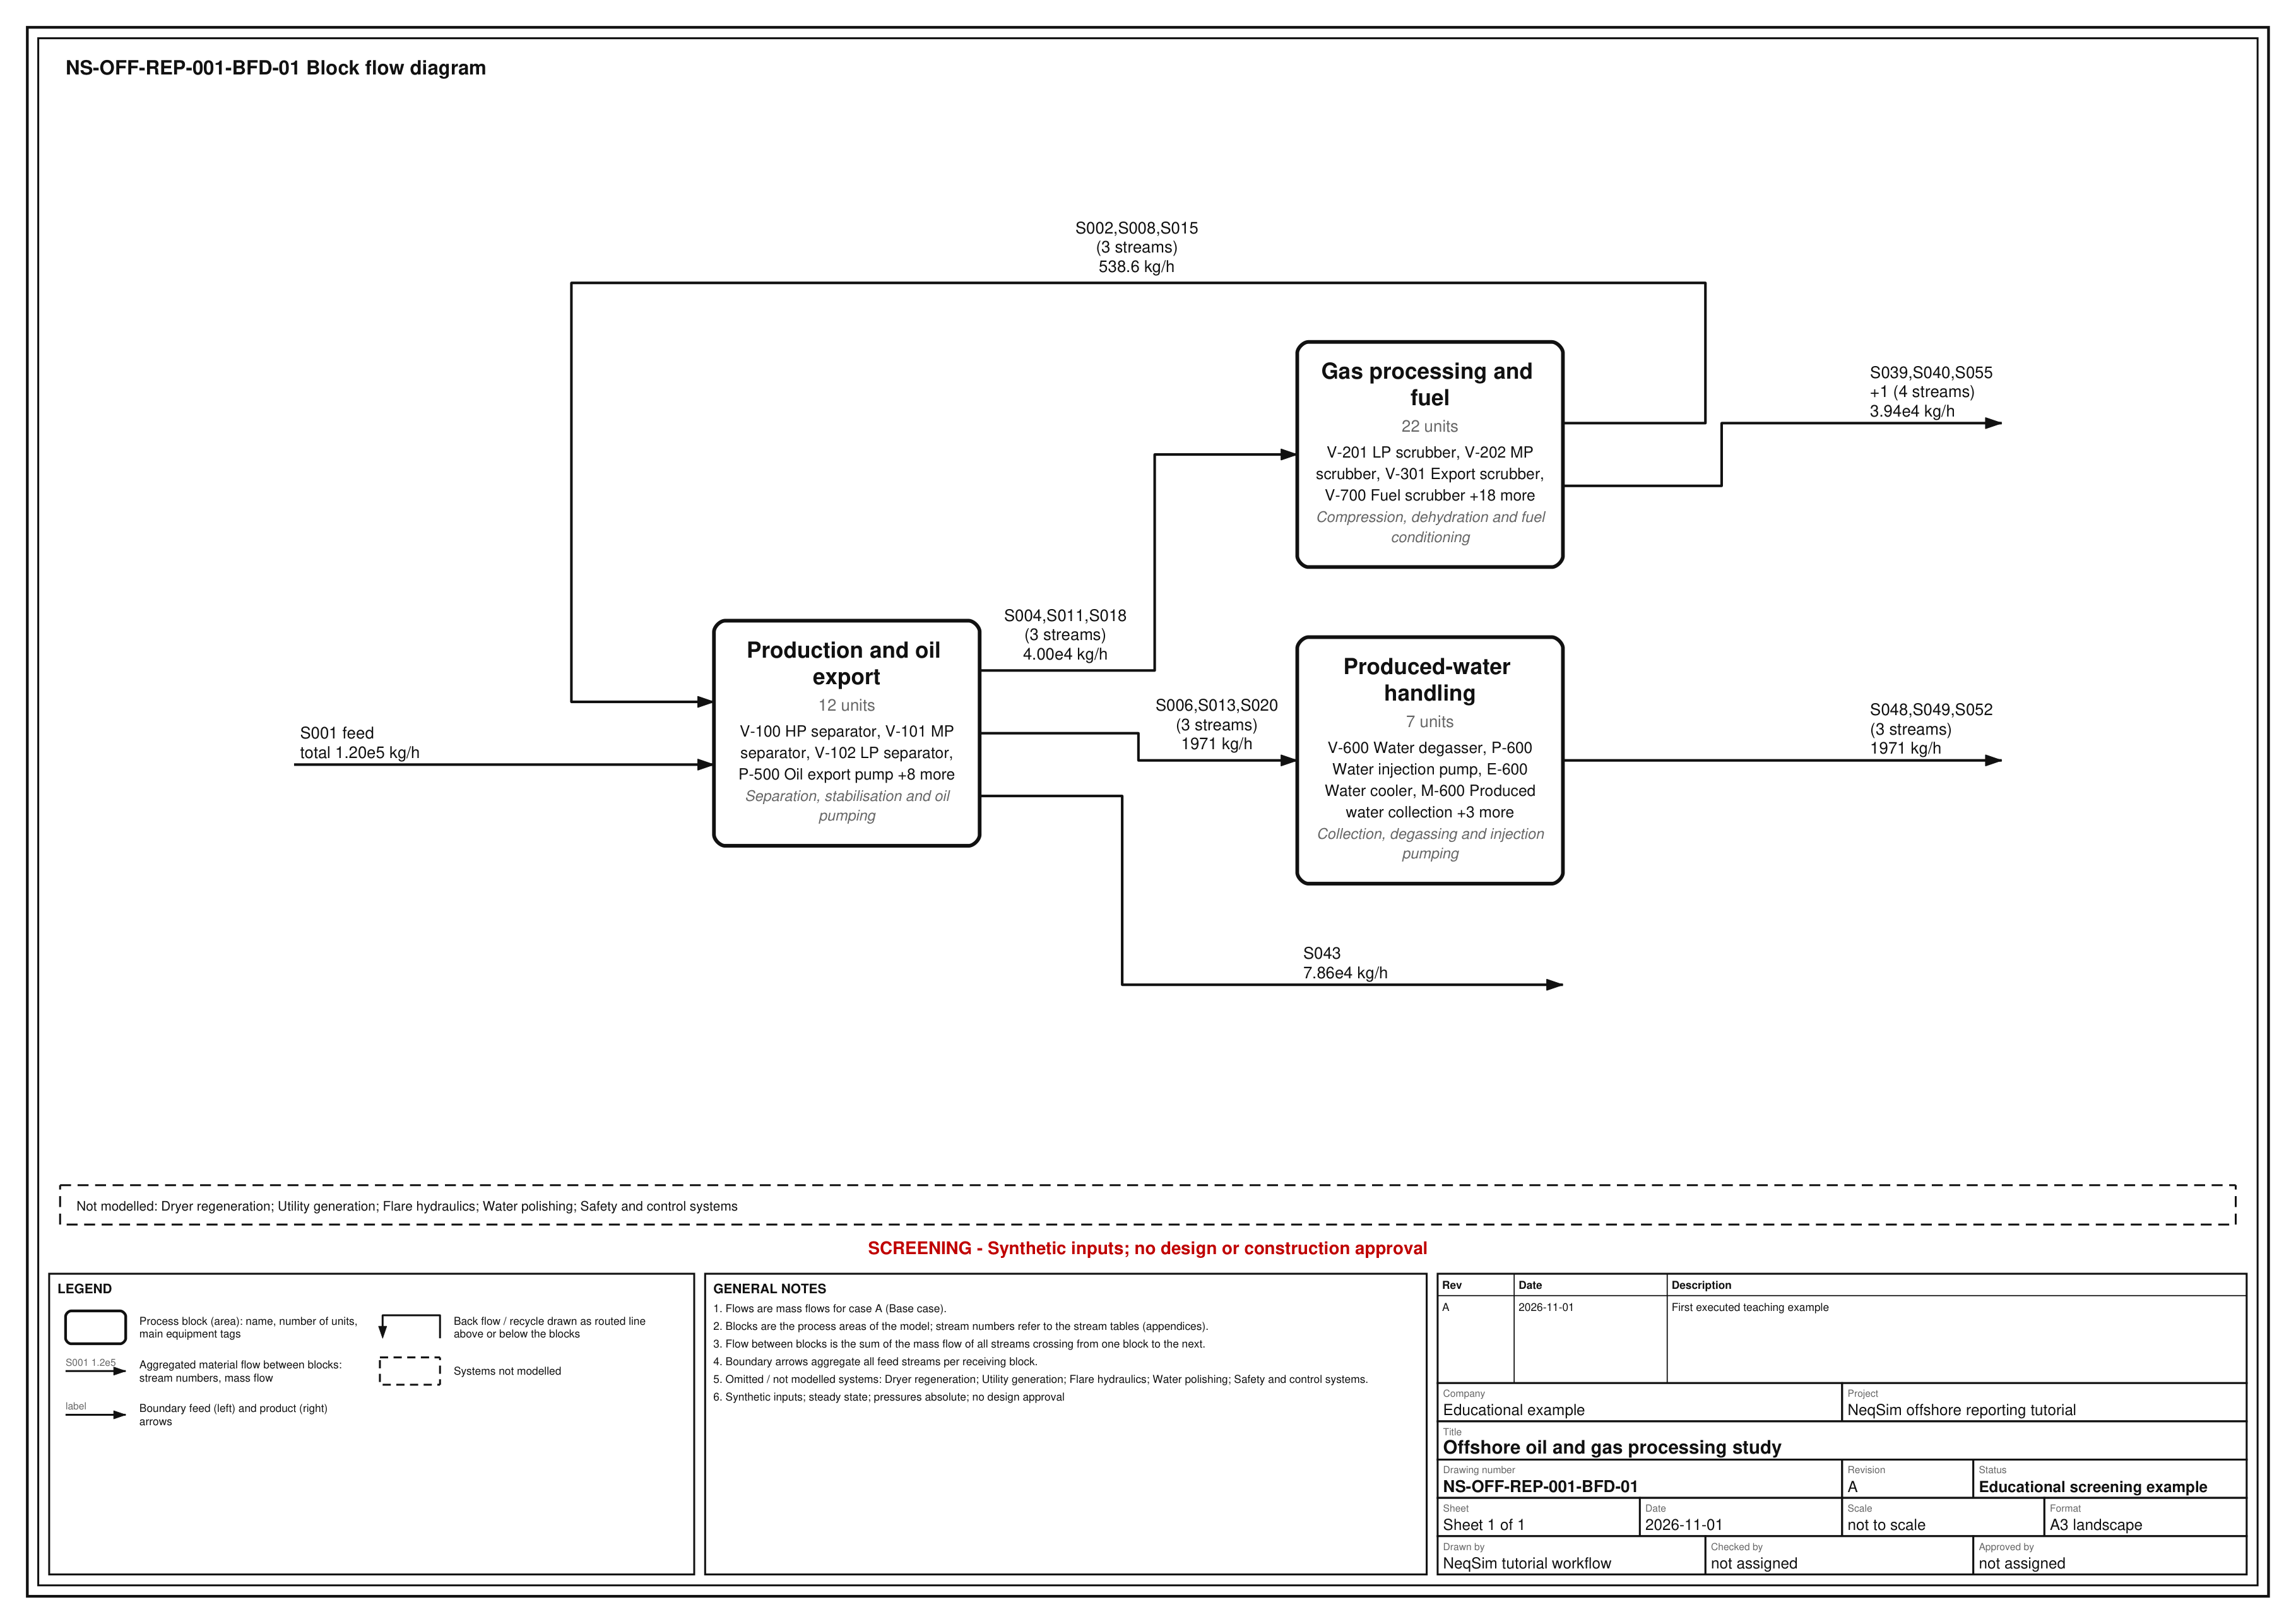

**pfd_001.png**

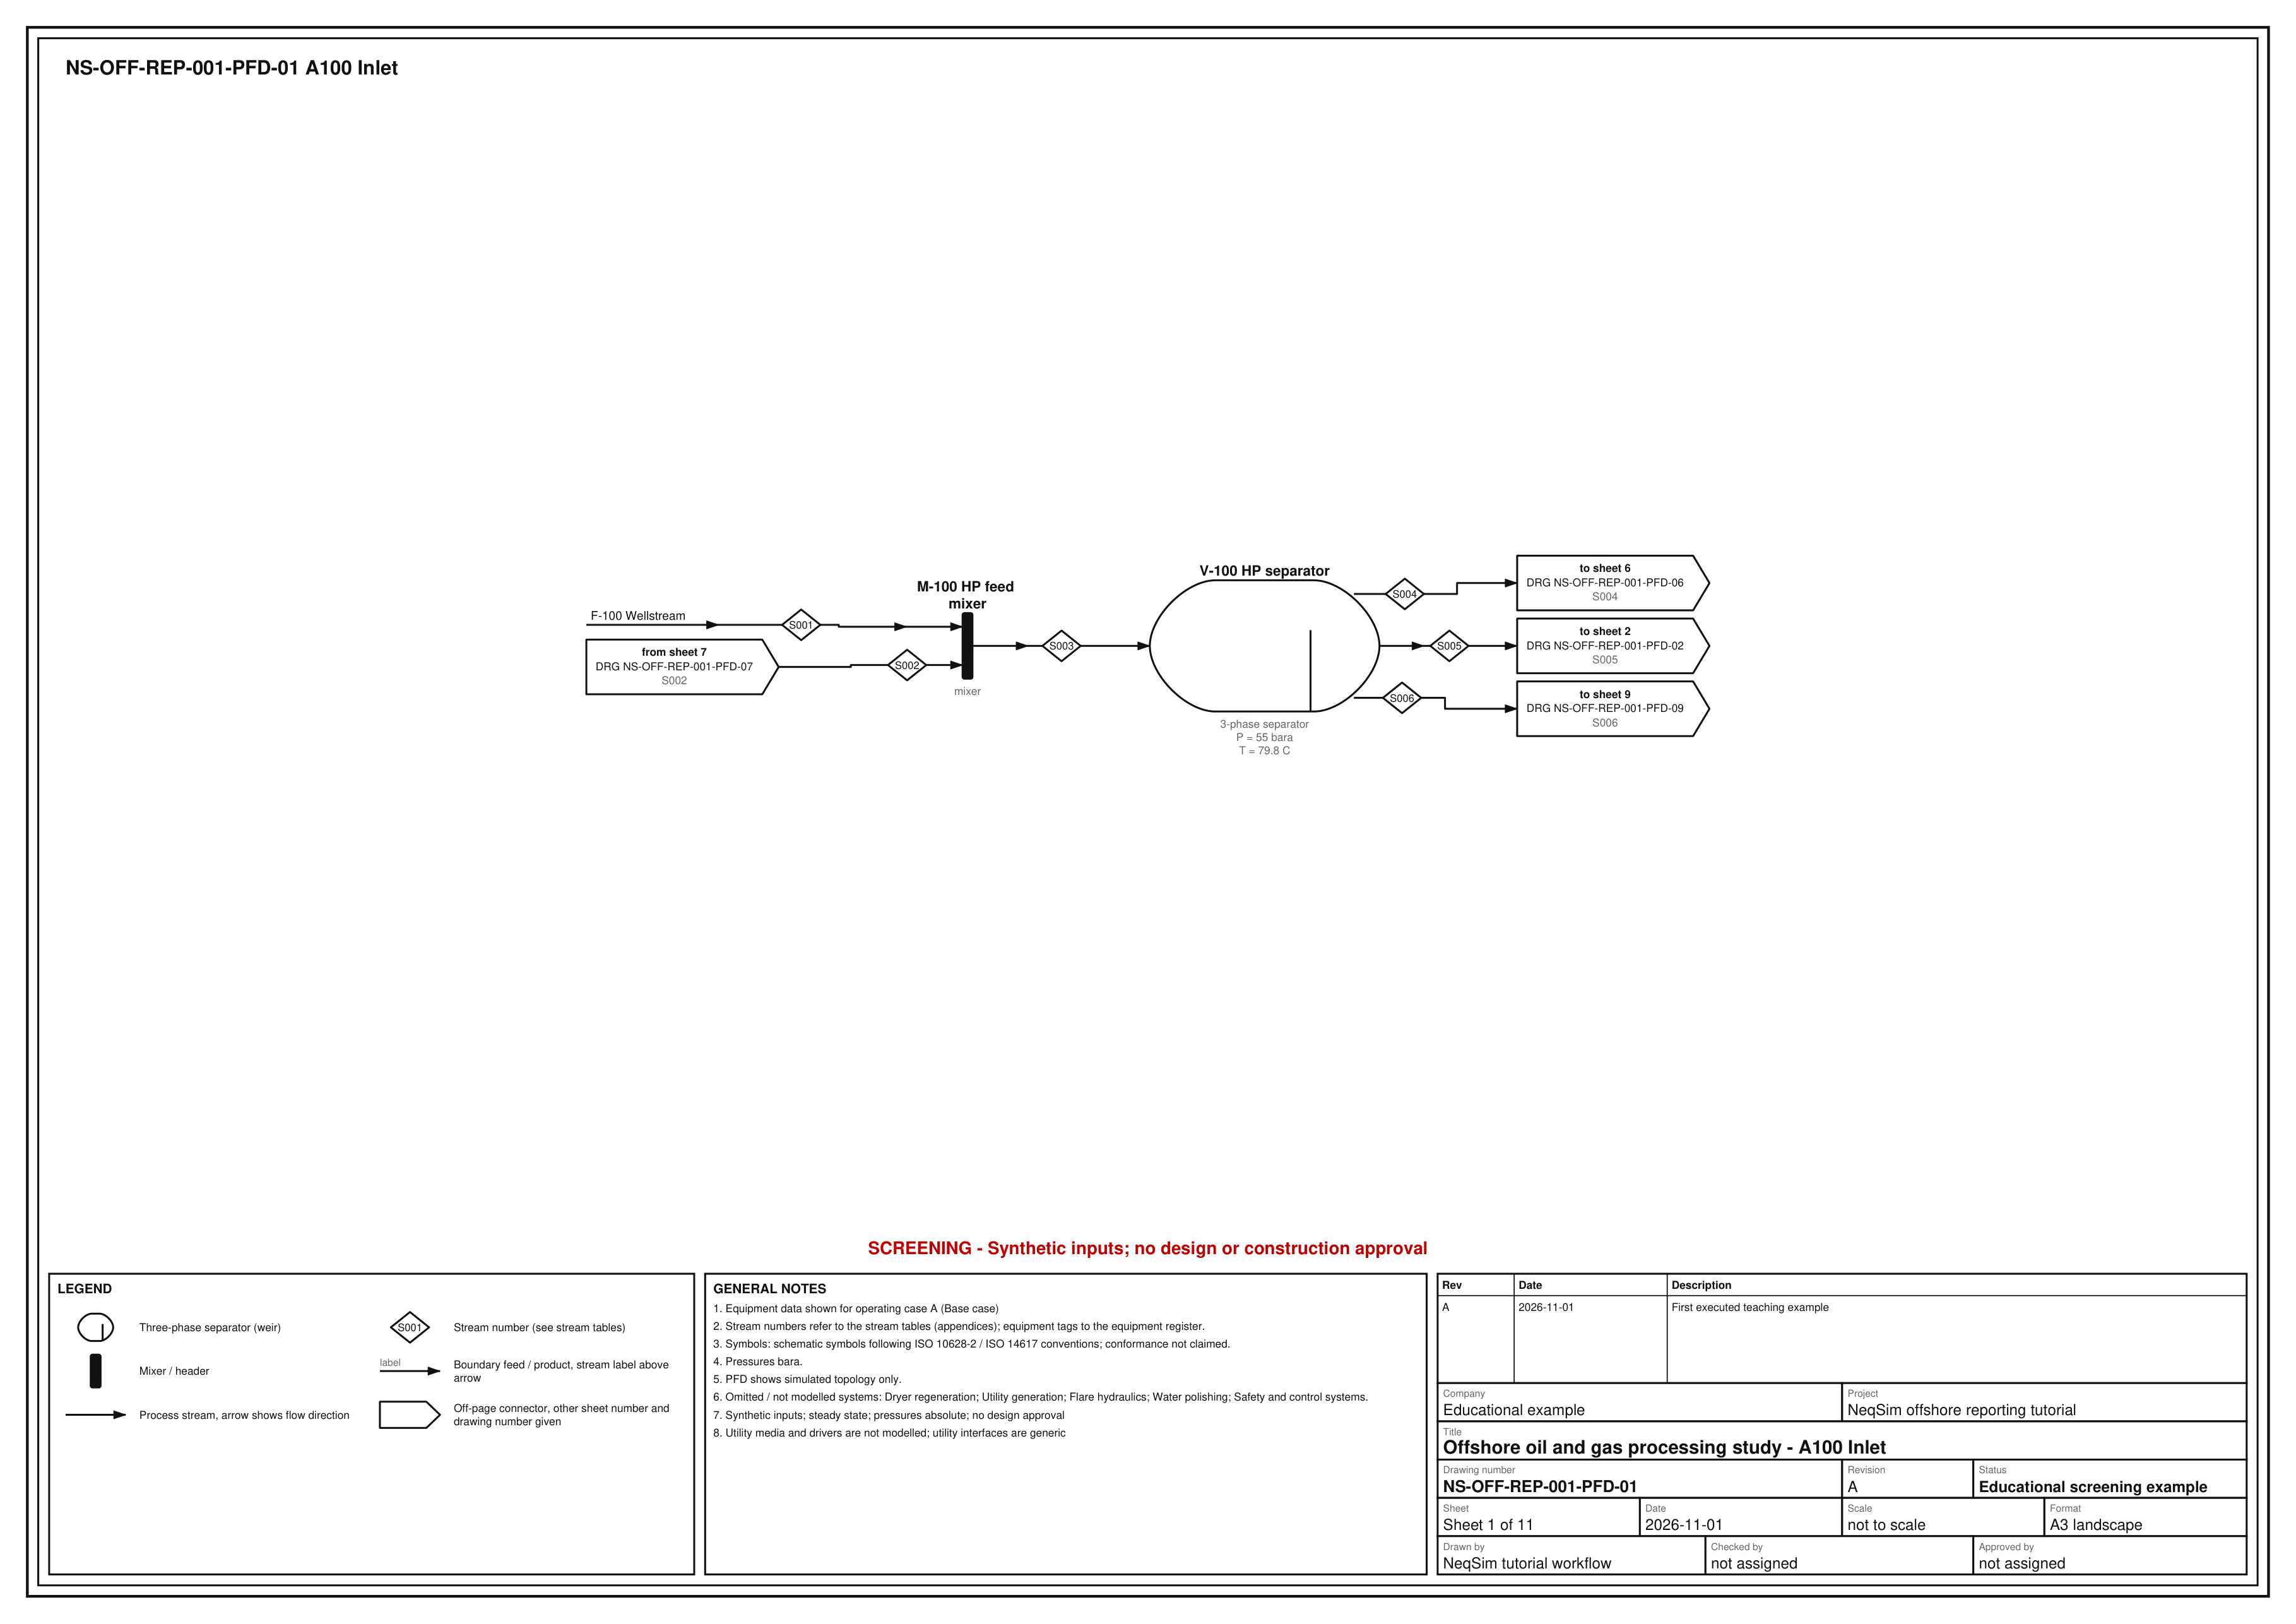

**pfd_002.png**

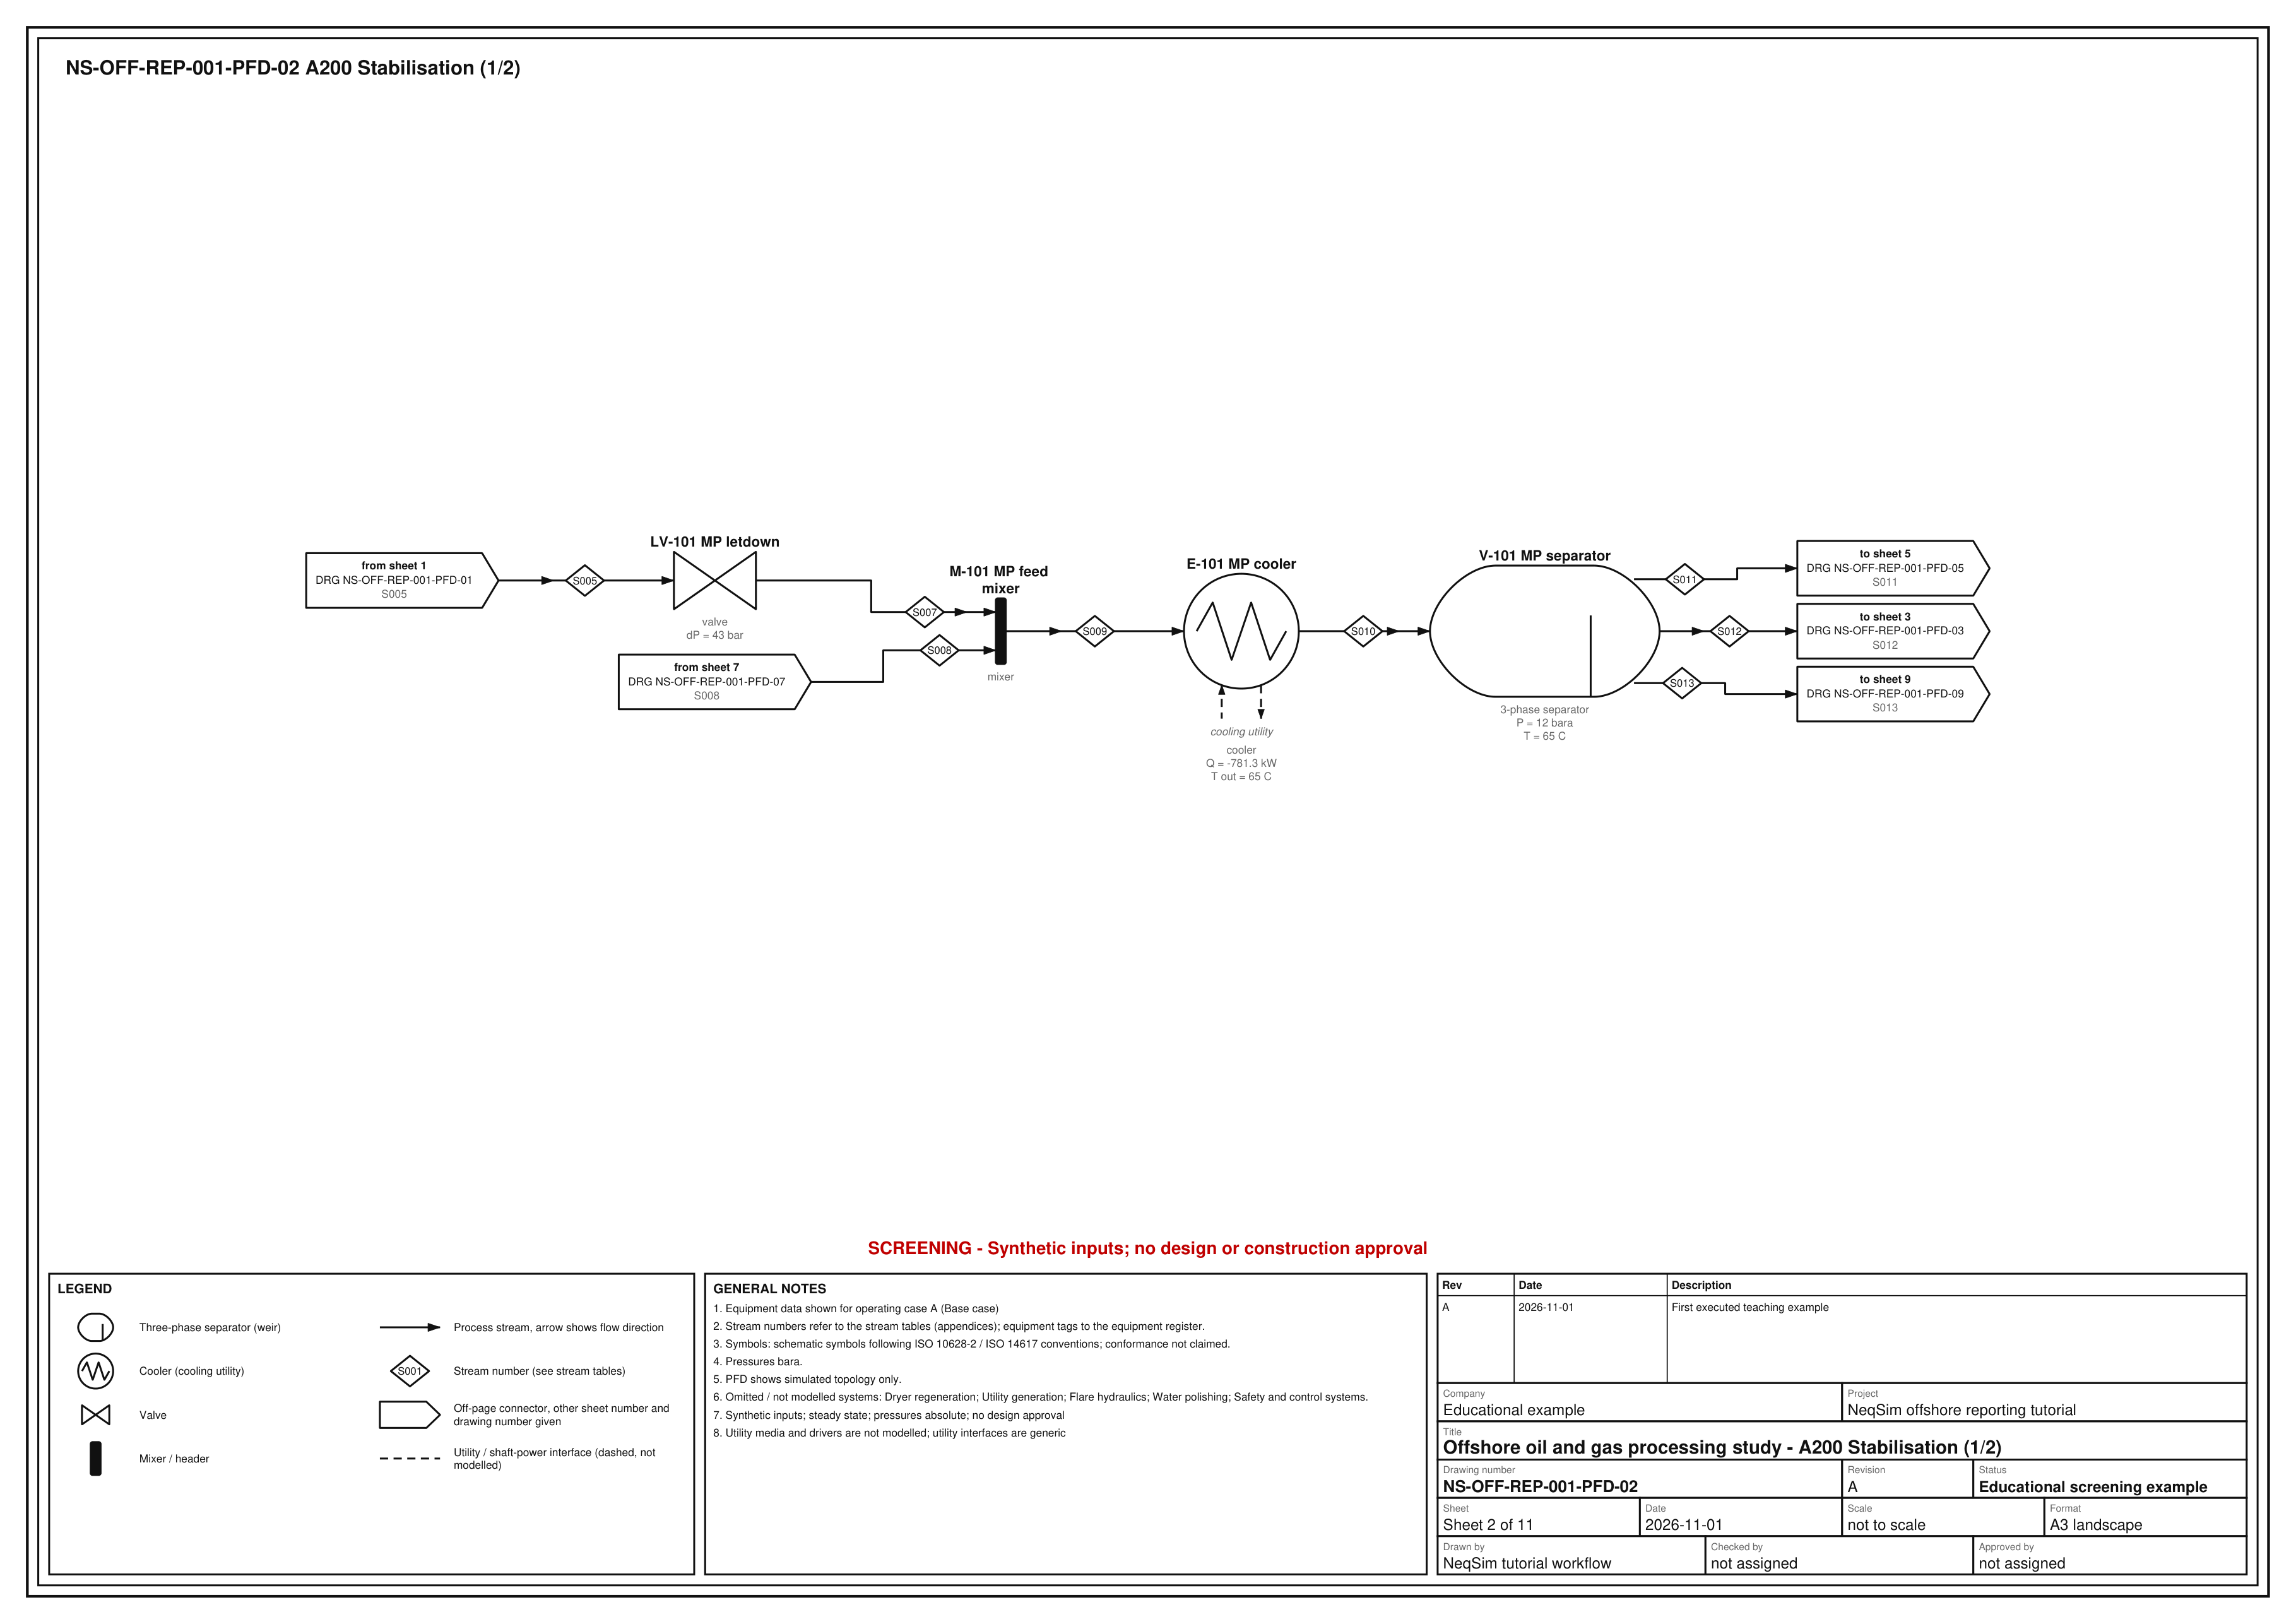

**pfd_003.png**

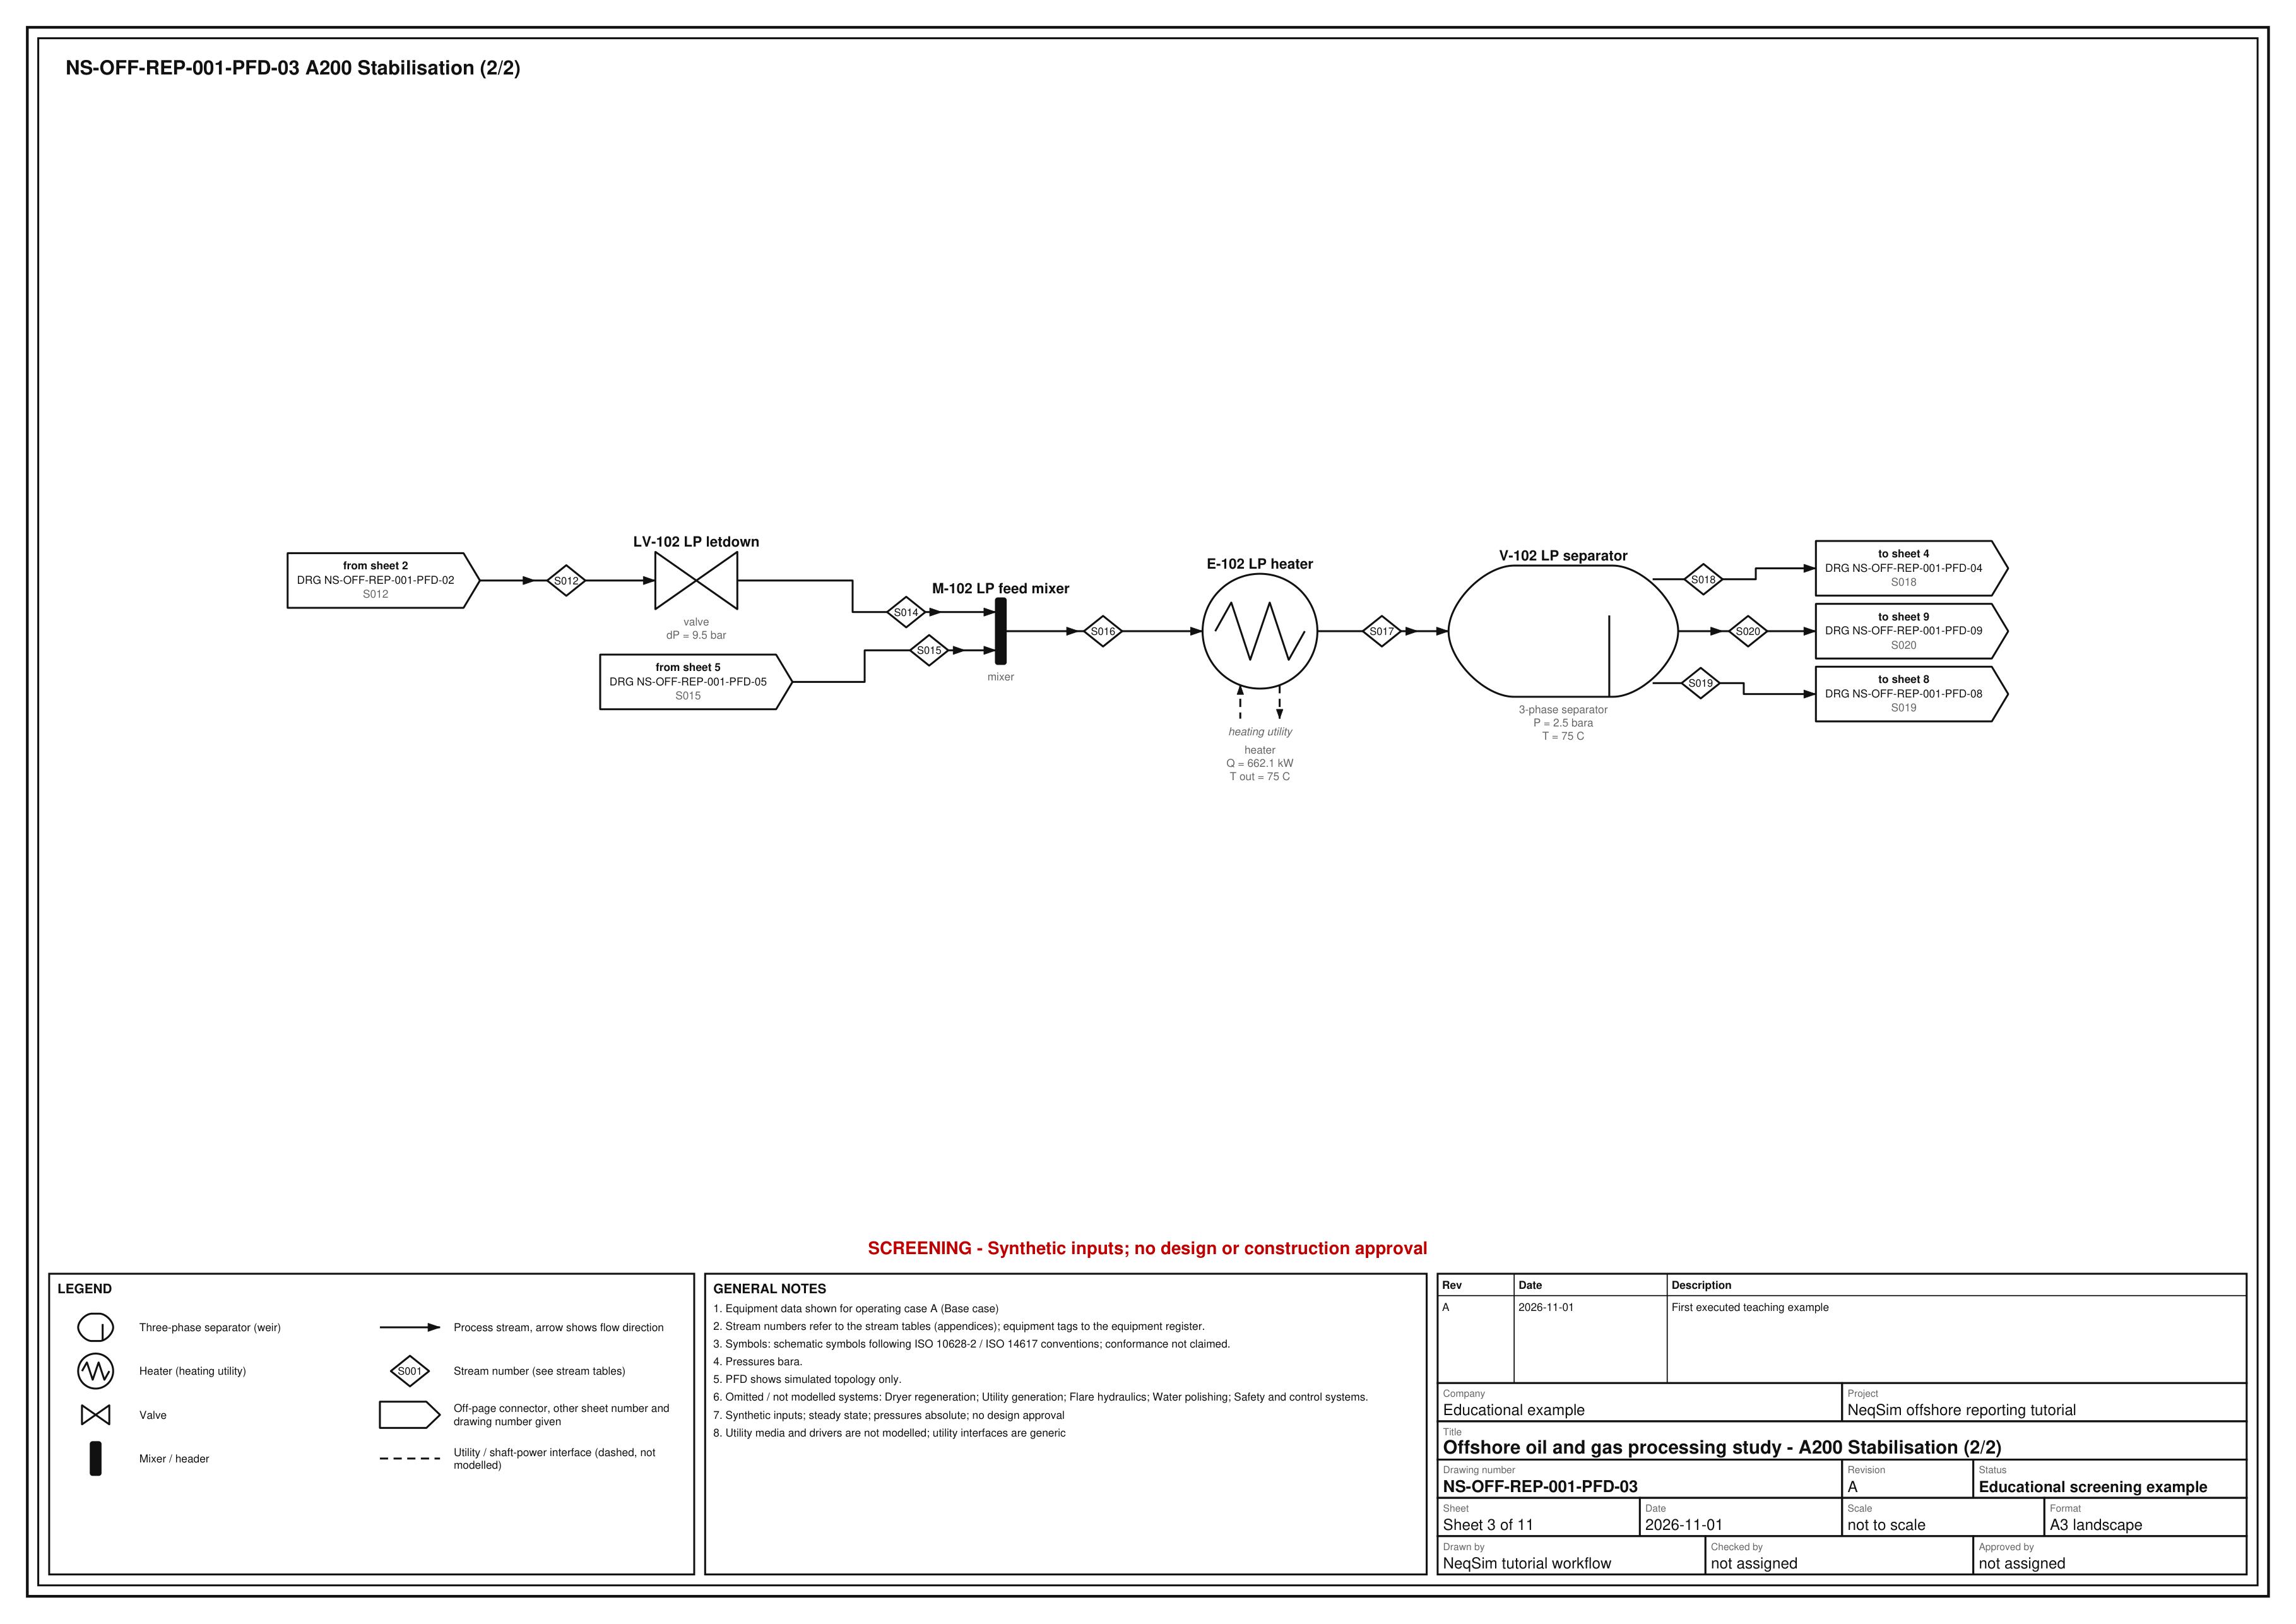

**pfd_004.png**

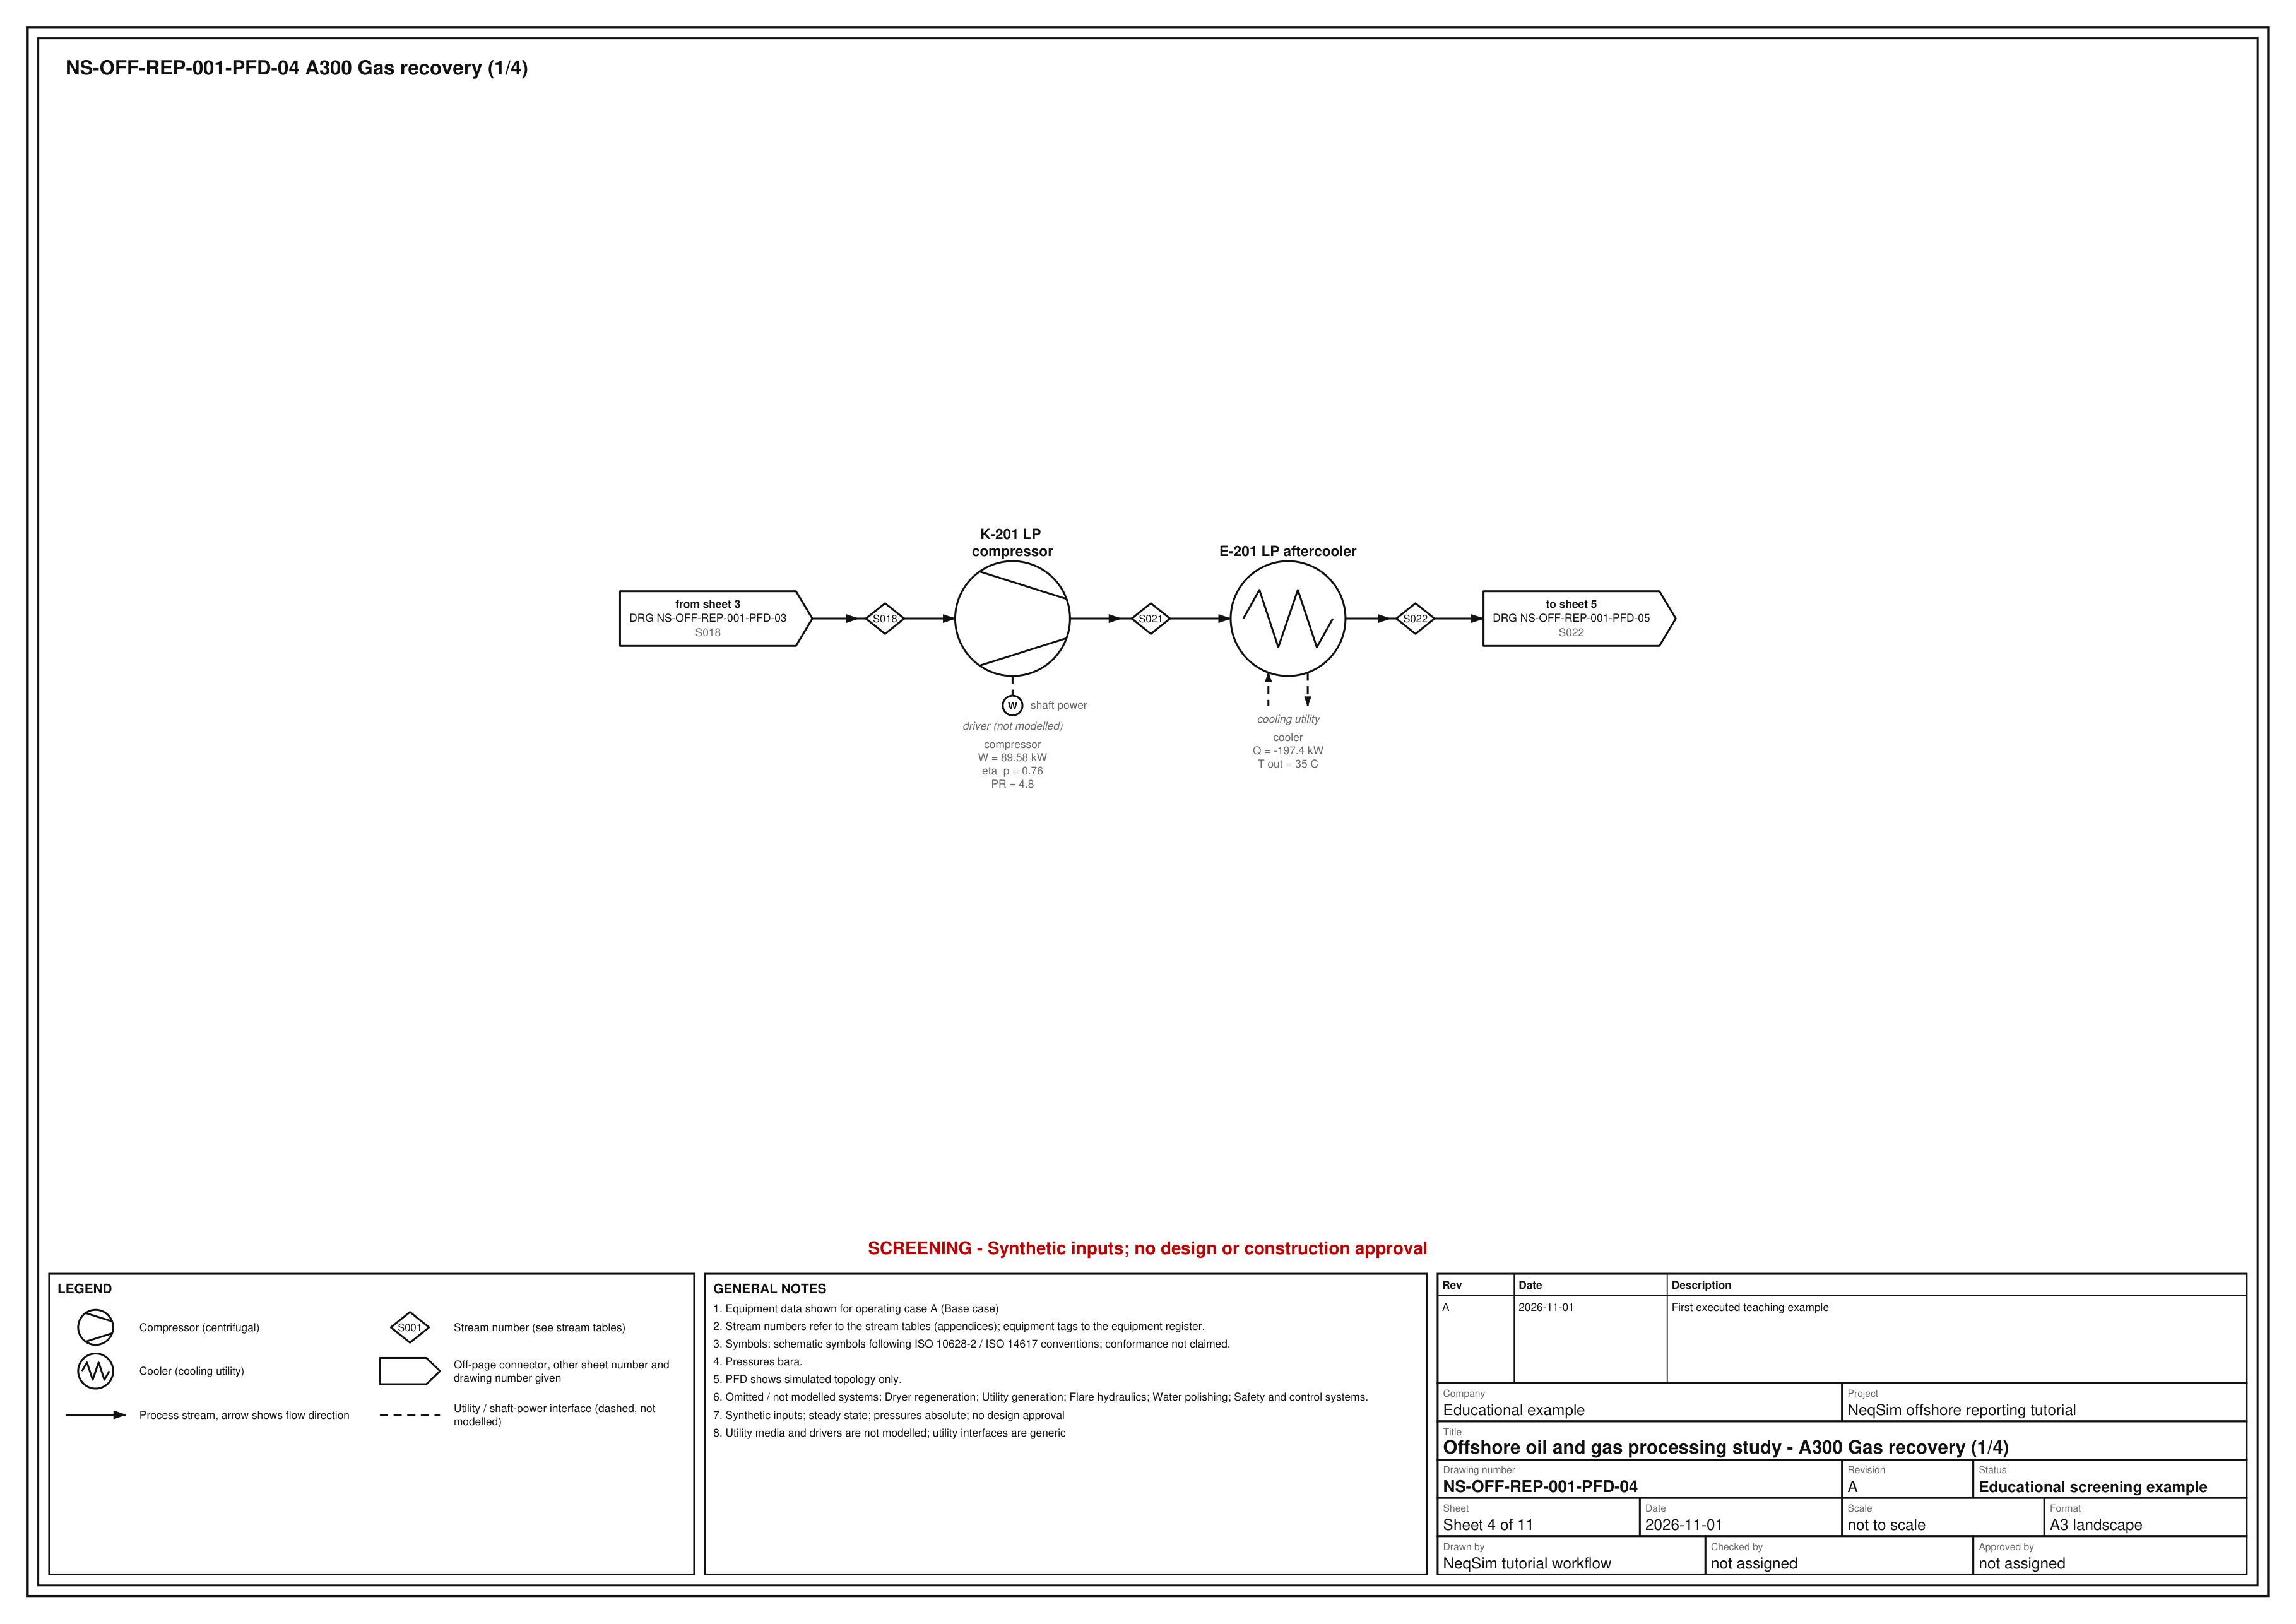

**pfd_005.png**

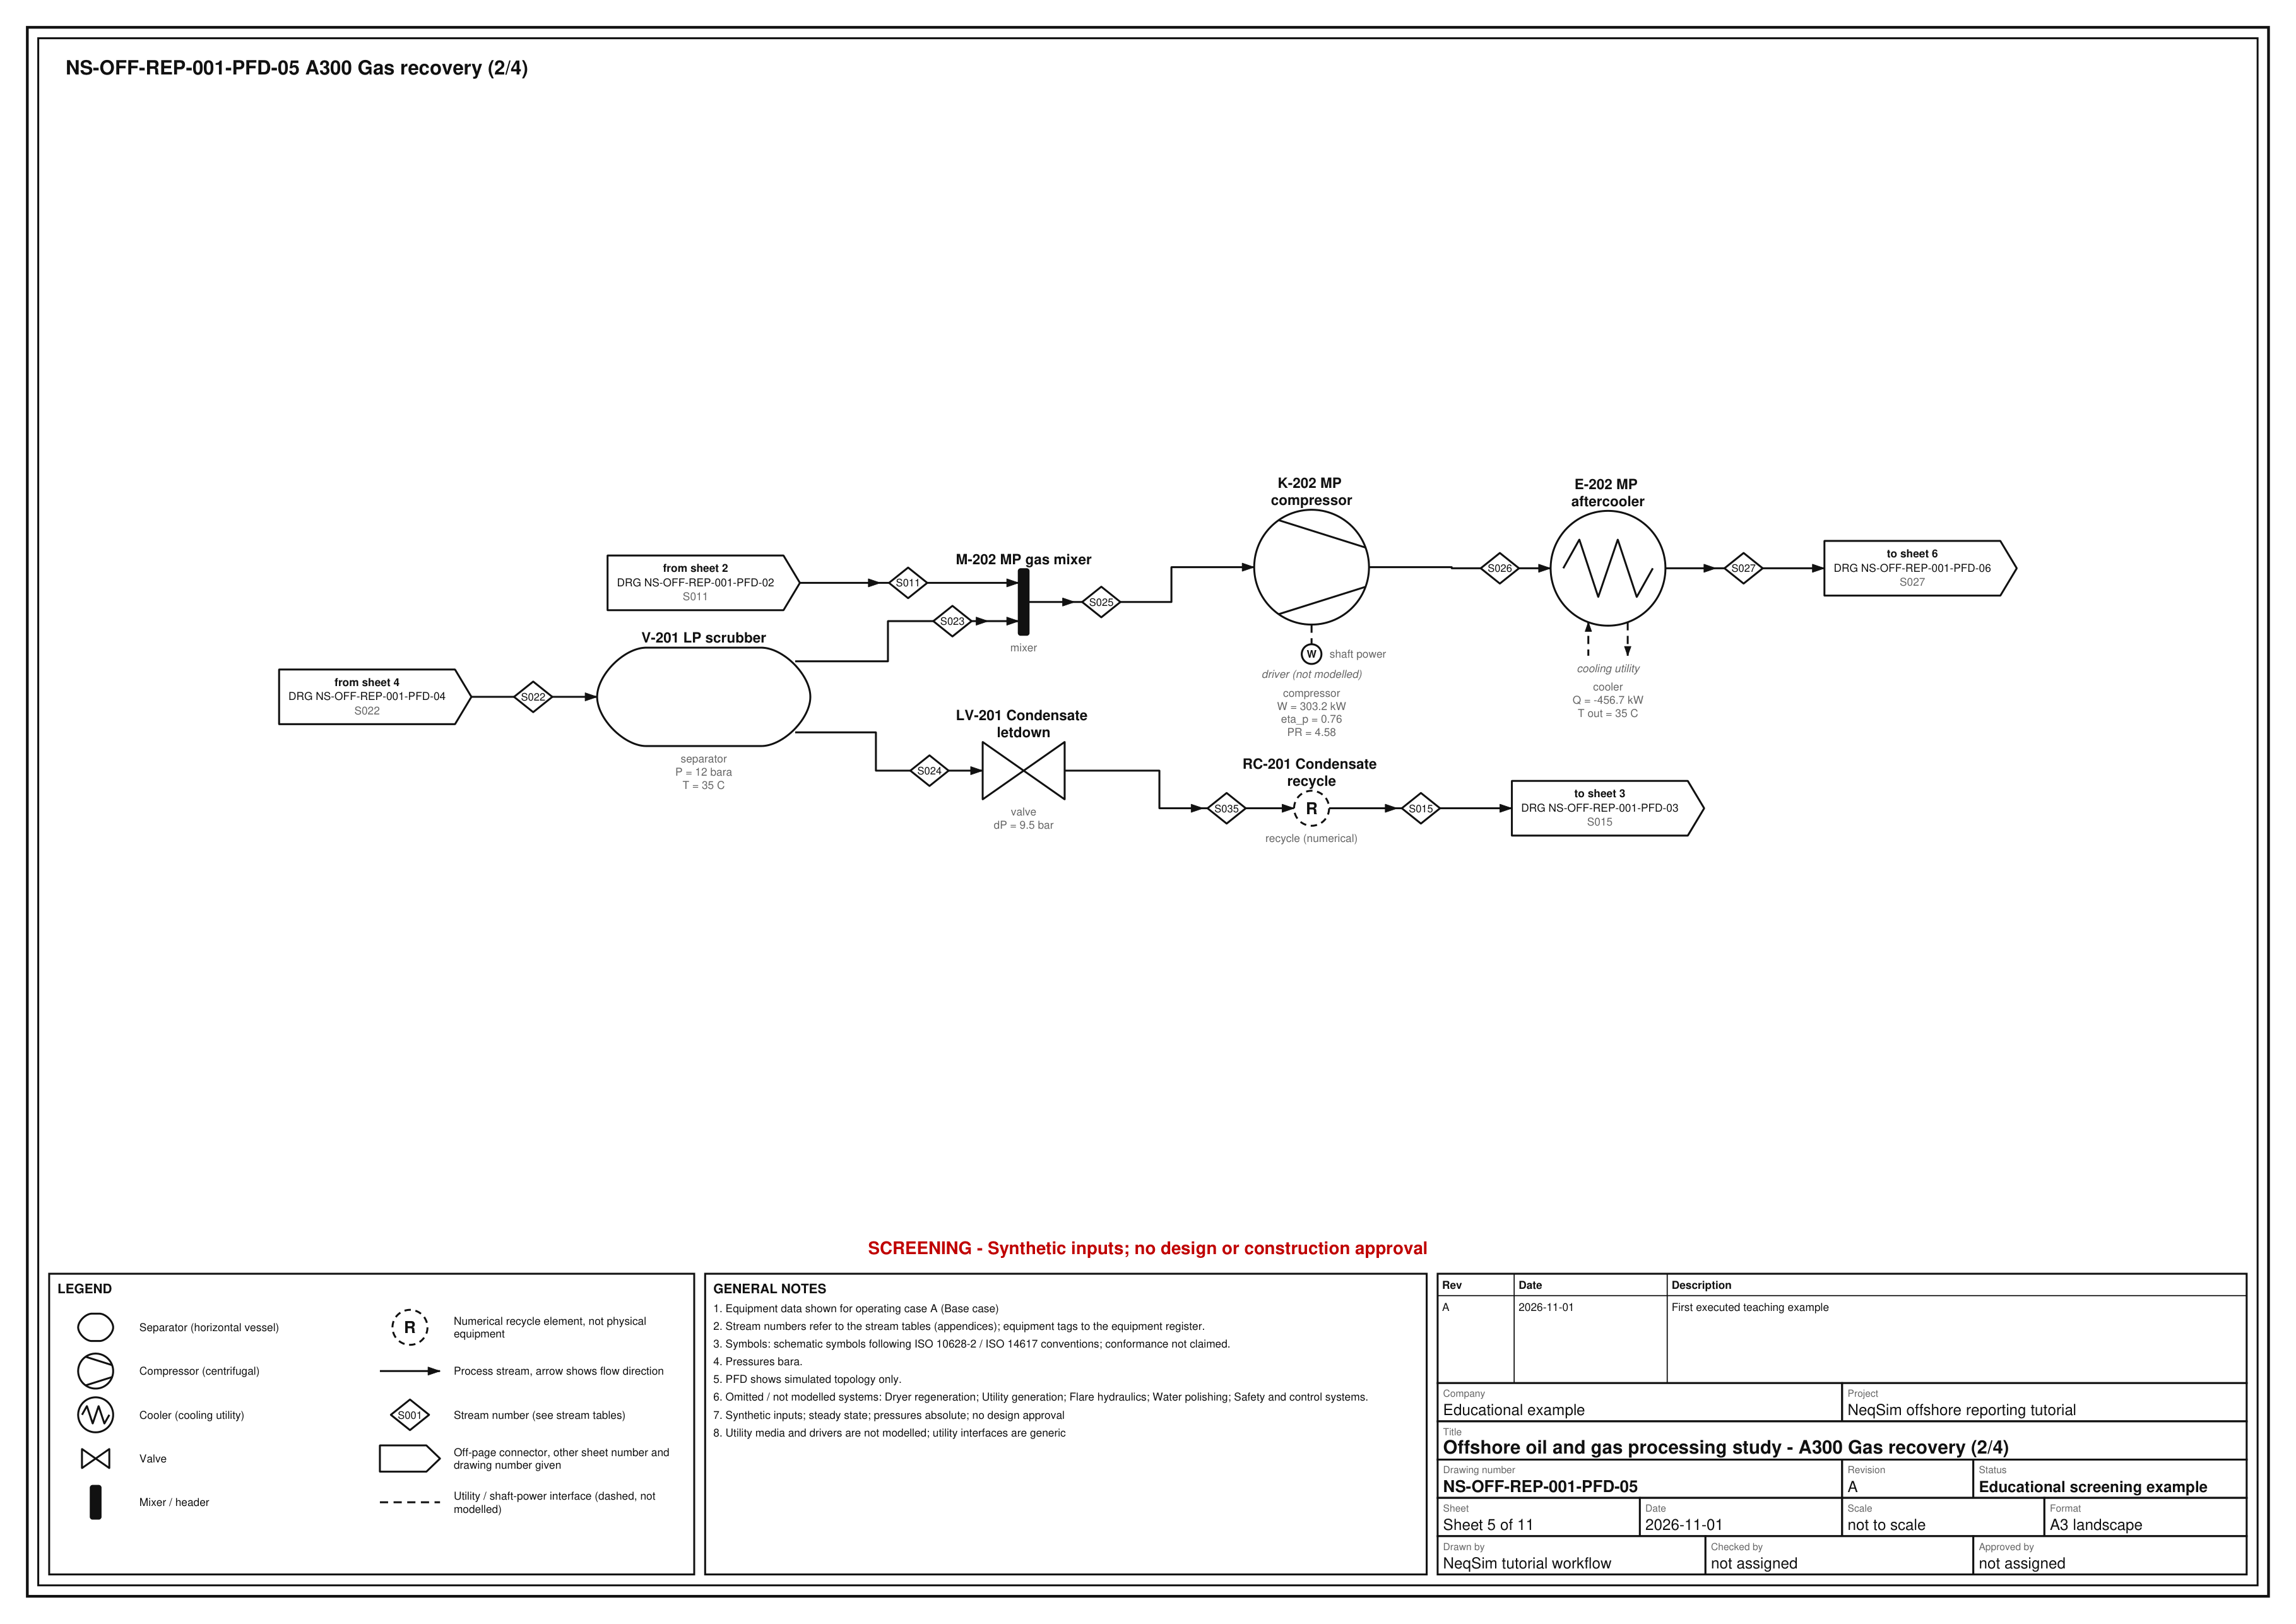

**pfd_006.png**

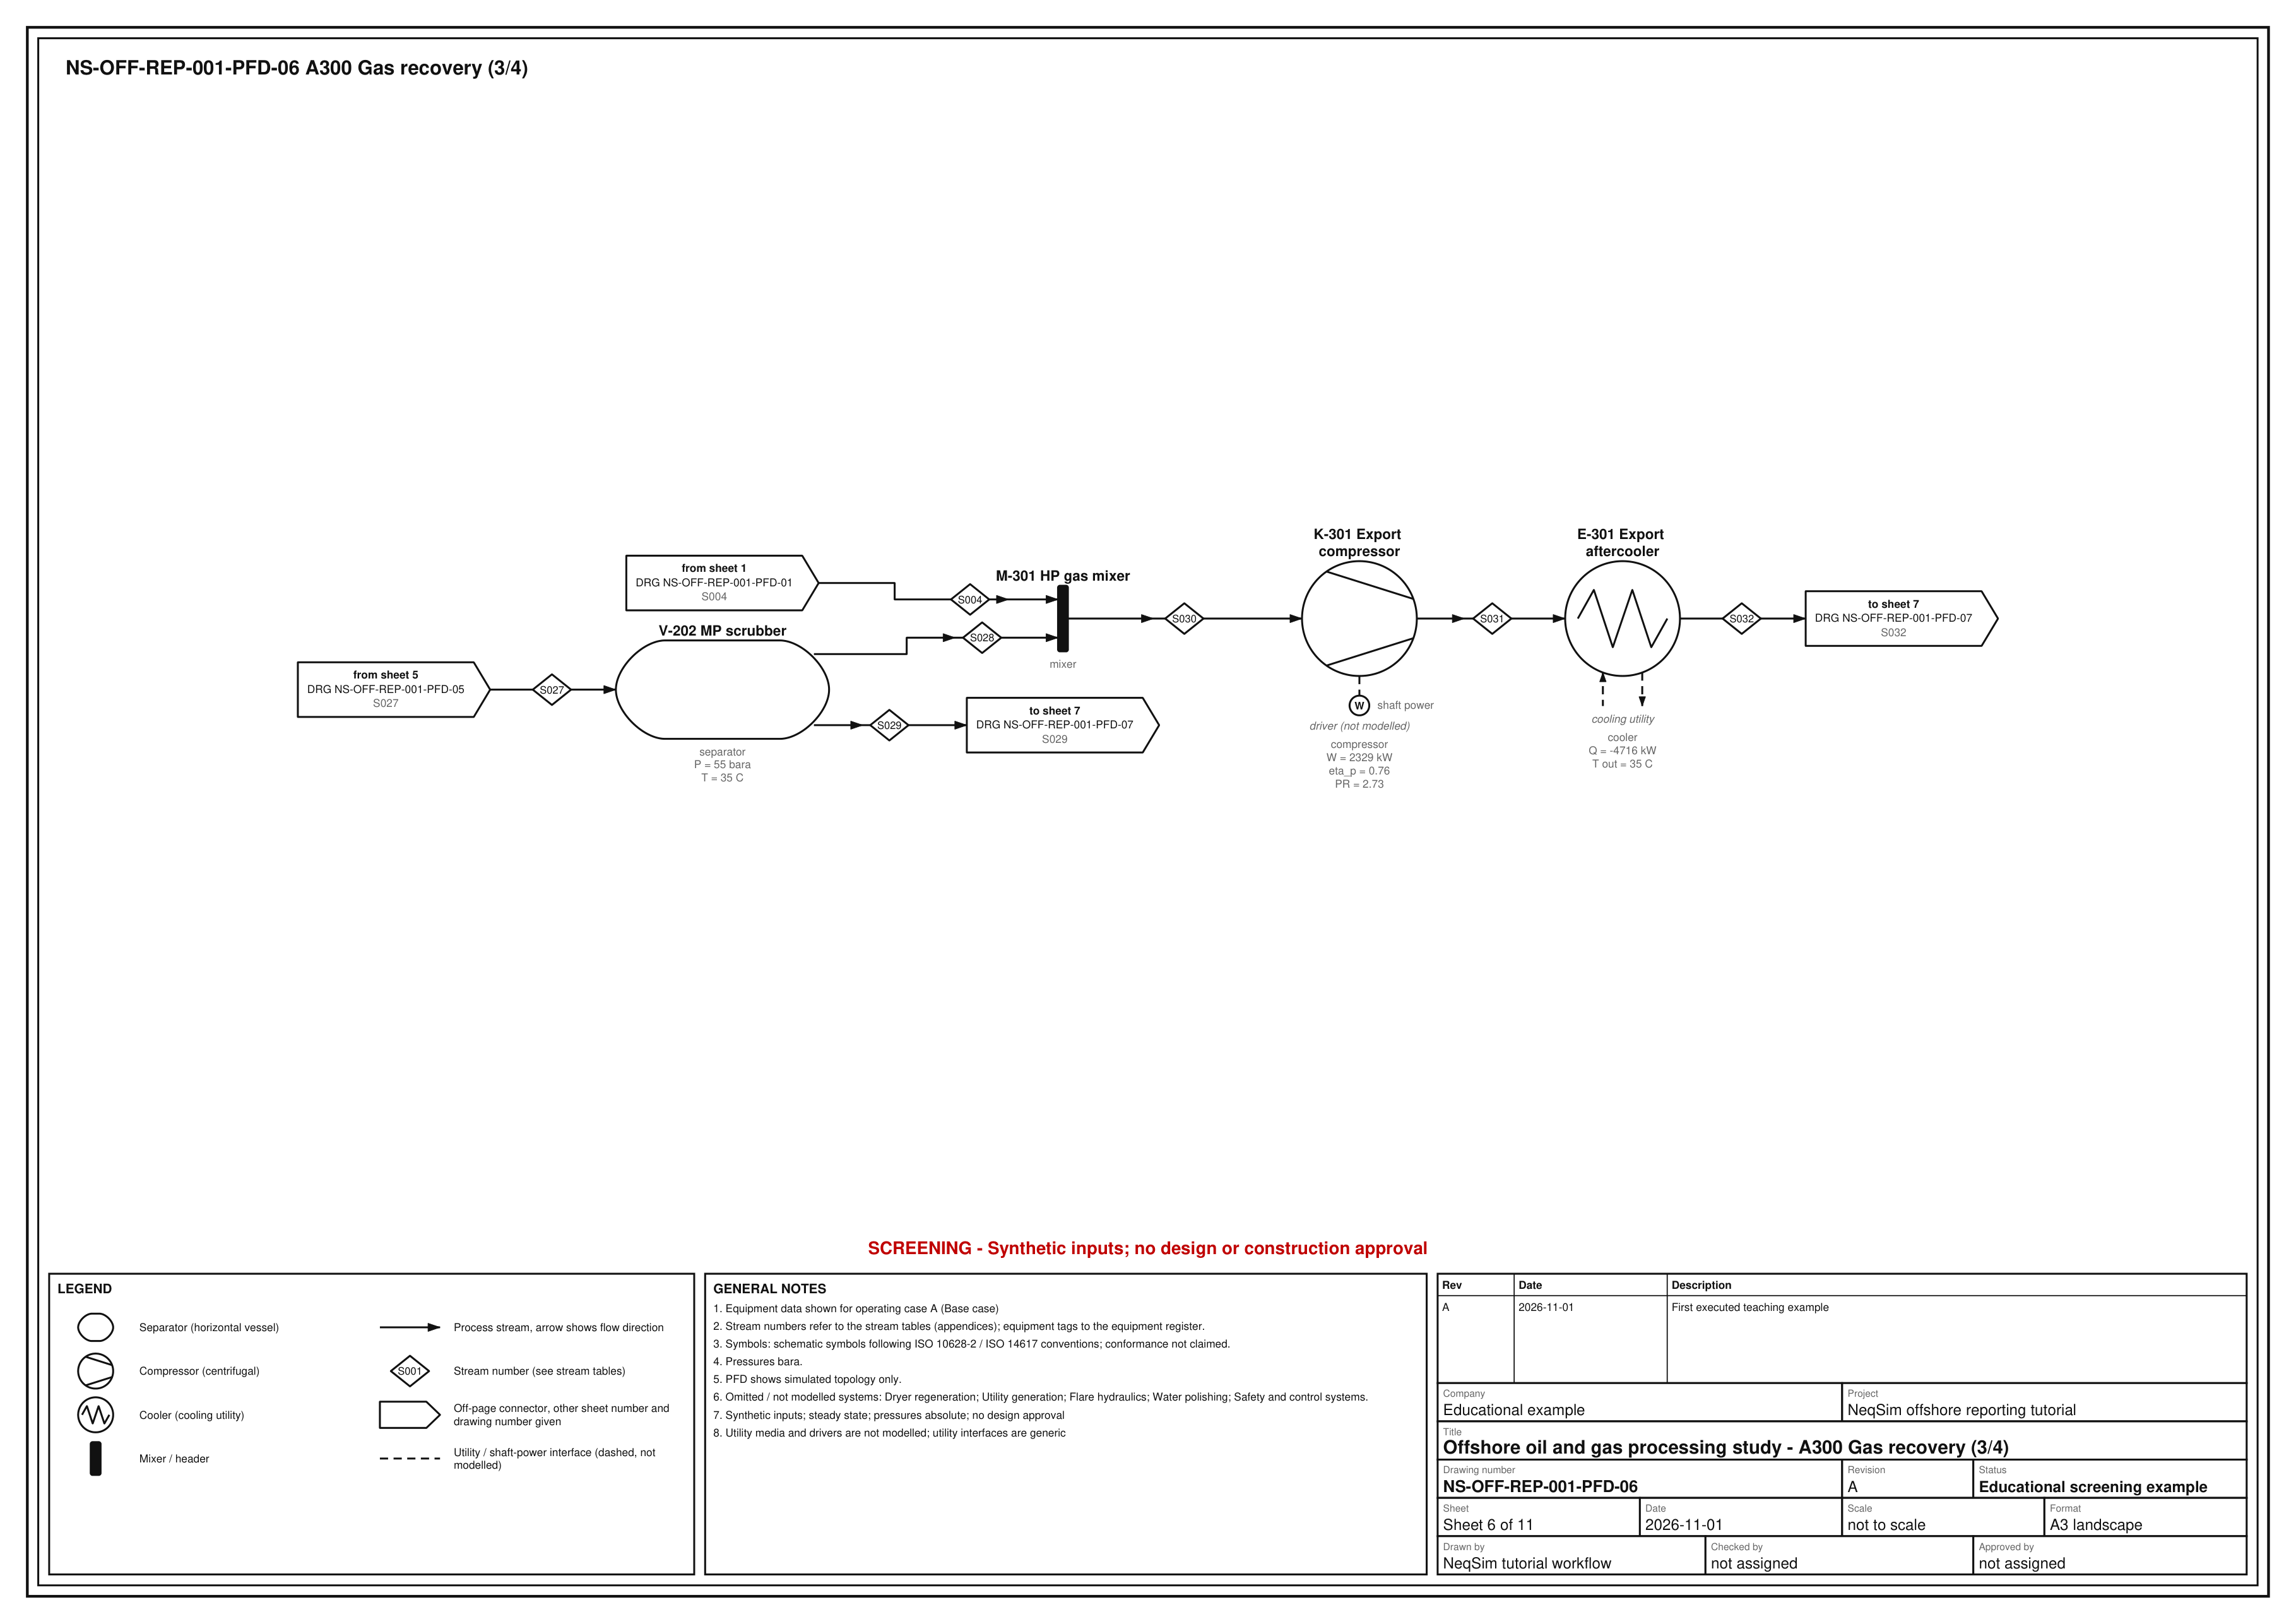

**pfd_007.png**

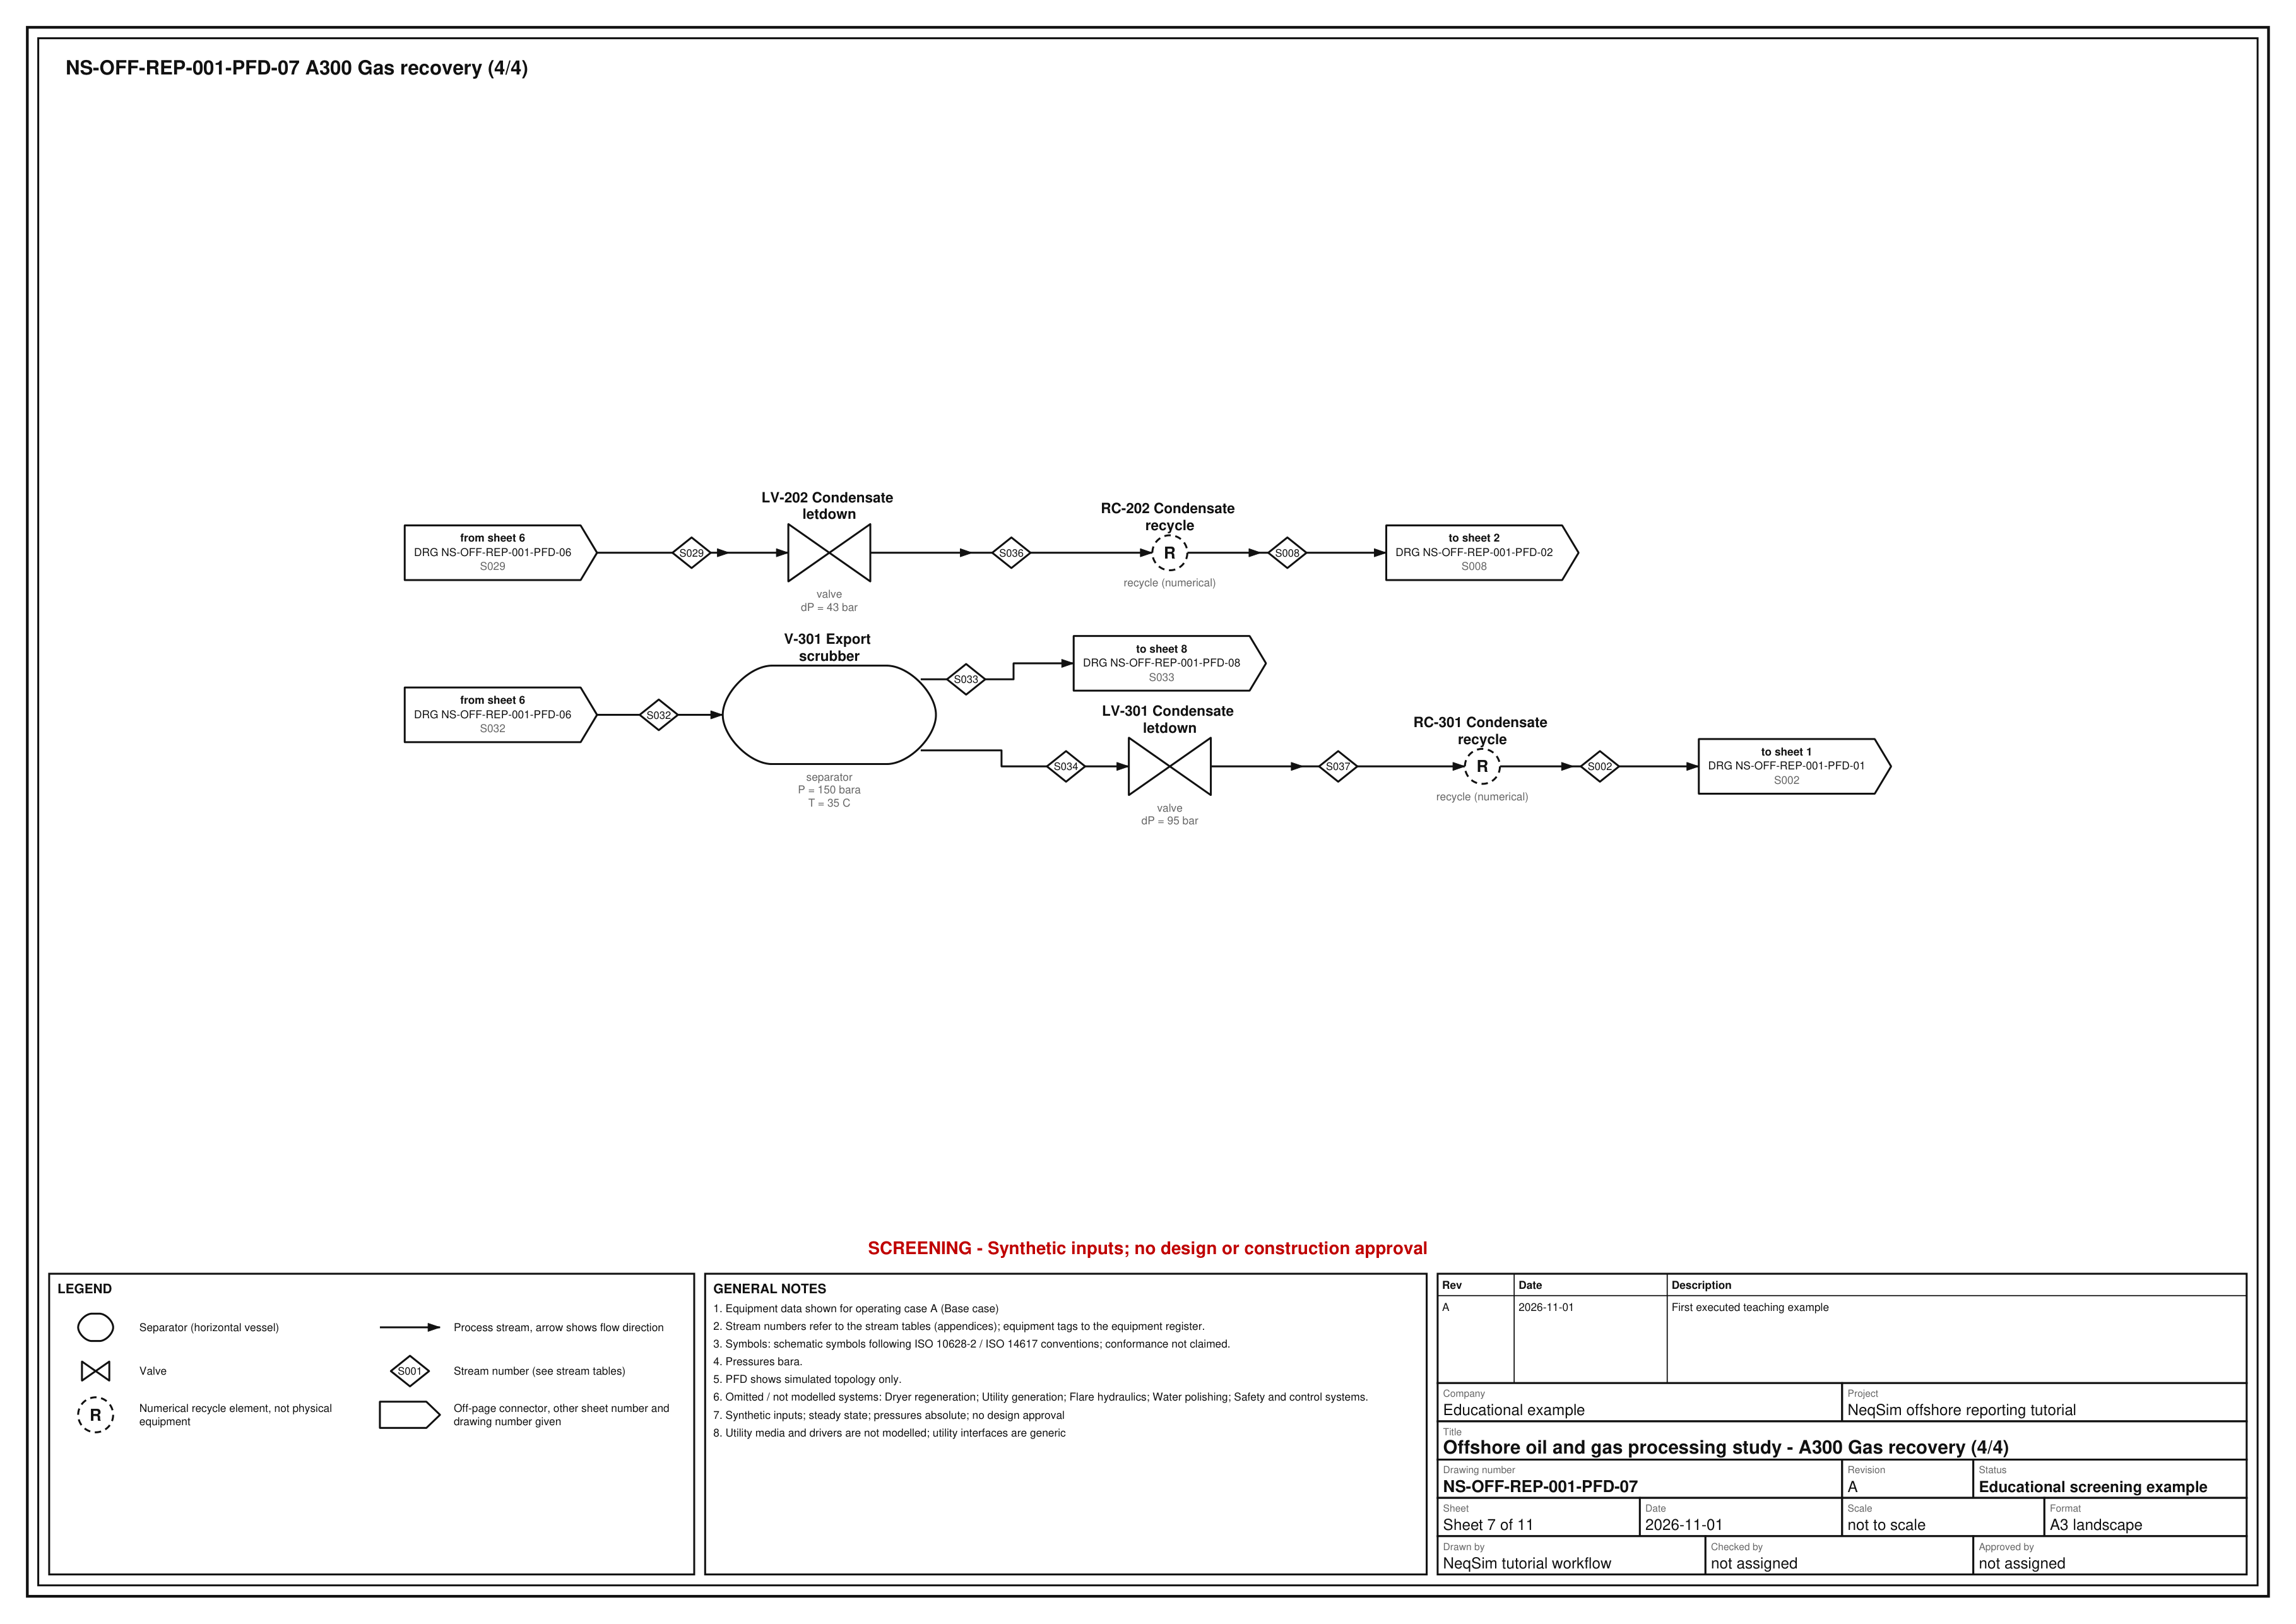

**pfd_008.png**

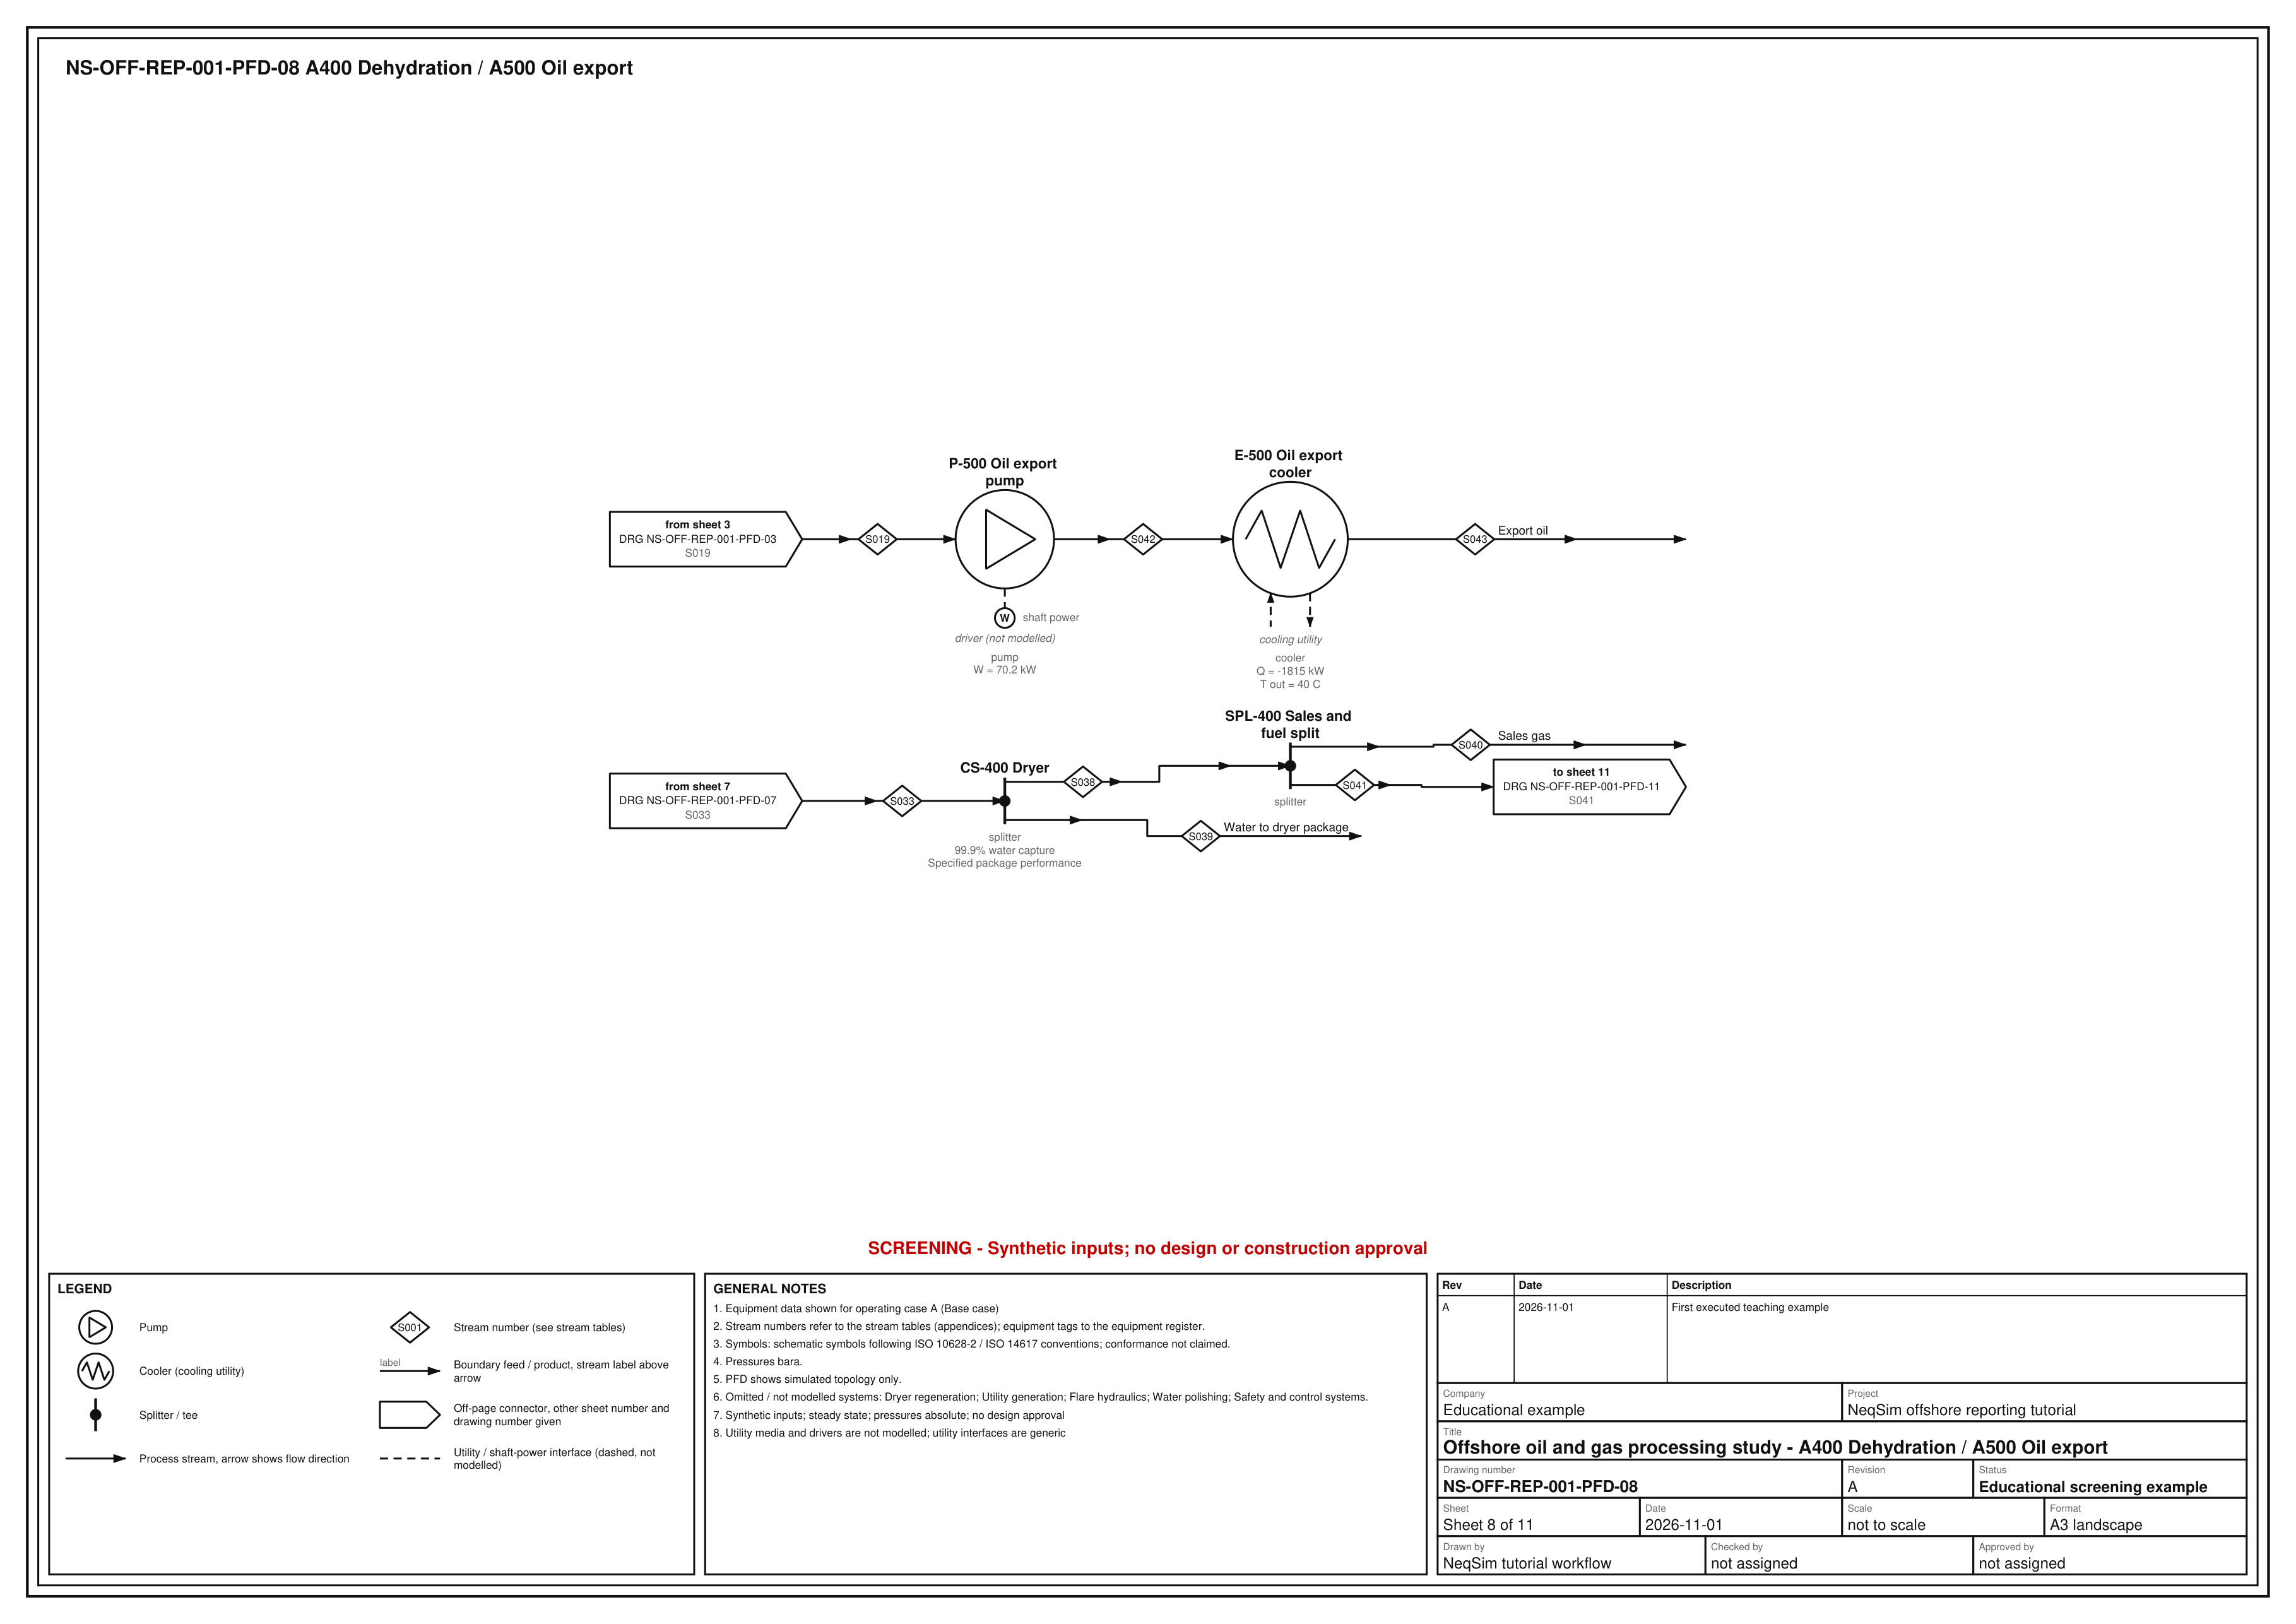

**pfd_009.png**

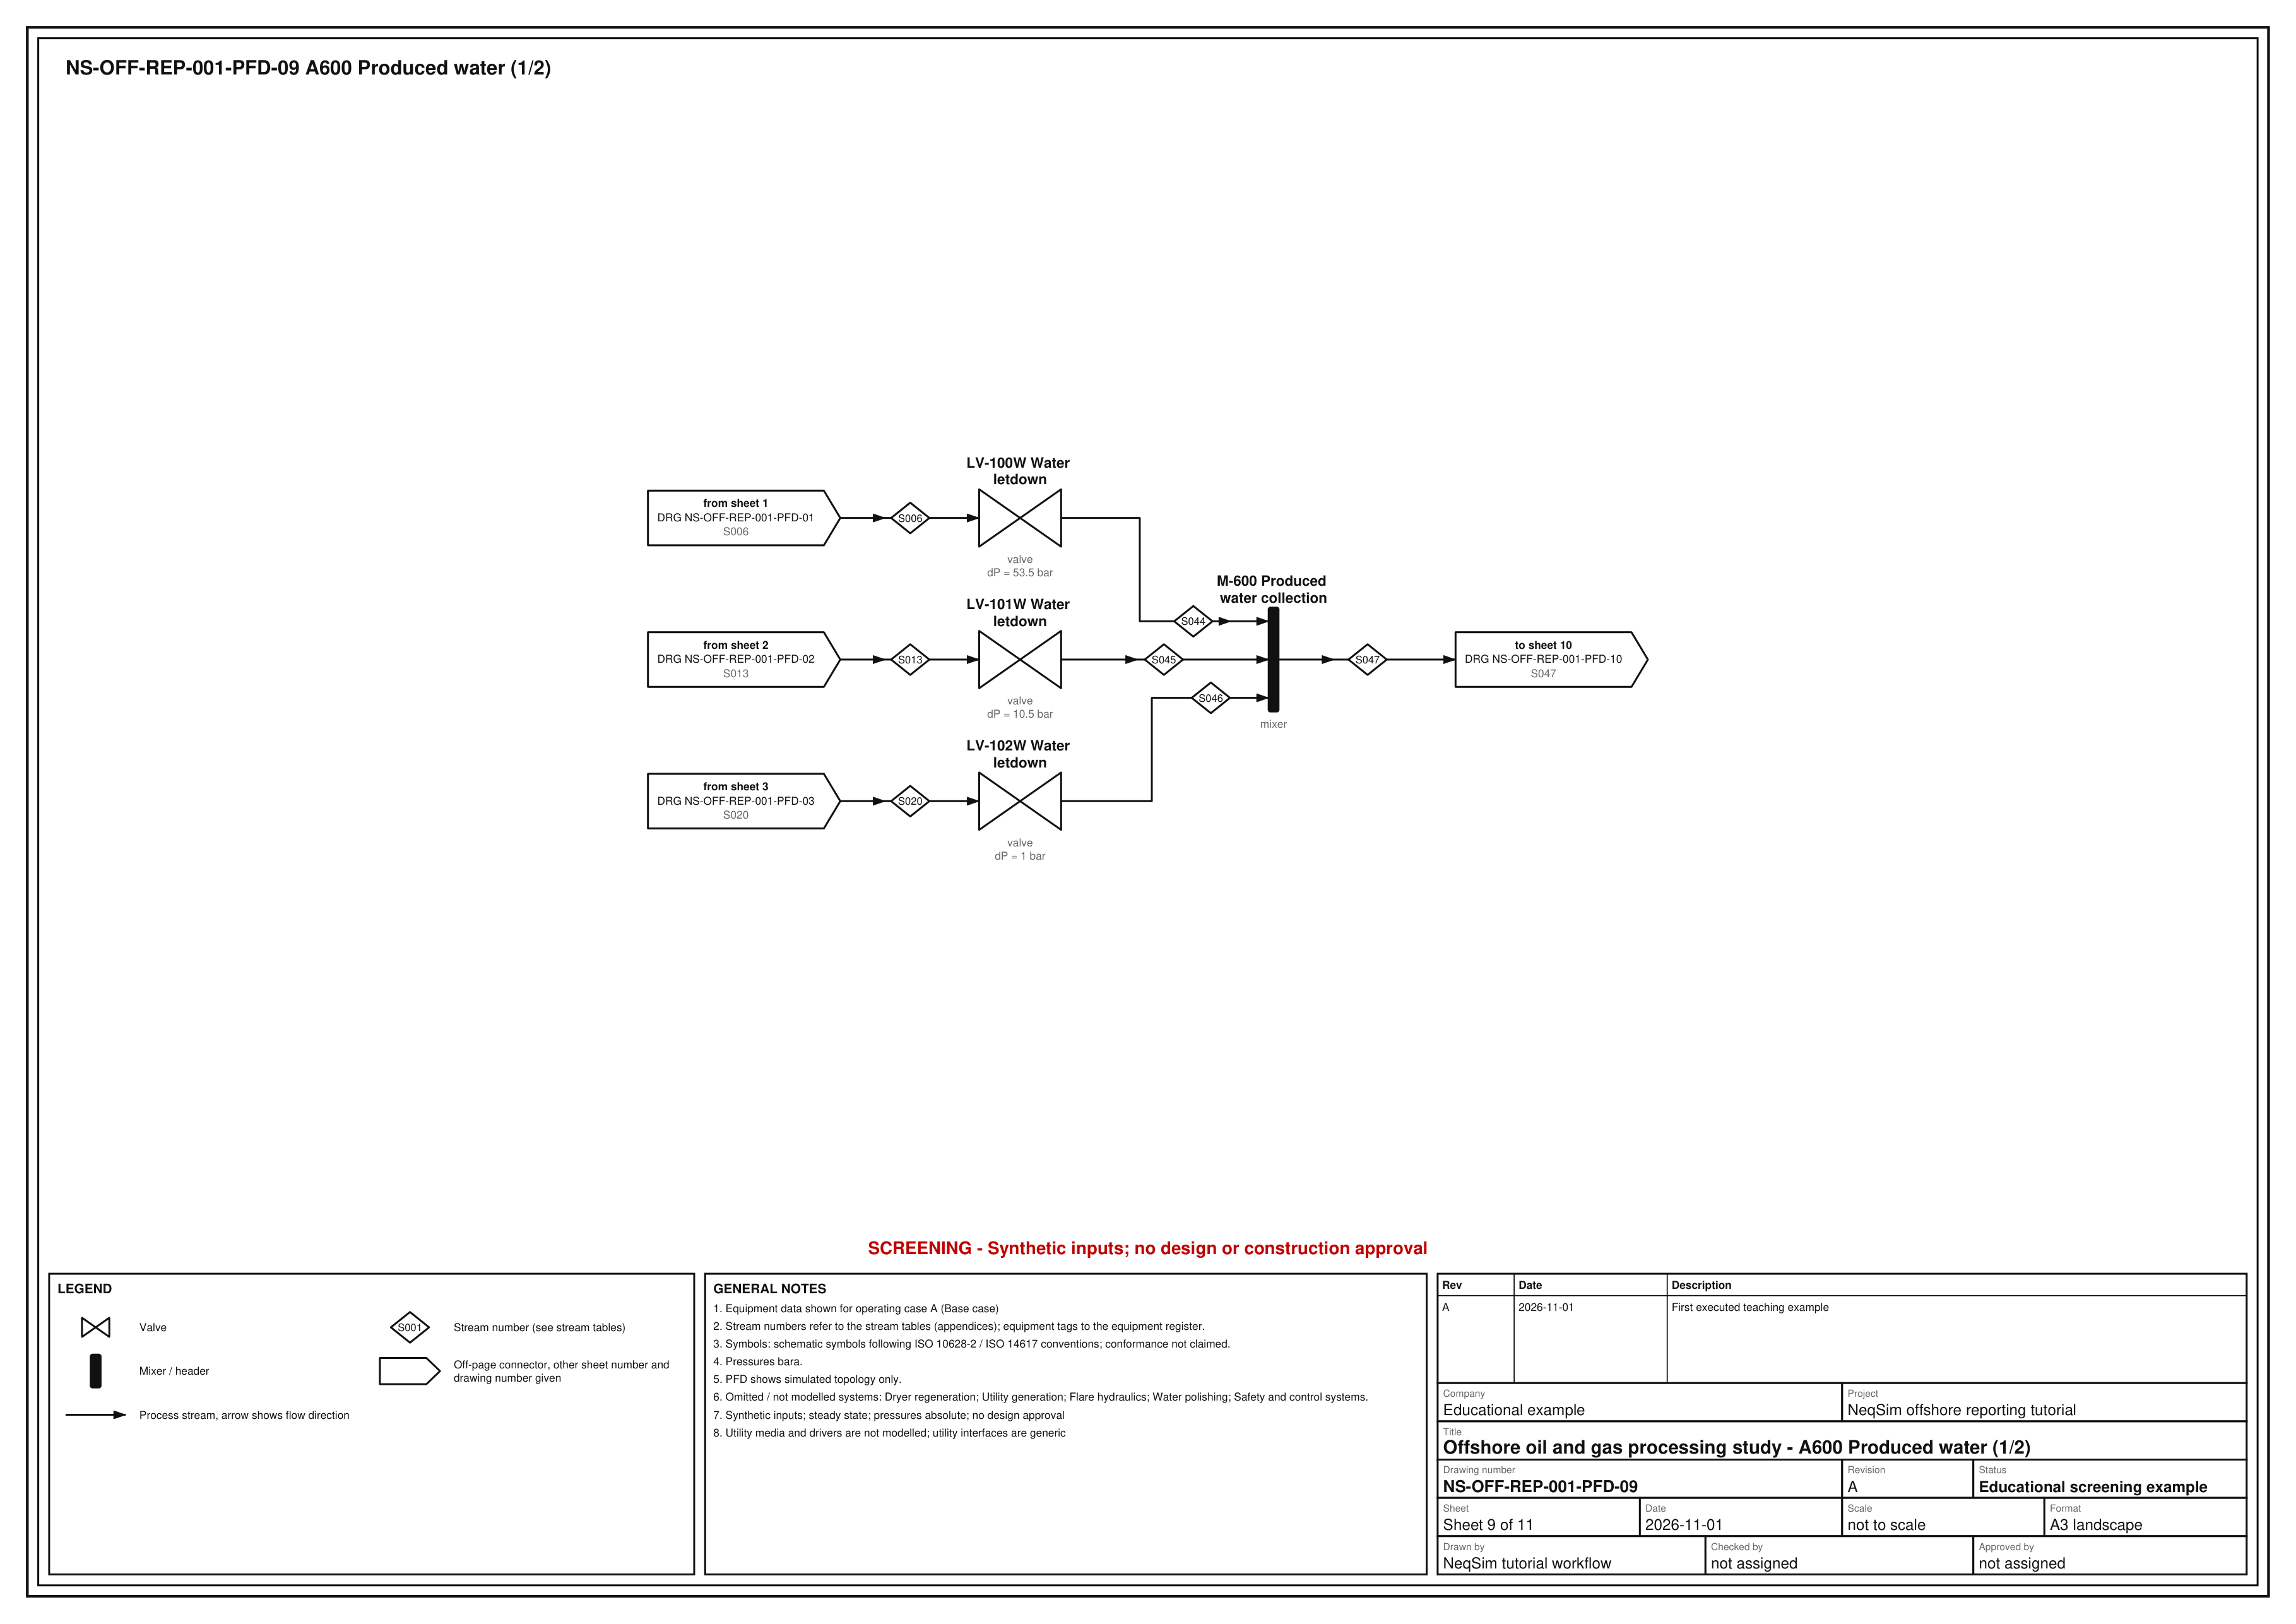

**pfd_010.png**

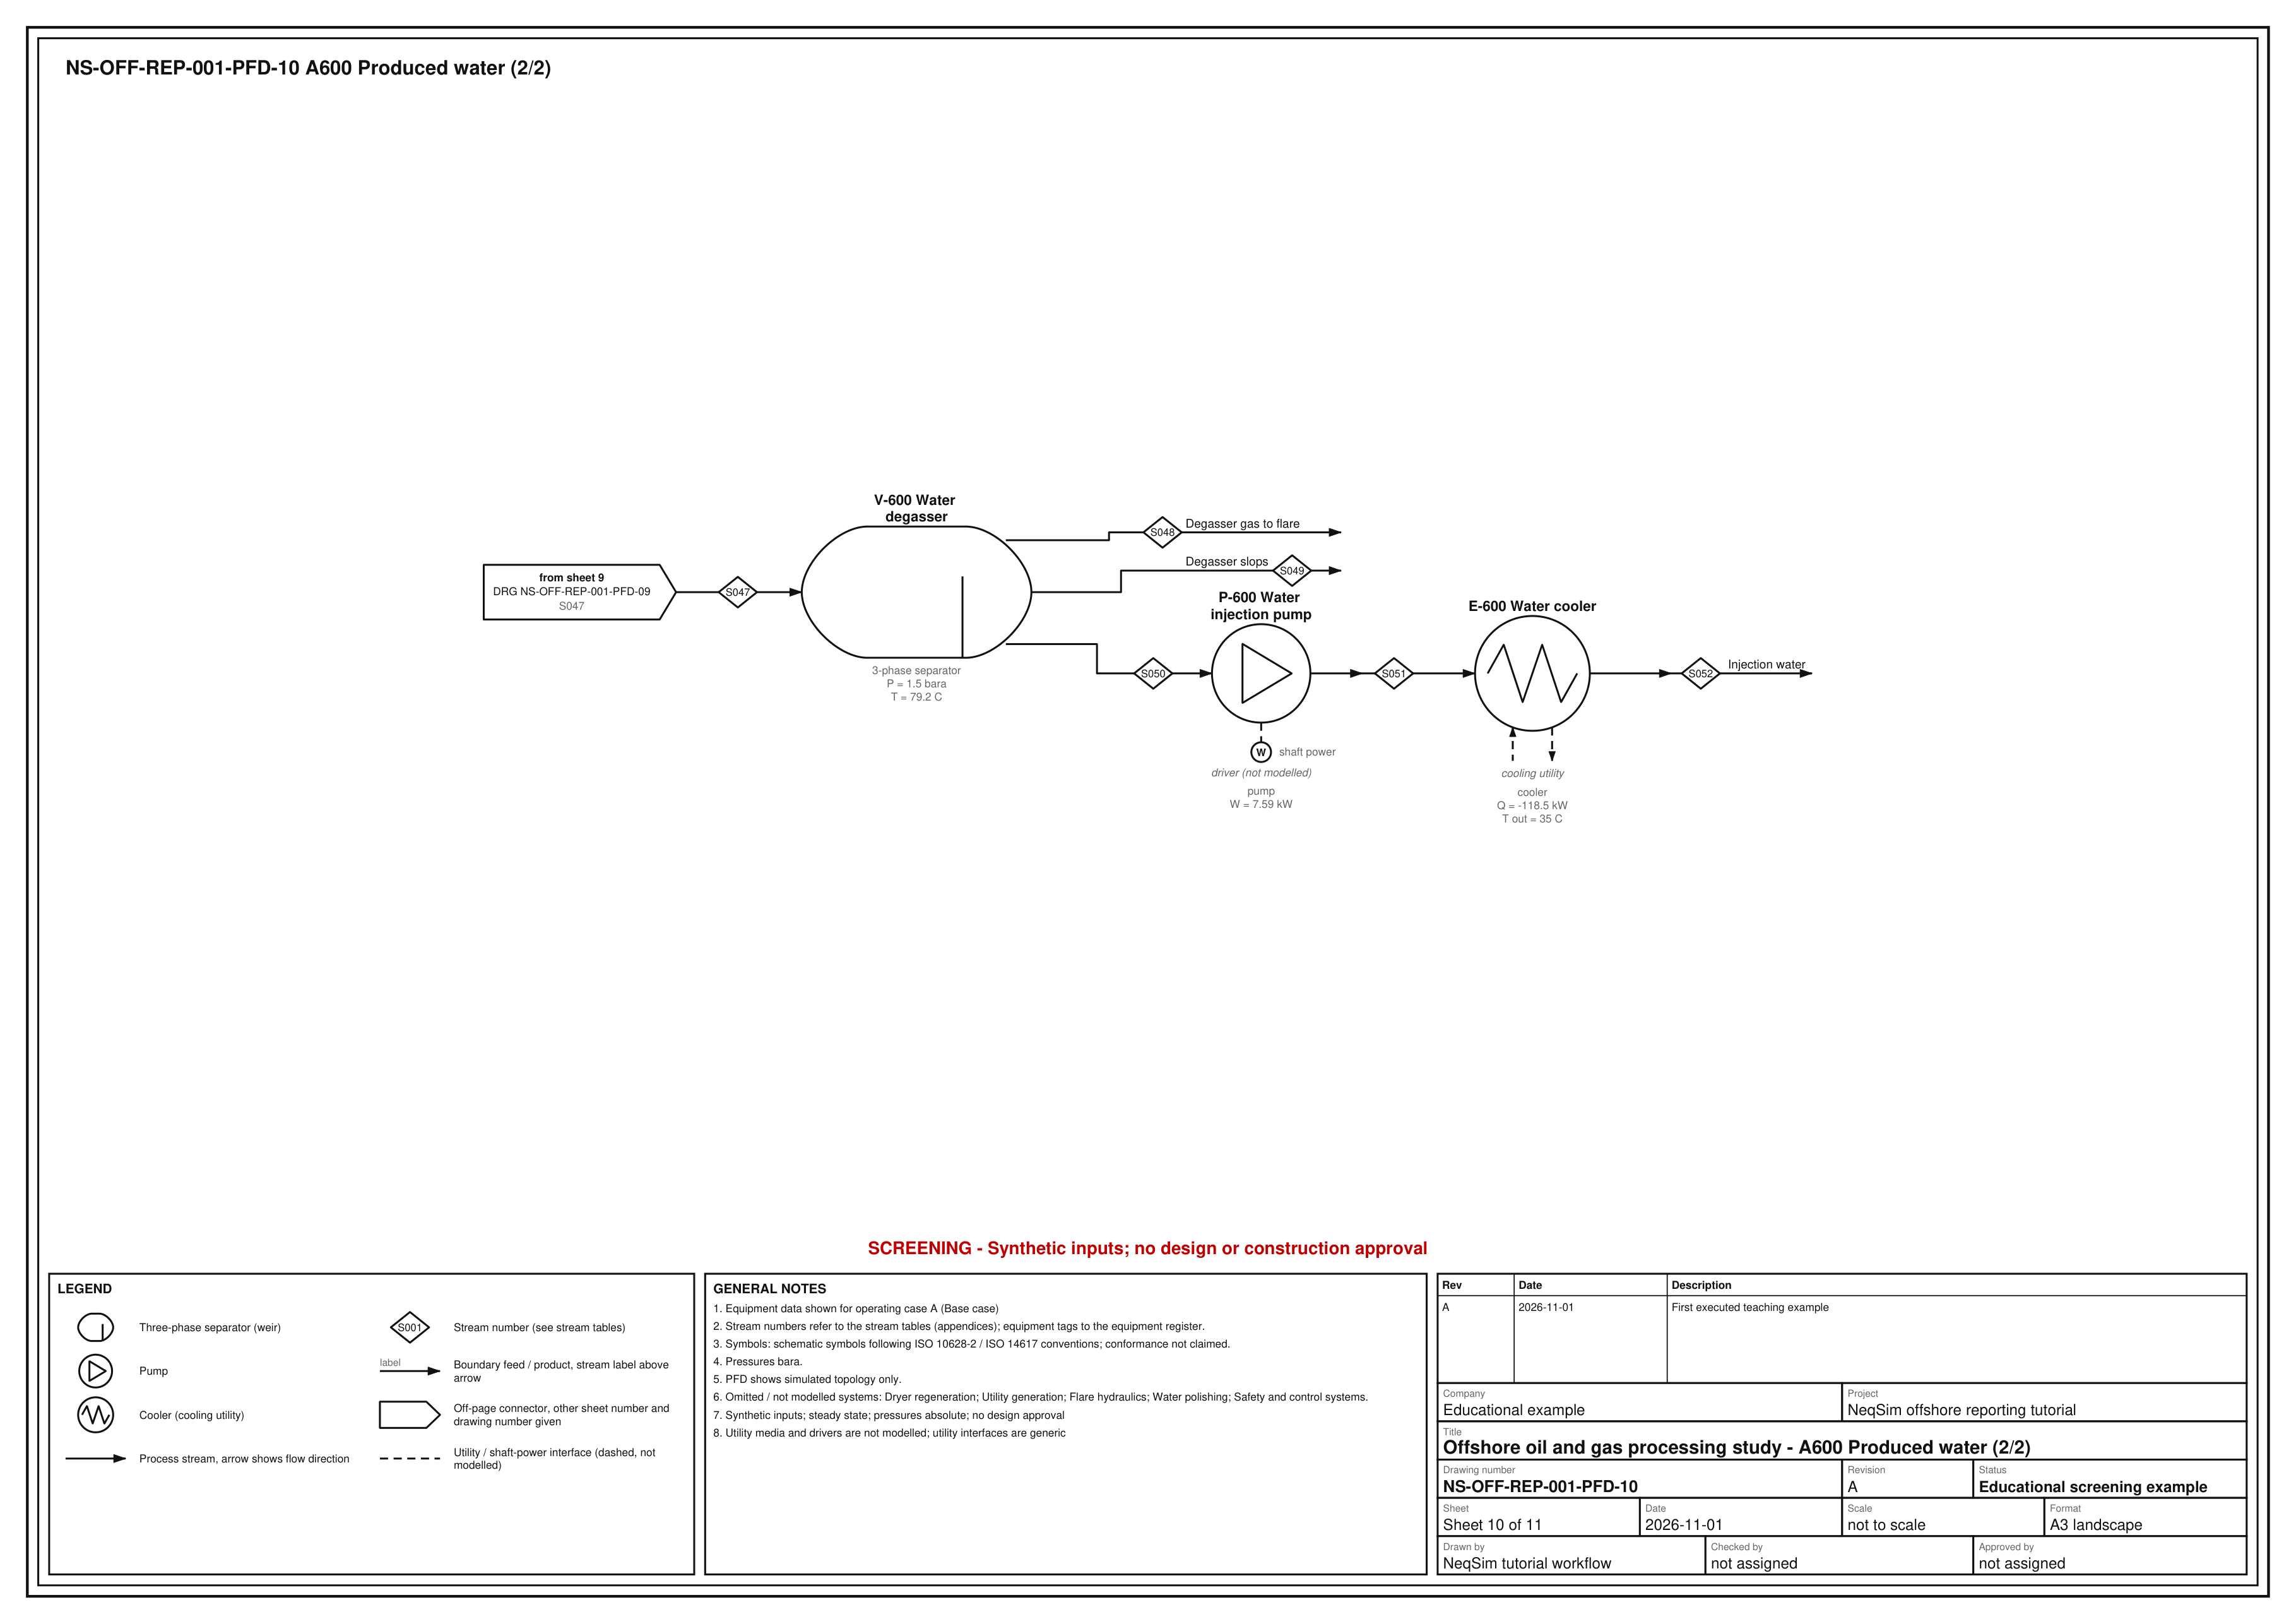

**pfd_011.png**

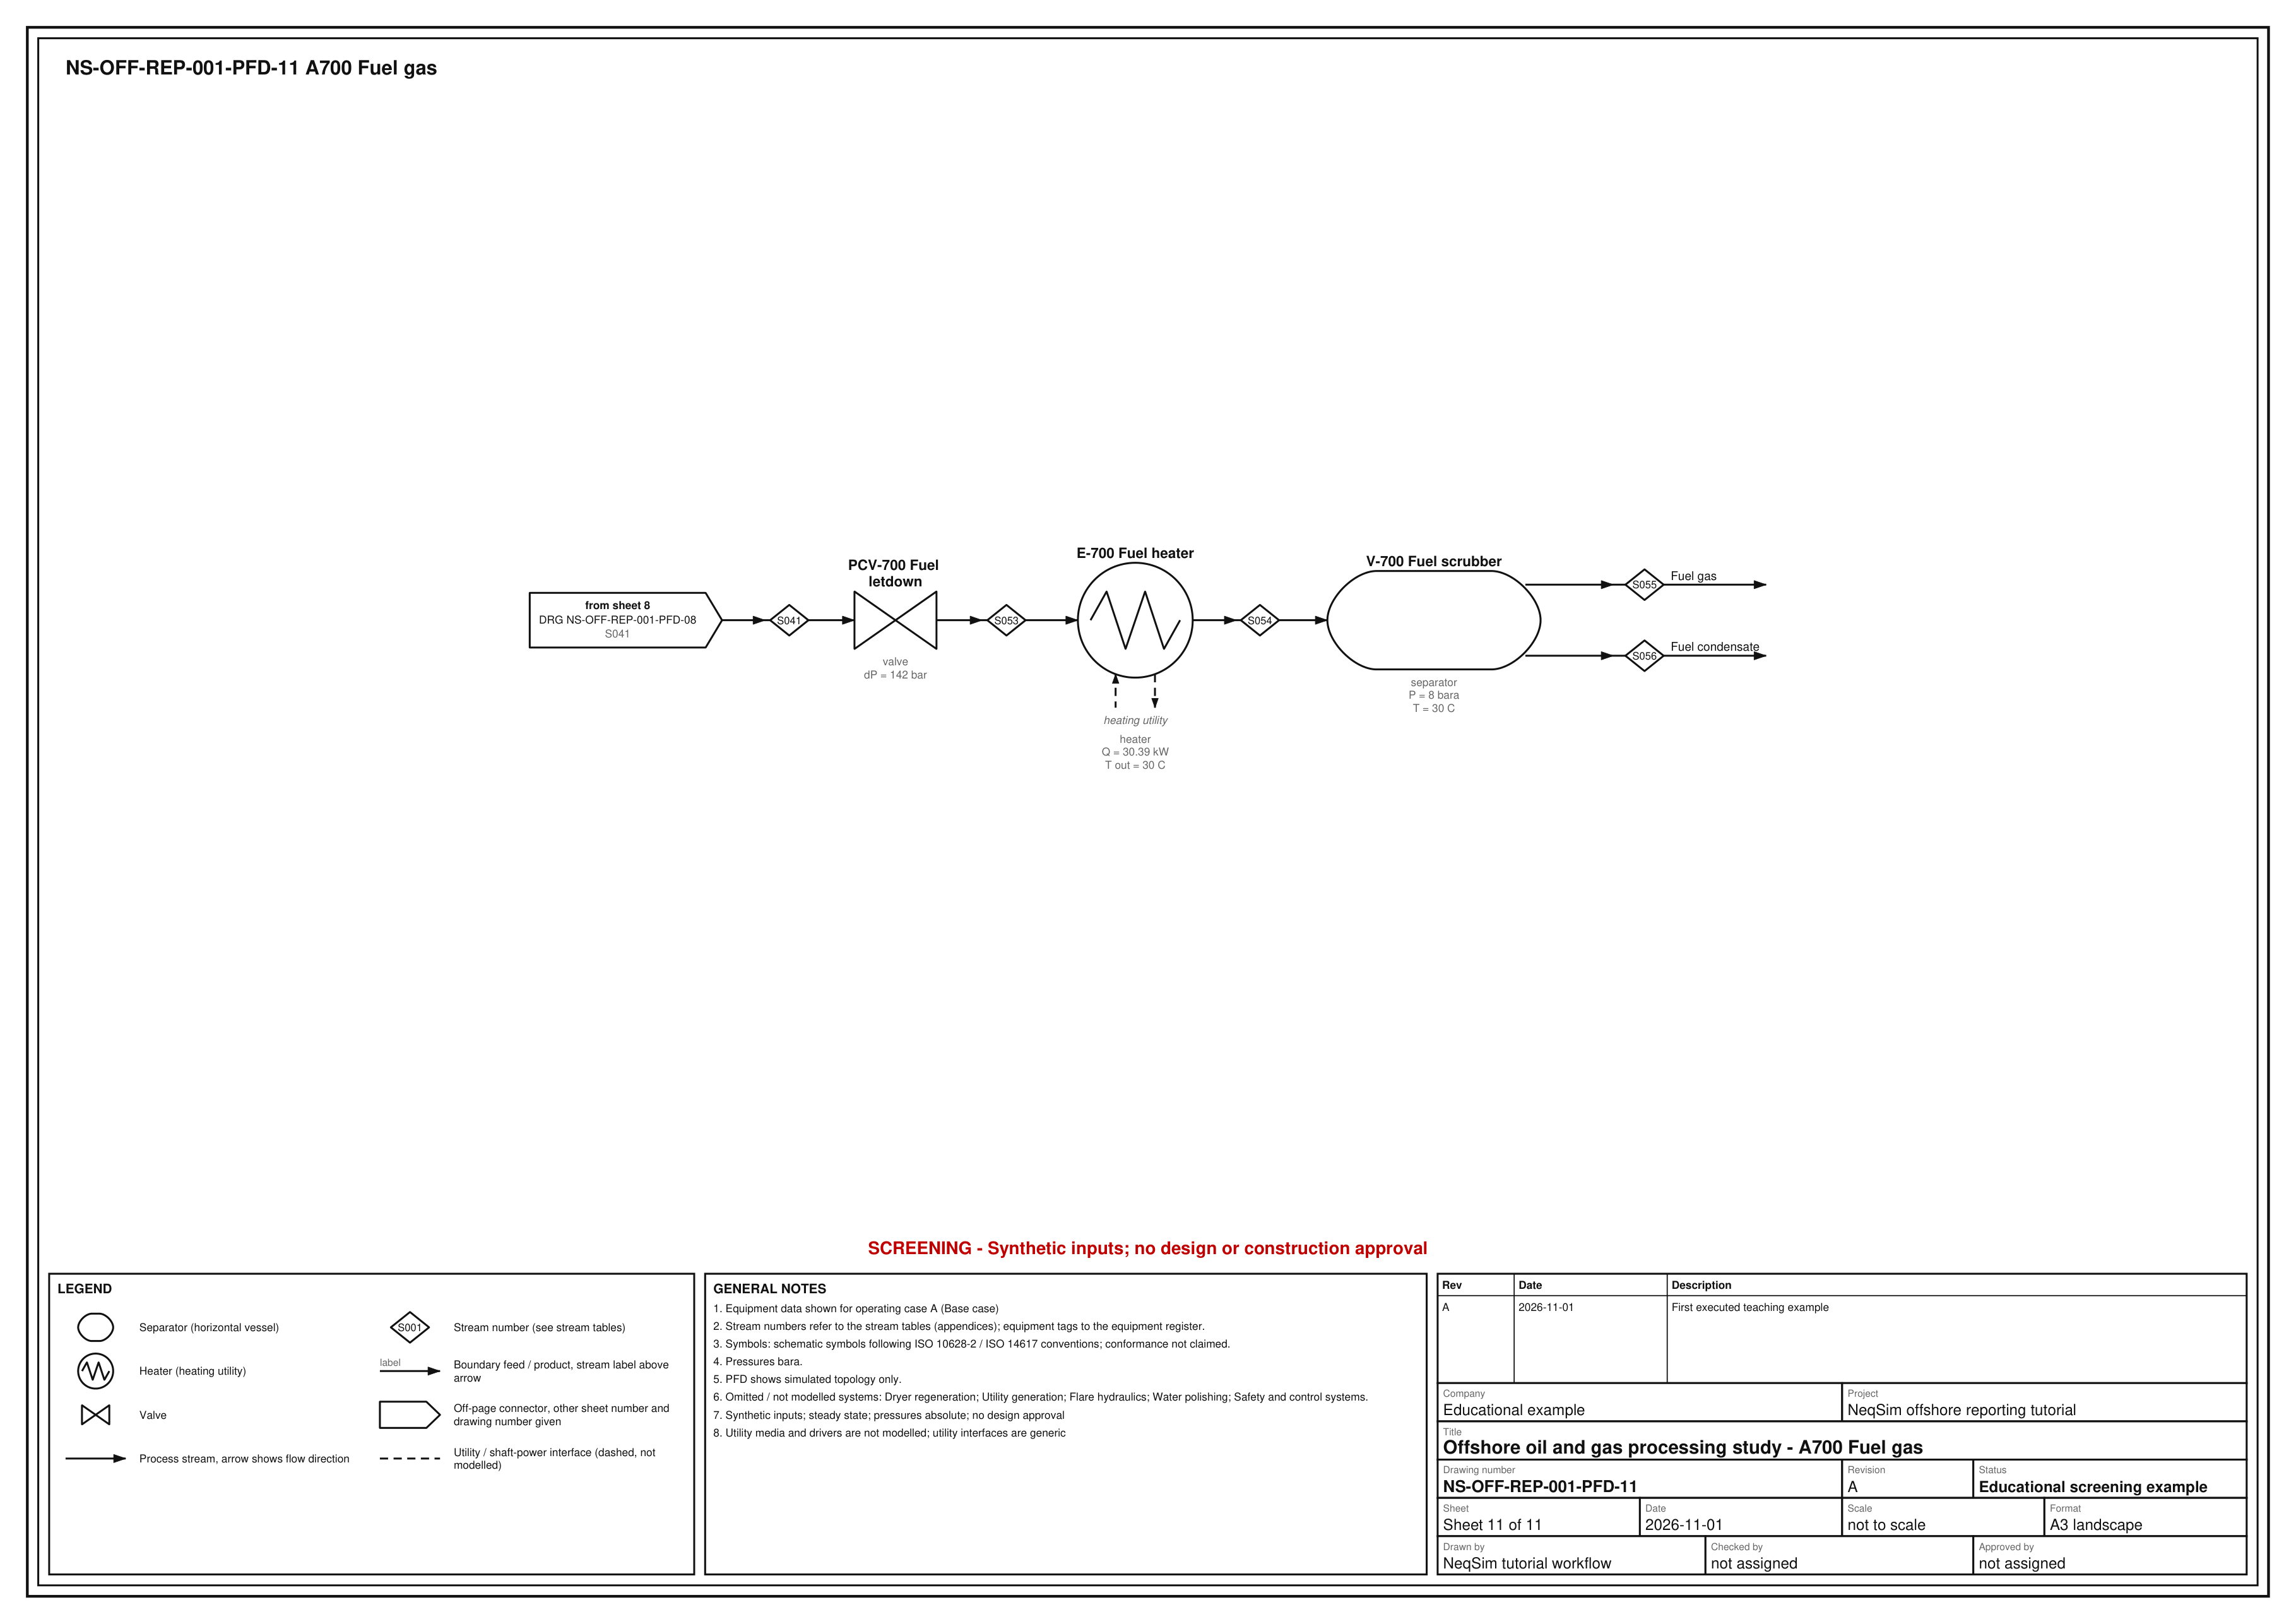

In [24]:
bfd_previews = sorted((OUTPUT / "process_report" / "figures").glob("bfd*.png"))
pfd_previews = sorted((OUTPUT / "process_report" / "figures").glob("pfd*.png"))
for image_path in bfd_previews + pfd_previews:
    display(Markdown("**" + image_path.name + "**"))
    display(Image(filename=str(image_path), width=1400))


## 11. Create an A3 overview and a 16:9 presentation diagram

The `professional-process-overview` skill consumes the **same extracted data**. Dense sections
may appear as traceable area blocks on the one-sheet overview; the detailed PFDs preserve the
individual equipment and all streams. The monochrome variant preserves service distinctions
using line patterns.
Only the main colour/monochrome presentation overviews are issued. Equipment details are
provided as A3 PFD sheets; optional supporting presentation slides are excluded from this package.

The CLI equivalent is:

```text
neqsim process-overview process_report/data/process_data.json --case A --out process_overview
```

Overview validation: PASS
Overview detail-sheet layout: {'status': 'PASS', 'sheets': 7, 'counts': {'PASS': 7, 'WARN': 0, 'FAIL': 0}, 'dir': '/workspace/scratch/173328b47b0e/offshore_study_deliverables/process_overview/detail_layout_review'}


,id,title,status,detail,items
0,V01,Equipment and stream identifiers unique and traceable,PASS,"29 equipment ids, 44 stream ids; every node maps to source tags through members/mapping",[]
1,V02,Every connection has valid endpoints; no unexplained dangling connections,PASS,"42 drawn edges, 22 complete unit-to-unit connections, 0 dangling legs",[]
2,V03,Every major source section and boundary interface is represented,PASS,"7/7 model areas drawn (detail or block), 9/9 boundary streams drawn",[]
3,V04,"Grouped, bundled and collapsed elements have an explicit underlying mapping",PASS,"0 grouped equipment nodes, 0 grouped streams, 12 collapsed elements, 12 merged streams, 3 block-to-block bundles",[]
4,V05,Displayed values match the selected source case (A),PASS,5 annotations re-derived from results['A'],[]
5,V06,"Labels, symbols and lines stay inside the drawing frame",PASS,"frame (20, 10)-(410, 287) mm",[]
6,V07,Label text at or above the readability target (7.0 pt),PASS,smallest process label 7.5 pt,[]
7,V08,No label overlaps or line-through-equipment conflicts (pfd_layout_check PASS),PASS,"CROSSING x1, PRODUCT_POSITION x1",[]
8,V09,"PDF page dimensions, embedded fonts and expected exports",PASS,"4 variants, each SVG + PDF + PNG","[overview_A3_colour: 420.0 x 297.0 mm, fonts DejaVu Sans Book(embedded), DejaVu Sans Bold(embedded), overview_A3_mono: 420.0 x 297.0 mm, fonts DejaVu Sans Book(embedded), DejaVu Sans Bold(embedded), overview_16x9: 338.7 x 190.5 mm, fonts DejaVu Sans Book(embedded), DejaVu Sans Bold(embedded), overview_16x9_mono: 338.7 x 190.5 mm, fonts DejaVu Sans Book(embedded), DejaVu Sans Bold(embedded)]"
9,V10,Overview fits the drawing area without reducing text below the readability target,PASS,"symbol scale 1.00, content 366 x 167 mm, 2 row(s), 4 sections collapsed to blocks","[SEC-03, SEC-06, SEC-02, SEC-01]"


**overview_A3_colour.png**

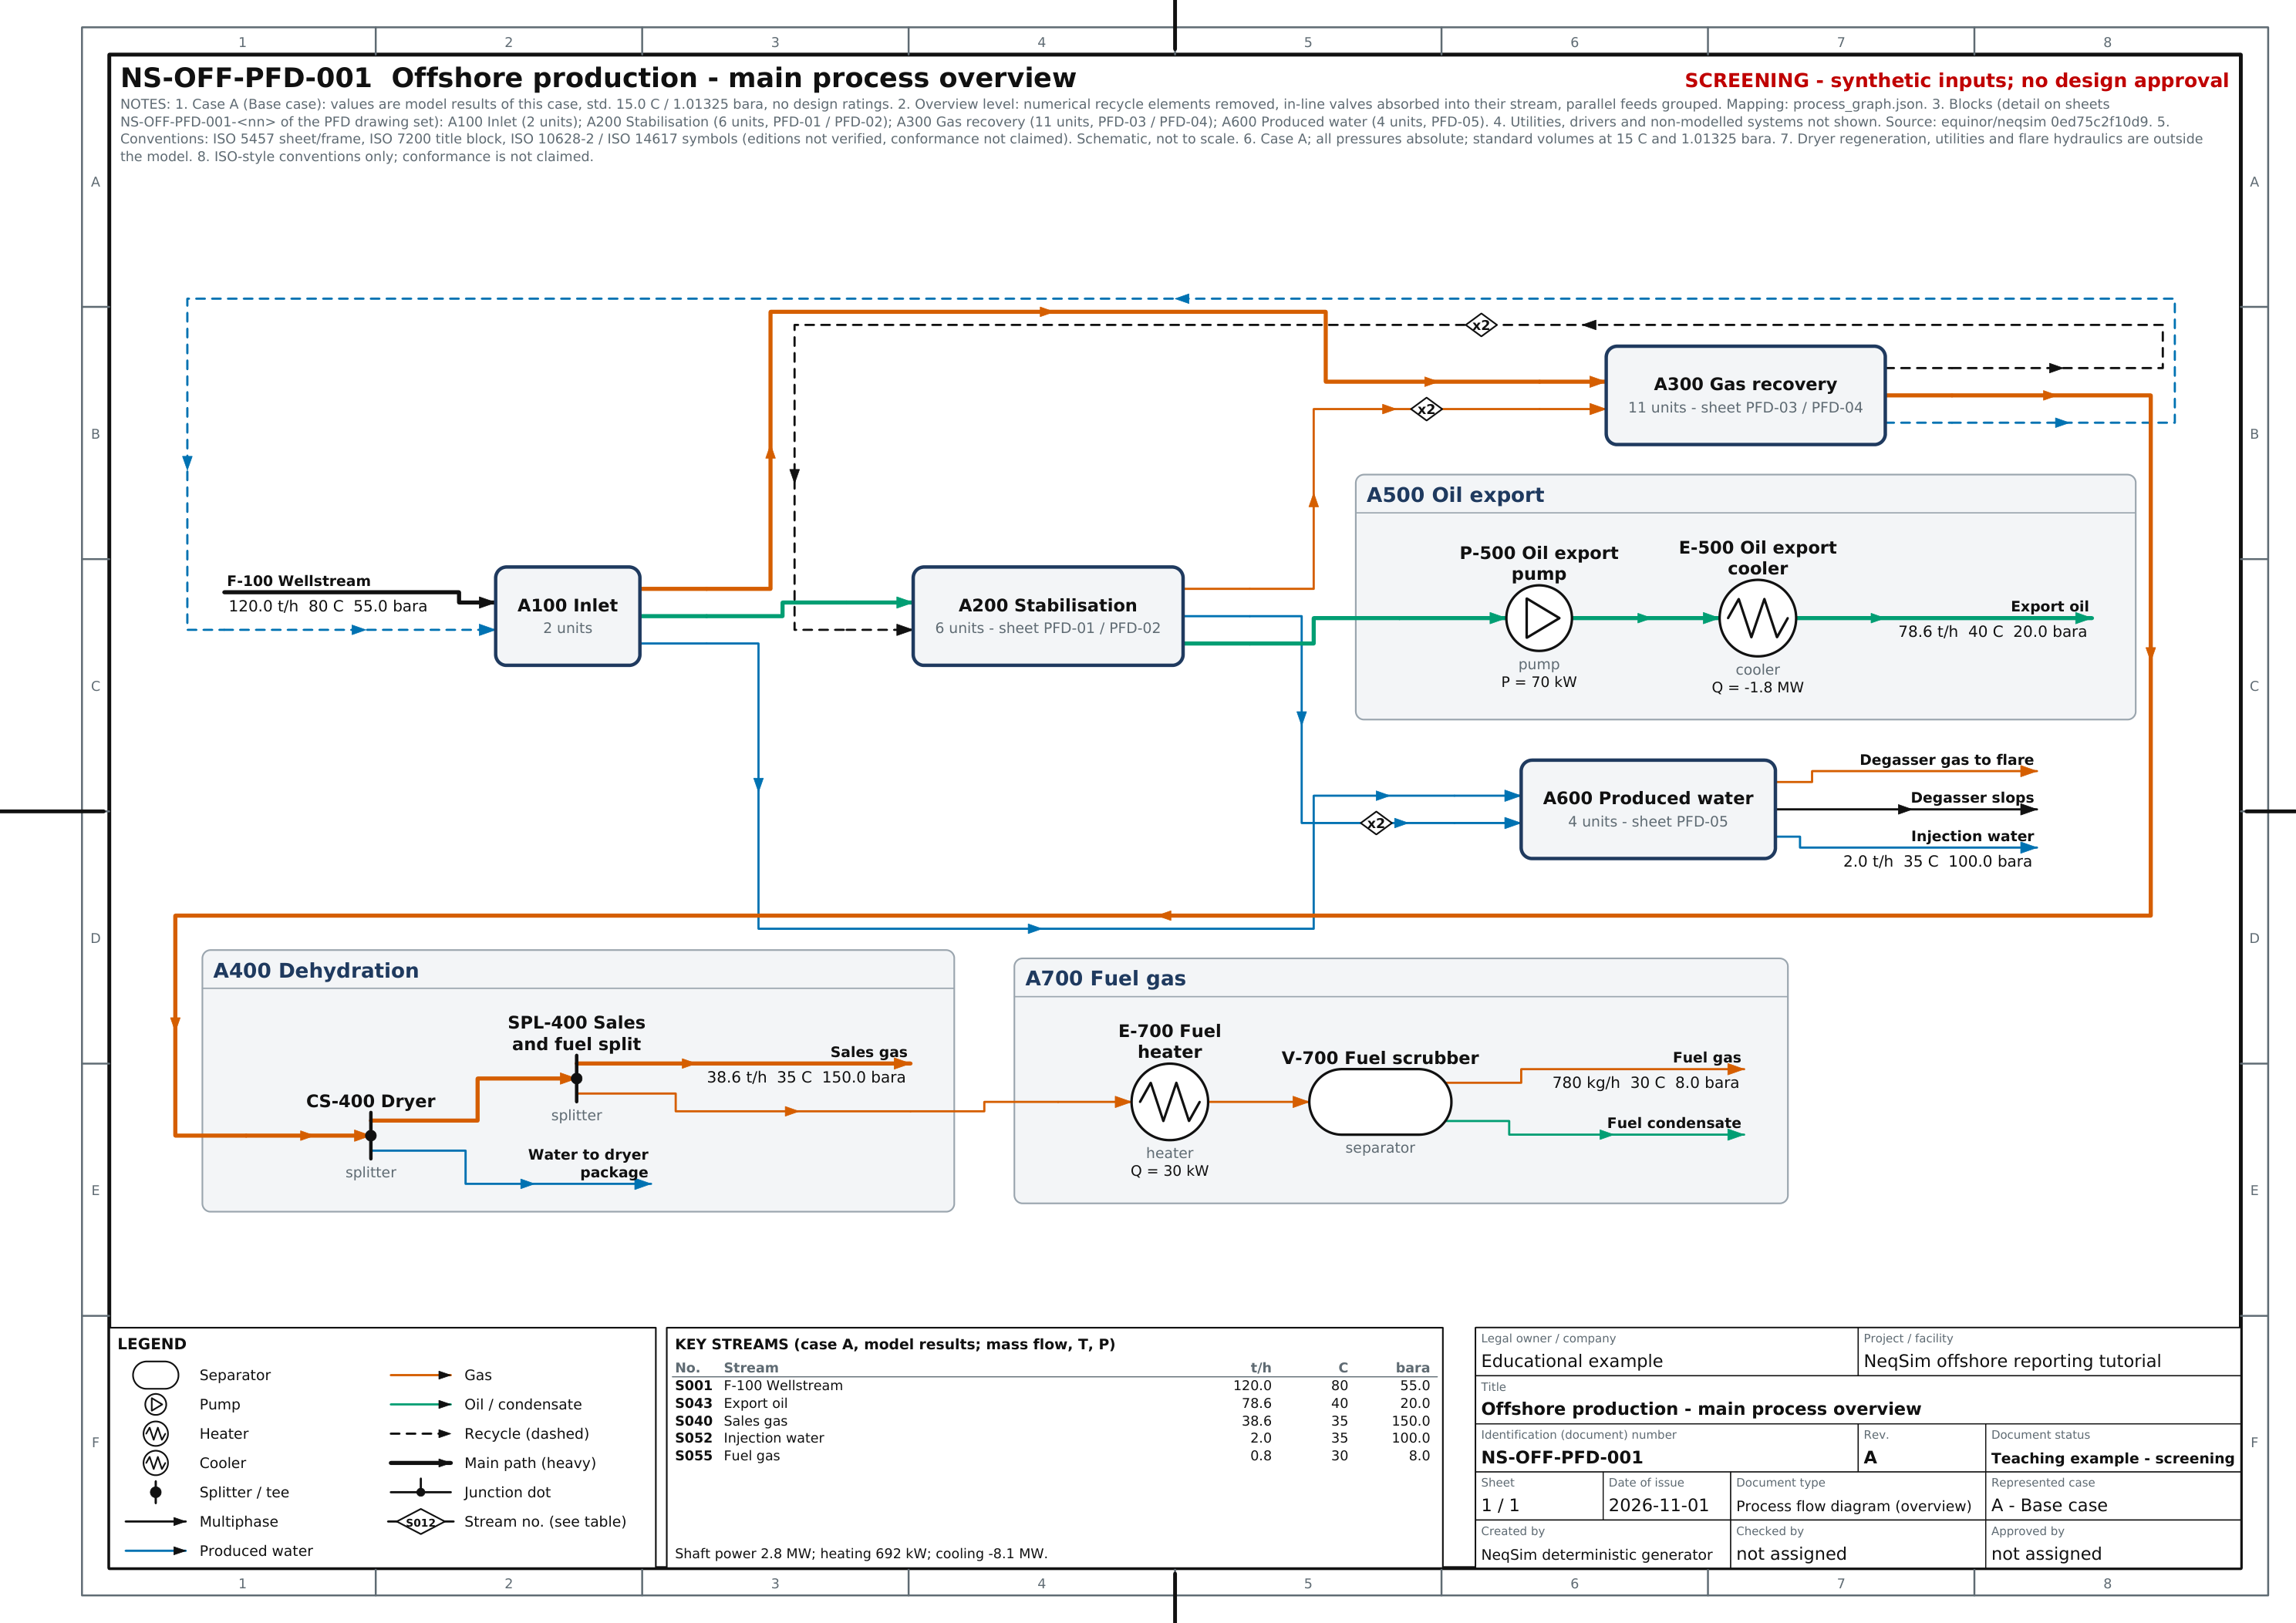

**overview_A3_mono.png**

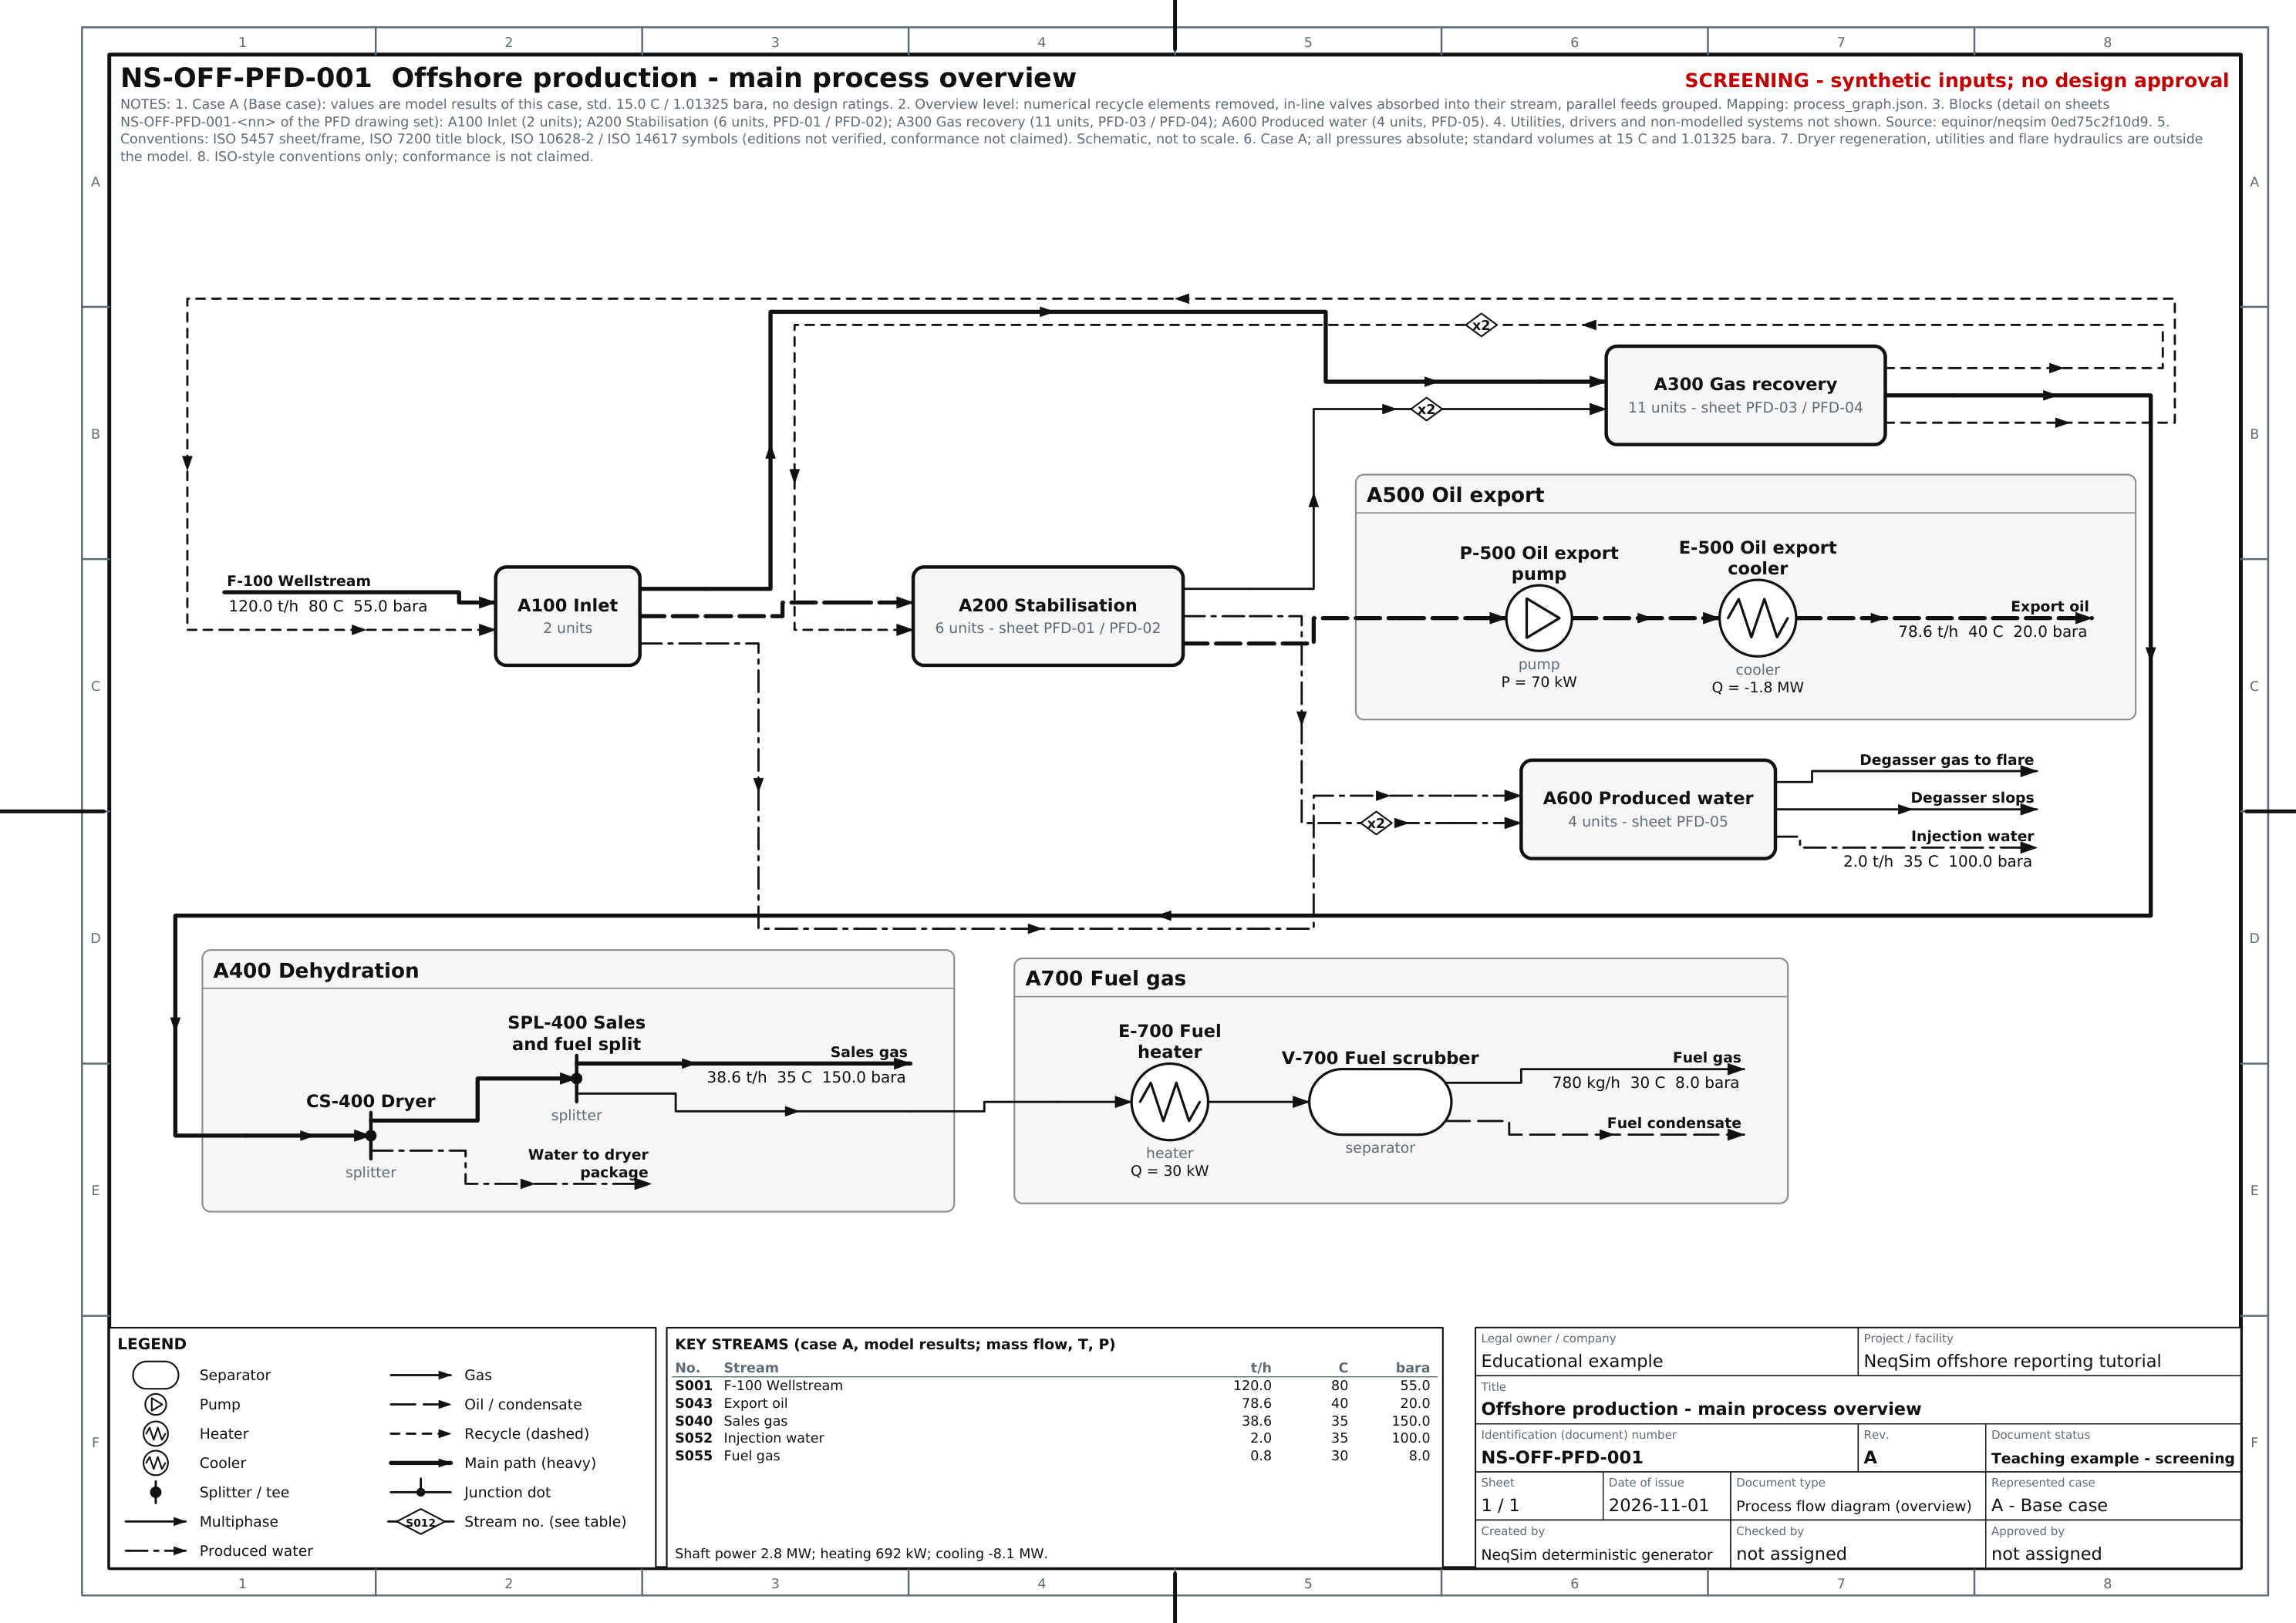

**overview_16x9.png**

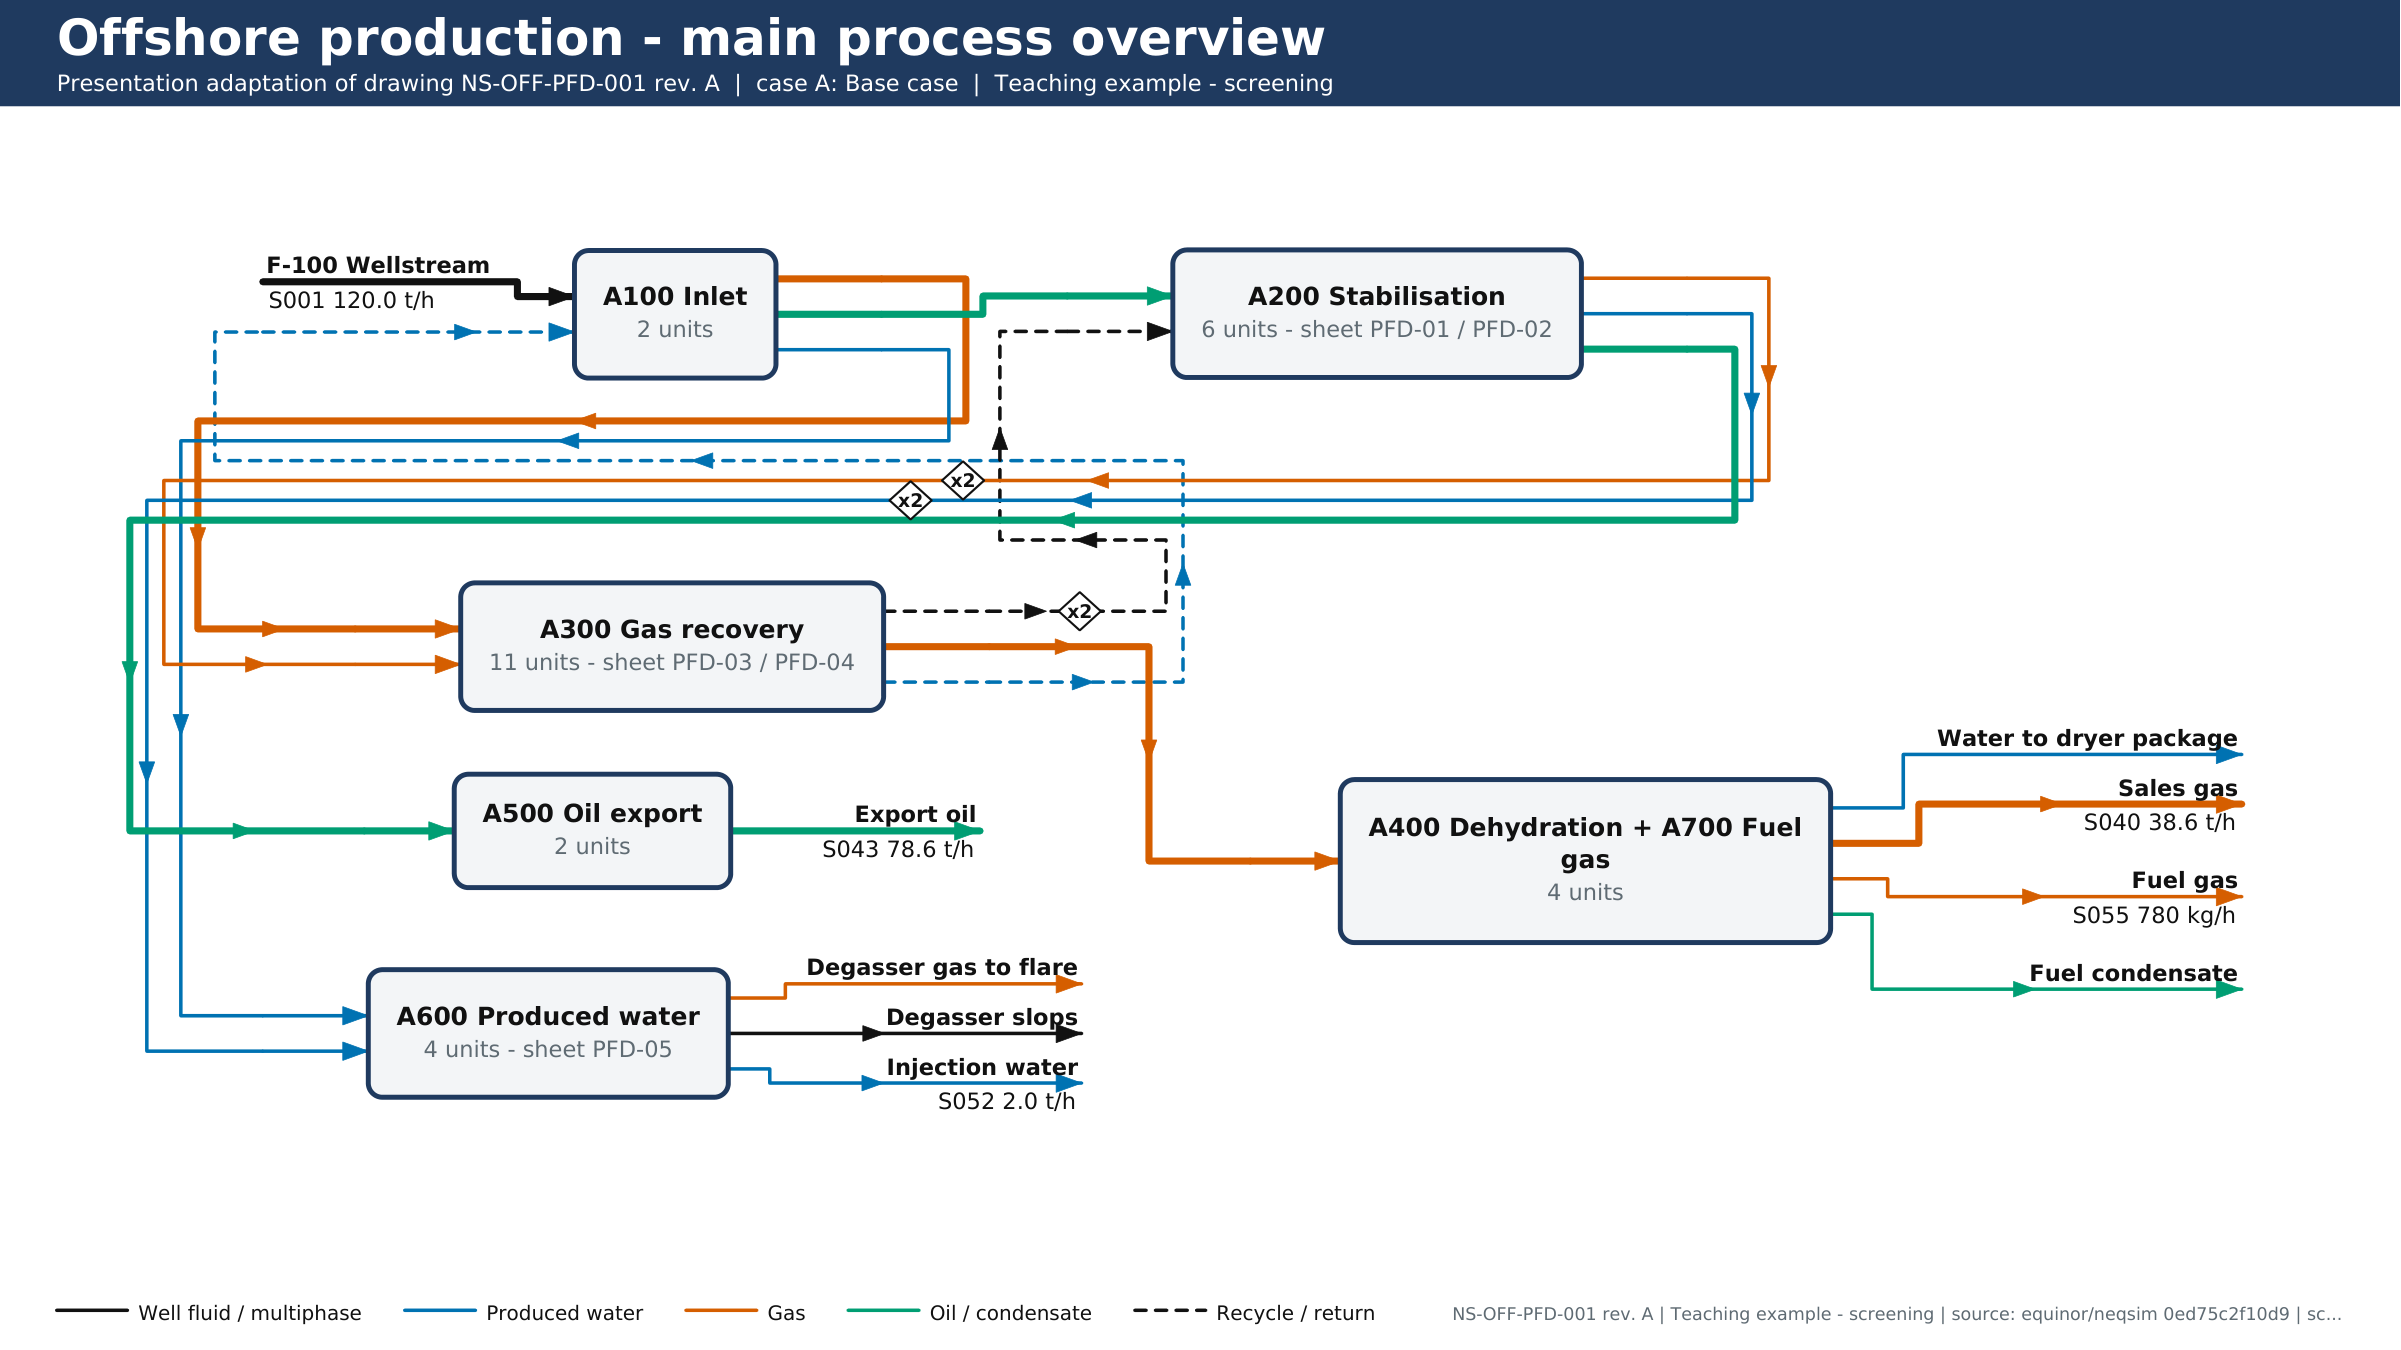

In [25]:
overview_title = {
    "company": "Educational example",
    "project": "NeqSim offshore reporting tutorial",
    "title": "Offshore production - main process overview",
    "document_number": "NS-OFF-PFD-001",
    "revision": "A",
    "issue_status": "Teaching example - screening",
    "date": "2026-11-01",
    "drawn_by": "NeqSim deterministic generator",
    "checked_by": "not assigned",
    "approved_by": "not assigned",
    "model_source": "equinor/neqsim " + source_sha[:12],
    "readiness_note": "SCREENING - synthetic inputs; no design approval",
    "notes": [
        "Case A; all pressures absolute; standard volumes at 15 C and 1.01325 bara.",
        "Dryer regeneration, utilities and flare hydraulics are outside the model.",
        "ISO-style conventions only; conformance is not claimed.",
    ],
}
layout_messages = []
overview_manifest = process_overview.build_overview(
    data,
    str(OUTPUT / "process_overview"),
    case_id="A",
    title_block=overview_title,
    level="overview",
    detail_sheets="collapsed",
    png_dpi=180,
    config={
        "annotate": [
            stream["id"]
            for stream in data["streams"]
            if stream["kind"] in ["feed", "product"]
            and stream["results"]["A"]["mass_kg_h"] >= 100.0
        ]
    },
    style_overrides={"notes_lines": 5},
    source_path=str(OUTPUT / "process_report" / "data" / "process_data.json"),
    log=layout_messages.append,
)
(OUTPUT / "process_overview" / "layout_generation.log").write_text("\n".join(layout_messages))
overview_validation = json.loads((OUTPUT / "process_overview" / "validation.json").read_text())
print("Overview validation:", overview_manifest.get("validation_status"))
display(pd.DataFrame(overview_validation.get("checks", [])))
assert overview_manifest["validation_status"] == "PASS"
detail_paths = sorted((OUTPUT / "process_overview" / "detail_sheets" / "sheets").glob("*.svg"))
detail_review = review_with_physical_notes(
    {"svg": report_summary["diagrams"]["bfd"]},
    {"sheets": [{"svg": str(path)} for path in detail_paths]},
    OUTPUT / "process_overview" / "detail_layout_review",
)
print("Overview detail-sheet layout:", detail_review)
assert detail_review["status"] == "PASS"
for filename in ["overview_A3_colour.png", "overview_A3_mono.png", "overview_16x9.png"]:
    image_path = OUTPUT / "process_overview" / filename
    display(Markdown("**" + filename + "**"))
    display(Image(filename=str(image_path), width=1400))


## 12. Read the report and reuse the evidence

The report contains document control, an executive summary, design basis, process description,
standards register, methodology, drawings, case comparisons, balances, assumptions and data
gaps. Appendices contain all-stream properties, phase fractions, overall and phase compositions,
component properties, equipment results and the validation report.

The excerpt below comes from the **generated Word document**, so it demonstrates the reporting
skill's output rather than a separately maintained executive summary.

In [26]:
from docx import Document
from html import escape

report_document = Document(report_summary["docx"])
excerpt = []
copying = False
for paragraph in report_document.paragraphs:
    if paragraph.text.startswith("1 Executive summary"):
        copying = True
    if copying and paragraph.text.startswith("2 "):
        break
    if copying and paragraph.text:
        excerpt.append(paragraph.text)
display(
    HTML(
        "<div style='border-left:4px solid #007A78;padding:12px 20px'>"
        + "".join("<p>" + escape(text) + "</p>" for text in excerpt)
        + "</div>"
    )
)

stream_rows = []
for stream in data["streams"]:
    result = stream["results"]["A"]
    stream_rows.append(
        {
            "Stream": stream["id"],
            "Label": stream["label"],
            "Kind": stream["kind"],
            "T (C)": result.get("t_c"),
            "P (bara)": result.get("p_bara"),
            "Flow (kg/h)": result.get("mass_kg_h"),
            "State": result.get("state"),
        }
    )
display(pd.DataFrame(stream_rows).round(3))


,Stream,Label,Kind,T (C),P (bara),Flow (kg/h),State
0,S001,F-100 Wellstream,feed,80.000,55.0,120000.000,gas+oil+aqueous
1,S002,R-100 HP condensate tear,internal,37.054,55.0,288.879,gas+aqueous
2,S003,M-100 HP feed mixer mixed stream,internal,79.833,55.0,120288.879,gas+oil+aqueous
3,S004,V-100 HP separator gas out,internal,79.833,55.0,35721.397,gas
4,S005,V-100 HP separator liquid out,internal,79.833,55.0,82804.962,oil
5,S006,V-100 HP separator water out,internal,79.833,55.0,1762.520,aqueous
6,S007,LV-101 MP letdown out stream,internal,78.079,12.0,82804.962,gas+oil
7,S008,R-101 MP condensate tear,internal,30.016,12.0,80.145,gas+oil+aqueous
8,S009,M-101 MP feed mixer mixed stream,internal,77.799,12.0,82885.107,gas+oil+aqueous
9,S010,E-101 MP cooler out,internal,65.000,12.0,82885.107,gas+oil+aqueous


## 13. Conclusions, limits and exercises

Use the case comparison to identify the largest power consumer and the change in duties and
products at higher throughput. The high-rate case changes duty at
fixed equipment efficiencies; it does **not** demonstrate spare capacity without mechanical
ratings, maps and control restrictions.

The delivered evidence establishes execution, connectivity, inventory closure, energy checks
and the water-pump power scale. It does not establish agreement with an offshore plant or a
vendor guarantee. Before project use, replace the synthetic fluid with measured PVT and a tuned
heavy-end model; close the data gaps; check vapour pressure, hydrocarbon/water dew points,
water quality, compressor maps, utilities, safety and equipment ratings.

Suggested exercises:

1. Change a separator pressure and regenerate all reports and diagrams from the new case.
2. Vary the stated dryer capture fraction and compare gas water content and package heat.
3. Add mechanical capacity limits before interpreting the high-rate case as feasible capacity.
4. Replace the dryer performance assumption with a qualified TEG absorption and regeneration model.
5. Add a measured PVT case and separate calibration evidence from independent hold-out validation.

**Documentation impact:** this tutorial adds an executed end-to-end example, report-basis files,
catalog links and maintenance evidence. It changes no NeqSim Java model or public API.

**Tracked NeqSim improvements:** the external driver-label layout adapter addresses
[#4793](https://github.com/equinor/neqsim/issues/4793); readable small-flow labels address
[#4794](https://github.com/equinor/neqsim/issues/4794). Optional supporting presentation detail
slides are excluded because their native export can clip content without a validation failure
([#4795](https://github.com/equinor/neqsim/issues/4795)); use the complete A3 detail drawing set.
Detailed association-model qualification belongs to the existing
[flash-stability campaign #2937](https://github.com/equinor/neqsim/issues/2937).
The SRK model and explicit dryer assumption above define the scope of the reported results.

**Validation of this edition:** all 27 code cells were executed in order in a fresh process,
using a hash-verified source-built runtime and the pinned reporting toolkit. Stored outputs
include both operating cases, independent conservation and pump-power checks, the native
39-check report assessment, 12 report drawing-sheet reviews and the overview assessment.
The native report has 36 passes, three explained warnings and no failed checks. The notebook,
formulae, tables and issued diagrams were also rendered for visual inspection.

In [27]:
import shutil

products_table.to_csv(OUTPUT / "boundary_products.csv", index=False)
utility_table.to_csv(OUTPUT / "utilities.csv")
independent_table.to_csv(OUTPUT / "independent_checks.csv", index=False)
(OUTPUT / "runtime_provenance.json").write_text(
    json.dumps(
        {
            "source_commit": source_sha,
            "jar_sha256": jar_sha256,
            "class_origin": class_origin,
            "build_method": build_method,
            "python": sys.version.split()[0],
            "java": str(jpype.java.lang.System.getProperty("java.version")),
        },
        indent=2,
    )
)
archive = shutil.make_archive(str(OUTPUT.parent / "Offshore_Process_Report_Package"), "zip", OUTPUT)
for label, path in [
    ("Complete report package", Path(archive)),
    ("Word process-study report", Path(report_summary["docx"])),
    ("Detailed A3 PFD drawing set", Path(report_summary["diagrams"]["pfd_pdf"])),
    ("A3 overview PDF", OUTPUT / "process_overview" / "overview_A3_colour.pdf"),
    ("Presentation diagram PDF", OUTPUT / "process_overview" / "overview_16x9.pdf"),
]:
    display(Markdown("**" + label + "**"))
    display(FileLink(str(path)))
if "google.colab" in sys.modules:
    from google.colab import files

    display(Markdown("Download the complete package with `files.download(archive)`."))
print("All process, report and drawing outputs are stored in:", OUTPUT)


All process, report and drawing outputs are stored in: /workspace/scratch/173328b47b0e/offshore_study_deliverables


**Complete report package**

/workspace/scratch/173328b47b0e/Offshore_Process_Report_Package.zip

**Word process-study report**

/workspace/scratch/173328b47b0e/offshore_study_deliverables/process_report/report/NS-OFF-REP-001_revA.docx

**Detailed A3 PFD drawing set**

/workspace/scratch/173328b47b0e/offshore_study_deliverables/process_report/diagrams/pfd/pfd_drawing_set.pdf

**A3 overview PDF**

/workspace/scratch/173328b47b0e/offshore_study_deliverables/process_overview/overview_A3_colour.pdf

**Presentation diagram PDF**

/workspace/scratch/173328b47b0e/offshore_study_deliverables/process_overview/overview_16x9.pdf

## References and skill provenance

- [NeqSim process-study-report skill](https://github.com/equinor/neqsim/blob/0ed75c2f10d9030ec8d9270c51e4ade28f5603f8/.github/skills/process-study-report/SKILL.md)
- [Professional process overview skill](https://github.com/equinor/neqsim/blob/0ed75c2f10d9030ec8d9270c51e4ade28f5603f8/.github/skills/professional-process-overview/SKILL.md)
- [PFD layout review skill](https://github.com/equinor/neqsim/blob/0ed75c2f10d9030ec8d9270c51e4ade28f5603f8/.github/skills/neqsim-pfd-layout-review/SKILL.md)
- [Professional reporting principles](https://github.com/equinor/neqsim/blob/0ed75c2f10d9030ec8d9270c51e4ade28f5603f8/.github/skills/neqsim-professional-reporting/SKILL.md)
- [Process-study-report documentation](https://github.com/equinor/neqsim/blob/0ed75c2f10d9030ec8d9270c51e4ade28f5603f8/docs/development/PROCESS_STUDY_REPORT.md)
- [ISO 10628-1:2014 catalogue](https://www.iso.org/standard/51840.html), flow-diagram content and representation.
- [ISO 10628-2:2012 catalogue](https://www.iso.org/standard/51841.html), graphical symbols.
- [Standards Norway: NORSOK P-process standards](https://standard.no/en/sectors/petroleum/norsok-standards/p-process/), P-002:2023+AC:2024.

Catalogue status was checked on 1 November 2026. Catalogue access does not constitute access
to the full standard or a conformance assessment. All fluid data and operating cases are
synthetic and openly specified in this notebook.